In [1]:
!pip install requests pandas openpyxl


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

from pathlib import Path
from urllib.parse import quote
import requests

ROOT = Path.cwd() / "Retail_Accounting_2024"
RAW = ROOT / "00_Raw_Data" / "retail-output"
RAW.mkdir(parents=True, exist_ok=True)

FILES = [
    "chart_of_accounts.json",
    "journal_entries.json",
    "balance_validation.json",
    "generation_statistics.json",
    "document_flows/vendor_invoices.json",
    "document_flows/customer_invoices.json",
    "document_flows/payments.json",
    "subledger/ap_invoices.json",
    "subledger/ar_invoices.json",
    "subledger/inventory_positions.json",
    "balance/subledger_reconciliation.json",
]

BASES = [
    "https://raw.githubusercontent.com/meghahonna/erp_data_sample/main/retail-output/",
    "https://media.githubusercontent.com/media/meghahonna/erp_data_sample/main/retail-output/",
]

def download_file(relative_path):
    destination = RAW / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    temp = destination.with_suffix(destination.suffix + ".part")

    for base in BASES:
        try:
            with requests.get(
                base + quote(relative_path, safe="/"),
                stream=True,
                timeout=(20, 180)
            ) as response:
                response.raise_for_status()

                with open(temp, "wb") as f:
                    for chunk in response.iter_content(1024 * 1024):
                        if chunk:
                            f.write(chunk)

            with open(temp, "rb") as f:
                header = f.read(100)

            # Reject Git LFS pointer files
            if header.startswith(b"version https://git-lfs.github.com/spec/v1"):
                temp.unlink()
                continue

            if temp.stat().st_size == 0:
                temp.unlink()
                continue

            temp.replace(destination)
            print("OK:", relative_path,
                  round(destination.stat().st_size / 1024**2, 2), "MB")
            return True

        except requests.RequestException as e:
            print("Retry:", relative_path, str(e)[:100])
            temp.unlink(missing_ok=True)

    print("FAILED:", relative_path)
    return False

results = {name: download_file(name) for name in FILES}

print("\nDownloaded:", sum(results.values()), "/", len(FILES))


OK: chart_of_accounts.json 2.38 MB
OK: journal_entries.json 161.89 MB
OK: balance_validation.json 0.0 MB
OK: generation_statistics.json 0.0 MB
OK: document_flows/vendor_invoices.json 0.21 MB
OK: document_flows/customer_invoices.json 0.14 MB
OK: document_flows/payments.json 0.21 MB
OK: subledger/ap_invoices.json 0.13 MB
OK: subledger/ar_invoices.json 0.08 MB
OK: subledger/inventory_positions.json 0.08 MB
OK: balance/subledger_reconciliation.json 0.0 MB

Downloaded: 11 / 11


In [3]:
import pandas as pd

inventory = pd.DataFrame([
    {
        "File": f,
        "Downloaded": (RAW / f).exists(),
        "Size_MB": round((RAW / f).stat().st_size / 1024**2, 2)
                   if (RAW / f).exists() else 0
    }
    for f in FILES
])

display(inventory)

,File,Downloaded,Size_MB
0,chart_of_accounts.json,True,2.38
1,journal_entries.json,True,161.89
2,balance_validation.json,True,0.00
3,generation_statistics.json,True,0.00
4,document_flows/vendor_invoices.json,True,0.21
5,document_flows/customer_invoices.json,True,0.14
6,document_flows/payments.json,True,0.21
7,subledger/ap_invoices.json,True,0.13
8,subledger/ar_invoices.json,True,0.08
9,subledger/inventory_positions.json,True,0.08


In [ ]:
from pathlib import Path
from collections import Counter
from itertools import islice
import json
import ijson


# Dùng lại biến RAW của Phase 0
RAW = Path.cwd() / "Retail_Accounting_2024" / "00_Raw_Data" / "retail-output"

# Đọc Chart of Accounts
with open(RAW / "chart_of_accounts.json", encoding="utf-8") as f:
    coa = json.load(f)

print("COA type:", type(coa).__name__)
print("COA keys:", list(coa.keys()) if isinstance(coa, dict) else "List")
print("COA records:", len(coa))

# Xác định đường dẫn đến các journal entries trong JSON
journal_path = RAW / "journal_entries.json"

def detect_prefix(path):
    with open(path, "rb") as f:
        first = f.read(200).lstrip()[:1]

    if first == b"[":
        return "item"

    if first == b"{":
        with open(path, "rb") as f:
            for prefix, event, value in ijson.parse(f):
                if event == "start_array" and prefix and "." not in prefix:
                    return prefix + ".item"

    raise ValueError("Không nhận diện được cấu trúc Journal JSON")

PREFIX = detect_prefix(journal_path)

def read_journals():
    with open(journal_path, "rb") as f:
        yield from ijson.items(f, PREFIX)

sample = next(read_journals())

header = sample.get("header", sample)
lines = sample.get("lines", [])

print("\nJournal structure:", list(sample.keys()))
print("Header columns:", list(header.keys()))
print("Line columns:", list(lines[0].keys()) if lines else [])
print("Example header:")
print({k: header.get(k) for k in
       ["document_id", "company_code", "posting_date",
        "currency", "document_type", "business_process"]})


Note: you may need to restart the kernel to use updated packages.
COA type: dict
COA keys: ['coa_id', 'name', 'country', 'industry', 'accounts', 'complexity', 'account_format']
COA records: 7

Journal structure: ['header', 'lines']
Header columns: ['document_id', 'company_code', 'fiscal_year', 'fiscal_period', 'posting_date', 'document_date', 'created_at', 'document_type', 'currency', 'exchange_rate', 'reference', 'header_text', 'created_by', 'user_persona', 'source', 'business_process', 'ledger', 'is_fraud', 'fraud_type', 'is_anomaly', 'anomaly_id', 'anomaly_type', 'batch_id', 'control_ids', 'sox_relevant', 'control_status', 'sod_violation', 'sod_conflict_type', 'approval_workflow', 'ocpm_event_ids', 'ocpm_object_ids', 'ocpm_case_id']
Line columns: ['document_id', 'line_number', 'gl_account', 'account_code', 'account_description', 'debit_amount', 'credit_amount', 'local_amount', 'group_amount', 'cost_center', 'profit_center', 'segment', 'functional_area', 'line_text', 'text', 'referen


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

from collections import Counter
import pandas as pd

# Kiểm tra Chart of Accounts
print("COA Information:")
for key in ["name", "country", "industry", "complexity"]:
    print(f"{key}: {coa.get(key)}")

print("Accounts count:", len(coa["accounts"]))

# Thống kê công ty, năm và tiền tệ
counts = Counter()

for entry in read_journals():
    h = entry["header"]
    counts[(
        str(h.get("company_code")),
        str(h.get("fiscal_year")),
        str(h.get("currency"))
    )] += 1

summary = pd.DataFrame([
    {
        "Company": company,
        "Year": year,
        "Currency": currency,
        "Journal_Entries": count
    }
    for (company, year, currency), count in counts.items()
])

display(summary.sort_values(
    ["Company", "Year", "Currency"]
))


COA Information:
name: Retail Chart of Accounts
country: US
industry: retail
complexity: large
Accounts count: 2353


,Company,Year,Currency,Journal_Entries
0,1000,2024,USD,7669
3,1000,2025,USD,162
1,2000,2024,USD,7310
2,2000,2025,USD,151


In [6]:

headers = []
lines = []

for entry in read_journals():
    h = entry["header"]

    if str(h["company_code"]) != "1000":
        continue

    date = pd.to_datetime(
        h["posting_date"], errors="coerce"
    )

    if pd.isna(date) or date.year != 2024:
        continue

    headers.append(h)

    for line in entry["lines"]:
        lines.append({
            **line,
            "header_document_id": h["document_id"],
            "posting_date": date
        })

H = pd.DataFrame(headers)
L = pd.DataFrame(lines)

print("Total Journal Entries:", len(H))
print("Total Journal Lines:", len(L))
print("Unique Accounts:", L["gl_account"].nunique())

display(H.head(3))
display(L.head(3))


Total Journal Entries: 7669
Total Journal Lines: 81839
Unique Accounts: 2103


,document_id,company_code,fiscal_year,fiscal_period,posting_date,document_date,created_at,document_type,currency,exchange_rate,...,batch_id,control_ids,sox_relevant,control_status,sod_violation,sod_conflict_type,approval_workflow,ocpm_event_ids,ocpm_object_ids,ocpm_case_id
0,8b21131e-81ce-4014-aa23-cbfb7c68ec14,1000,2024,1,2024-01-19,2024-01-19,2026-03-09T21:16:55.436497Z,WE,USD,1,...,None,[],False,effective,False,None,None,[],[],None
1,6ad72313-7807-46f5-b3ef-a88886ece6fa,1000,2024,1,2024-01-25,2024-01-25,2026-03-09T21:16:55.436501Z,KR,USD,1,...,None,[],False,effective,False,None,None,[],[],None
2,498d3408-6f40-4bd6-98ba-2abaad38a4bd,1000,2024,2,2024-02-21,2024-02-21,2026-03-09T21:16:55.436504Z,KZ,USD,1,...,None,[],False,effective,False,None,None,[],[],None


,document_id,line_number,gl_account,account_code,account_description,debit_amount,credit_amount,local_amount,group_amount,cost_center,...,assignment,offsetting_account,is_suspense,trading_partner,quantity,unit_of_measure,unit,project_code,header_document_id,posting_date
0,8b21131e-81ce-4014-aa23-cbfb7c68ec14,1,1200,1200,Inventory,758551.84,0,758551.84,None,None,...,None,None,False,None,None,None,None,None,8b21131e-81ce-4014-aa23-cbfb7c68ec14,2024-01-19
1,8b21131e-81ce-4014-aa23-cbfb7c68ec14,2,2900,2900,GR/IR Clearing,0,758551.84,-758551.84,None,None,...,None,None,False,None,None,None,None,None,8b21131e-81ce-4014-aa23-cbfb7c68ec14,2024-01-19
2,6ad72313-7807-46f5-b3ef-a88886ece6fa,1,2900,2900,GR/IR Clearing,758551.84,0,758551.84,None,None,...,None,None,False,None,None,None,None,None,6ad72313-7807-46f5-b3ef-a88886ece6fa,2024-01-25


In [7]:

# Chuẩn hóa ngày để kiểm tra
posting = pd.to_datetime(H["posting_date"], errors="coerce")
doc_date = pd.to_datetime(H["document_date"], errors="coerce")

checks = {
    "Duplicate Journal IDs":
        H["document_id"].duplicated().sum(),

    "Missing Document IDs":
        H["document_id"].isna().sum(),

    "Missing GL Accounts":
        L["gl_account"].isna().sum(),

    "Missing Debit Amount":
        L["debit_amount"].isna().sum(),

    "Missing Credit Amount":
        L["credit_amount"].isna().sum(),

    "Duplicate Journal Lines":
        L.duplicated(
            ["header_document_id", "line_number"]
        ).sum(),

    "Invalid Posting Dates":
        posting.isna().sum(),

    "Fiscal Year Mismatch":
        (pd.to_numeric(H["fiscal_year"], errors="coerce")
         != posting.dt.year).sum(),

    "Fiscal Period Mismatch":
        (pd.to_numeric(H["fiscal_period"], errors="coerce")
         != posting.dt.month).sum(),

    "Header-Line ID Mismatch":
        (L["document_id"] != L["header_document_id"]).sum(),

    "Entries Without Lines":
        (~H["document_id"].isin(L["header_document_id"])).sum()
}

quality_report = pd.DataFrame(
    checks.items(),
    columns=["Check", "Issue_Count"]
)

display(quality_report)


,Check,Issue_Count
0,Duplicate Journal IDs,0
1,Missing Document IDs,0
2,Missing GL Accounts,0
3,Missing Debit Amount,0
4,Missing Credit Amount,0
5,Duplicate Journal Lines,0
6,Invalid Posting Dates,0
7,Fiscal Year Mismatch,0
8,Fiscal Period Mismatch,0
9,Header-Line ID Mismatch,80


In [8]:

mismatch = L[
    L["document_id"] != L["header_document_id"]
].copy()

print("Mismatched Lines:", len(mismatch))
print("Affected Journal Entries:",
      mismatch["header_document_id"].nunique())

display(mismatch[[
    "header_document_id",
    "document_id",
    "line_number",
    "gl_account",
    "debit_amount",
    "credit_amount"
]].head(10))

# Kiểm tra các bút toán này có bị đánh dấu bất thường không
flags = H[[
    "document_id", "is_anomaly",
    "anomaly_type", "is_fraud",
    "control_status"
]]

review = mismatch.merge(
    flags,
    left_on="header_document_id",
    right_on="document_id",
    how="left",
    suffixes=("_line", "_header")
)

display(review[[
    "header_document_id", "is_anomaly",
    "anomaly_type", "is_fraud",
    "control_status"
]].head(10))


Mismatched Lines: 80
Affected Journal Entries: 40


,header_document_id,document_id,line_number,gl_account,debit_amount,credit_amount
81759,019cd475-cb0c-7b40-8468-046ad440dc21,00000000-0000-0000-0000-000000000000,1,1540,56299.22,0
81760,019cd475-cb0c-7b40-8468-046ad440dc21,00000000-0000-0000-0000-000000000000,2,1599,0,56299.22
81761,019cd475-cb0c-7b40-8468-04717d0d1bd7,00000000-0000-0000-0000-000000000000,1,1530,62925.49,0
81762,019cd475-cb0c-7b40-8468-04717d0d1bd7,00000000-0000-0000-0000-000000000000,2,1599,0,62925.49
81763,019cd475-cb0c-7b40-8468-04826b4a0a90,00000000-0000-0000-0000-000000000000,1,1590,76879.65,0
81764,019cd475-cb0c-7b40-8468-04826b4a0a90,00000000-0000-0000-0000-000000000000,2,1599,0,76879.65
81765,019cd475-cb0c-7b40-8468-04986f4f04a7,00000000-0000-0000-0000-000000000000,1,1590,55874.55,0
81766,019cd475-cb0c-7b40-8468-04986f4f04a7,00000000-0000-0000-0000-000000000000,2,1599,0,55874.55
81767,019cd475-cb0c-7b40-8468-04adbc18fc0e,00000000-0000-0000-0000-000000000000,1,1590,55020.53,0
81768,019cd475-cb0c-7b40-8468-04adbc18fc0e,00000000-0000-0000-0000-000000000000,2,1599,0,55020.53


,header_document_id,is_anomaly,anomaly_type,is_fraud,control_status
0,019cd475-cb0c-7b40-8468-046ad440dc21,False,None,False,effective
1,019cd475-cb0c-7b40-8468-046ad440dc21,False,None,False,effective
2,019cd475-cb0c-7b40-8468-04717d0d1bd7,False,None,False,effective
3,019cd475-cb0c-7b40-8468-04717d0d1bd7,False,None,False,effective
4,019cd475-cb0c-7b40-8468-04826b4a0a90,False,None,False,effective
5,019cd475-cb0c-7b40-8468-04826b4a0a90,False,None,False,effective
6,019cd475-cb0c-7b40-8468-04986f4f04a7,False,None,False,effective
7,019cd475-cb0c-7b40-8468-04986f4f04a7,False,None,False,effective
8,019cd475-cb0c-7b40-8468-04adbc18fc0e,False,None,False,effective
9,019cd475-cb0c-7b40-8468-04adbc18fc0e,False,None,False,effective


In [10]:

# CODE 6 — Kiểm tra 40 Journal Entries bị mismatch

# 1. Tạo bản sao, không thay đổi dữ liệu gốc
mismatch = L[
    L["document_id"] != L["header_document_id"]
].copy()

# 2. Chuyển Debit/Credit thành số
for col in ["debit_amount", "credit_amount"]:
    mismatch[col] = pd.to_numeric(mismatch[col], errors="coerce")

# 3. Kiểm tra giá trị không chuyển đổi được
print("Invalid Debit:", mismatch["debit_amount"].isna().sum())
print("Invalid Credit:", mismatch["credit_amount"].isna().sum())

# 4. Tổng hợp theo từng Journal Entry
review_40 = mismatch.groupby(
    "header_document_id"
).agg(
    Lines=("line_number", "count"),
    Debit=("debit_amount", "sum"),
    Credit=("credit_amount", "sum")
).reset_index()

# 5. Tính chênh lệch
review_40["Difference"] = (
    review_40["Debit"] - review_40["Credit"]
).round(2)

review_40["Status"] = review_40["Difference"].apply(
    lambda x: "PASS" if abs(x) <= 0.01 else "REVIEW"
)

# 6. Hiển thị kết quả
print("Mismatched Lines:", len(mismatch))
print("Affected Entries:", len(review_40))
print("Unbalanced Entries:",
      (review_40["Status"] == "REVIEW").sum())

display(review_40.head(10))
display(review_40["Status"].value_counts())


Invalid Debit: 0
Invalid Credit: 0
Mismatched Lines: 80
Affected Entries: 40
Unbalanced Entries: 0


,header_document_id,Lines,Debit,Credit,Difference,Status
0,019cd475-cb0c-7b40-8468-046ad440dc21,2,56299.22,56299.22,0.0,PASS
1,019cd475-cb0c-7b40-8468-04717d0d1bd7,2,62925.49,62925.49,0.0,PASS
2,019cd475-cb0c-7b40-8468-04826b4a0a90,2,76879.65,76879.65,0.0,PASS
3,019cd475-cb0c-7b40-8468-04986f4f04a7,2,55874.55,55874.55,0.0,PASS
4,019cd475-cb0c-7b40-8468-04adbc18fc0e,2,55020.53,55020.53,0.0,PASS
5,019cd475-cb0c-7b40-8468-04bbfe88fbd8,2,41479.88,41479.88,0.0,PASS
6,019cd475-cb0c-7b40-8468-04c971bb98ae,2,22108.13,22108.13,0.0,PASS
7,019cd475-cb0c-7b40-8468-04d9ec29ec55,2,28494.65,28494.65,0.0,PASS
8,019cd475-cb0c-7b40-8468-04e8036cb83b,2,77059.99,77059.99,0.0,PASS
9,019cd475-cb0c-7b40-8468-04f0840eb0bb,2,32268.18,32268.18,0.0,PASS


Status
PASS    40
Name: count, dtype: int64

In [11]:

import pandas as pd
import numpy as np

# 1. Tạo bản sao
GL = L.copy()

# 2. Chuyển Debit và Credit thành số
for col in ["debit_amount", "credit_amount"]:
    GL[col] = pd.to_numeric(
        GL[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

# 3. Kiểm tra dữ liệu tiền không hợp lệ
invalid = GL[
    GL[["debit_amount", "credit_amount"]].isna().any(axis=1)
]

print("Invalid Amount Lines:", len(invalid))

if not invalid.empty:
    raise ValueError("Có số tiền không hợp lệ. Cần xử lý trước khi tiếp tục.")

# 4. Tổng hợp Debit/Credit theo bút toán
JE_check = GL.groupby(
    "header_document_id", as_index=False
).agg(
    Total_Lines=("line_number", "count"),
    Total_Debit=("debit_amount", "sum"),
    Total_Credit=("credit_amount", "sum")
)

# 5. Tính chênh lệch
JE_check["Difference"] = (
    JE_check["Total_Debit"] - JE_check["Total_Credit"]
).round(2)

JE_check["Status"] = np.where(
    JE_check["Difference"].abs() <= 0.01,
    "PASS",
    "REVIEW"
)

# 6. Summary
print("Total Journal Entries:", len(JE_check))
print("Total Debit:", round(JE_check["Total_Debit"].sum(), 2))
print("Total Credit:", round(JE_check["Total_Credit"].sum(), 2))
print("Unbalanced Entries:",
      (JE_check["Status"] == "REVIEW").sum())

display(JE_check["Status"].value_counts())
display(JE_check.head(10))

# 7. Xem các bút toán không cân bằng
unbalanced = JE_check[
    JE_check["Status"] == "REVIEW"
].sort_values("Difference", key=abs, ascending=False)

display(unbalanced.head(20))


Invalid Amount Lines: 0
Total Journal Entries: 7669
Total Debit: 216906648.68
Total Credit: 216906648.68
Unbalanced Entries: 0


Status
PASS    7669
Name: count, dtype: int64

,header_document_id,Total_Lines,Total_Debit,Total_Credit,Difference,Status
0,0004c4ed-9dfd-42da-b9ed-205f25b7939b,2,100.0,100.0,0.0,PASS
1,0009b22d-6237-4e45-a504-6083e034bdad,2,45.0,45.0,0.0,PASS
2,0015eaab-1fb6-4484-83ab-945587362ba4,2,2620.0,2620.0,0.0,PASS
3,001eb317-eae0-4685-ba93-e3f205a56362,2,98.87,98.87,0.0,PASS
4,001faa4e-b017-4959-a40d-54d06cf7ffcb,3,6239.35,6239.35,0.0,PASS
5,00284515-72cd-4adc-993b-7f8a141736f3,4,3.04,3.04,0.0,PASS
6,002e1ef6-9deb-41f9-ae1f-7a531a4a715d,98,10521.73,10521.73,0.0,PASS
7,00327ac4-1780-4d9e-af52-2c1e50b3667f,2,3300.0,3300.0,0.0,PASS
8,003e8d3e-9411-4328-a541-2cce98c08491,2,100.0,100.0,0.0,PASS
9,005154b3-6bdf-4000-af37-e408b1f88590,2,500.0,500.0,0.0,PASS


,header_document_id,Total_Lines,Total_Debit,Total_Credit,Difference,Status


In [12]:

# Đọc danh sách tài khoản từ COA
accounts = coa["accounts"]

if isinstance(accounts, list):
    COA = pd.json_normalize(accounts)
elif isinstance(accounts, dict):
    COA = pd.DataFrame.from_dict(
        accounts, orient="index"
    ).reset_index(names="account_key")
else:
    raise TypeError("Unknown COA structure")

print("COA columns:", list(COA.columns))
display(COA.head(3))

# Xác định cột mã tài khoản
candidates = [
    "account_code", "gl_account", "account_number",
    "account_id", "code", "account_key"
]

account_col = next(
    (c for c in candidates if c in COA.columns),
    None
)

if account_col is None:
    raise ValueError("Cần xác định cột mã tài khoản trong COA")

# Chuẩn hóa mã tài khoản để so sánh
def normalize_code(s):
    return (
        s.astype("string")
         .str.strip()
         .str.replace(r"\.0$", "", regex=True)
    )

coa_codes = set(
    normalize_code(COA[account_col]).dropna()
)

GL["account_check_code"] = normalize_code(
    GL["gl_account"]
)

# Kiểm tra tài khoản không tồn tại
GL["Account_Status"] = GL["account_check_code"].apply(
    lambda x: "PASS" if x in coa_codes else "REVIEW"
)

print("COA Accounts:", len(coa_codes))
print("Used Accounts:", GL["account_check_code"].nunique())
print("Unmapped Lines:",
      (GL["Account_Status"] == "REVIEW").sum())

display(GL["Account_Status"].value_counts())

unmapped = GL[GL["Account_Status"] == "REVIEW"]
display(unmapped[[
    "header_document_id",
    "gl_account",
    "account_description",
    "debit_amount",
    "credit_amount"
]].head(10))


COA columns: ['account_number', 'short_description', 'long_description', 'account_type', 'sub_type', 'account_class', 'account_group', 'is_control_account', 'is_suspense_account', 'parent_account', 'hierarchy_level', 'normal_debit_balance', 'is_postable', 'is_blocked', 'allowed_doc_types', 'requires_cost_center', 'requires_profit_center', 'typical_frequency', 'typical_amount_range', 'industry_weights.manufacturing', 'industry_weights.retail', 'industry_weights.financial_services', 'industry_weights.healthcare', 'industry_weights.technology', 'industry_weights.professional_services', 'industry_weights.energy', 'industry_weights.transportation', 'industry_weights.real_estate', 'industry_weights.telecommunications']


,account_number,short_description,long_description,account_type,sub_type,account_class,account_group,is_control_account,is_suspense_account,parent_account,...,industry_weights.manufacturing,industry_weights.retail,industry_weights.financial_services,industry_weights.healthcare,industry_weights.technology,industry_weights.professional_services,industry_weights.energy,industry_weights.transportation,industry_weights.real_estate,industry_weights.telecommunications
0,1000,Operating Cash,Operating Cash,asset,cash,1,DEFAULT,False,False,None,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,1010,Bank Account,Bank Account,asset,cash,1,DEFAULT,False,False,None,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,1020,Petty Cash,Petty Cash,asset,cash,1,DEFAULT,False,False,None,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


COA Accounts: 2353
Used Accounts: 2103
Unmapped Lines: 80


Account_Status
PASS      81759
REVIEW       80
Name: count, dtype: int64

,header_document_id,gl_account,account_description,debit_amount,credit_amount
81759,019cd475-cb0c-7b40-8468-046ad440dc21,1540,None,56299.22,0.0
81760,019cd475-cb0c-7b40-8468-046ad440dc21,1599,None,0.0,56299.22
81761,019cd475-cb0c-7b40-8468-04717d0d1bd7,1530,None,62925.49,0.0
81762,019cd475-cb0c-7b40-8468-04717d0d1bd7,1599,None,0.0,62925.49
81763,019cd475-cb0c-7b40-8468-04826b4a0a90,1590,None,76879.65,0.0
81764,019cd475-cb0c-7b40-8468-04826b4a0a90,1599,None,0.0,76879.65
81765,019cd475-cb0c-7b40-8468-04986f4f04a7,1590,None,55874.55,0.0
81766,019cd475-cb0c-7b40-8468-04986f4f04a7,1599,None,0.0,55874.55
81767,019cd475-cb0c-7b40-8468-04adbc18fc0e,1590,None,55020.53,0.0
81768,019cd475-cb0c-7b40-8468-04adbc18fc0e,1599,None,0.0,55020.53


In [13]:

# 1. Xác định các dòng lỗi
id_error = (
    GL["document_id"] != GL["header_document_id"]
)

account_error = (
    GL["Account_Status"] == "REVIEW"
)

print("ID Mismatch:", id_error.sum())
print("Unmapped Accounts:", account_error.sum())

print("Both Errors:",
      (id_error & account_error).sum())

print("Only ID Error:",
      (id_error & ~account_error).sum())

print("Only Account Error:",
      (~id_error & account_error).sum())

# 2. Những tài khoản không có trong COA
invalid_accounts = (
    GL[account_error]
    .groupby("gl_account")
    .agg(
        Lines=("line_number", "count"),
        Total_Debit=("debit_amount", "sum"),
        Total_Credit=("credit_amount", "sum")
    )
    .reset_index()
)

display(invalid_accounts)


ID Mismatch: 80
Unmapped Accounts: 80
Both Errors: 80
Only ID Error: 0
Only Account Error: 0


,gl_account,Lines,Total_Debit,Total_Credit
0,1530,7,377279.93,0.0
1,1540,10,449702.53,0.0
2,1560,7,402143.06,0.0
3,1570,5,212210.47,0.0
4,1590,11,597320.22,0.0
5,1599,40,0.0,2038656.21


In [14]:

from pathlib import Path
import pandas as pd

OUT = RAW.parents[1] / "02_Clean_Data"
OUT.mkdir(parents=True, exist_ok=True)

# 1. Đánh dấu lỗi
GL_final = GL.copy()

GL_final["ID_Error"] = (
    GL_final["document_id"] !=
    GL_final["header_document_id"]
)

GL_final["COA_Error"] = (
    GL_final["Account_Status"] == "REVIEW"
)

GL_final["Review_Required"] = (
    GL_final["ID_Error"] | GL_final["COA_Error"]
)

# Giữ nguyên mã chứng từ gốc
GL_final["effective_document_id"] = (
    GL_final["header_document_id"]
)

# 2. Exception Log
exceptions = GL_final[
    GL_final["Review_Required"]
].copy()

exceptions["Issue_Type"] = (
    "Document ID Mismatch / Unmapped Account"
)
exceptions["Resolution"] = "Pending Investigation"

# 3. Tách dữ liệu đủ điều kiện kiểm tra tiếp
GL_review_ready = GL_final[
    ~GL_final["Review_Required"]
].copy()

# 4. Kiểm tra dữ liệu sau khi tách
print("Original Lines:", len(GL_final))
print("Review-Ready Lines:", len(GL_review_ready))
print("Exception Lines:", len(exceptions))

print("Review-Ready Entries:",
      GL_review_ready["header_document_id"].nunique())

print("Debit:", round(
    GL_review_ready["debit_amount"].sum(), 2))

print("Credit:", round(
    GL_review_ready["credit_amount"].sum(), 2))

# 5. Xuất file
H.to_csv(OUT / "Journal_Headers_2024.csv", index=False)

GL_final.to_csv(
    OUT / "GL_2024_Full_Audit.csv", index=False
)

GL_review_ready.to_csv(
    OUT / "GL_2024_Review_Ready.csv", index=False
)

exceptions.to_excel(
    OUT / "Exception_Log_2024.xlsx", index=False
)

quality_report.to_excel(
    OUT / "Data_Quality_Report.xlsx", index=False
)

JE_check.to_excel(
    OUT / "JE_Balance_Validation.xlsx", index=False
)

print("\nPhase 1 Export Completed!")
print("Output:", OUT)


Original Lines: 81839
Review-Ready Lines: 81759
Exception Lines: 80
Review-Ready Entries: 7629
Debit: 214867992.47
Credit: 214867992.47

Phase 1 Export Completed!
Output: c:\học tập\FP&A\Retail\Retail_Accounting_2024\02_Clean_Data


In [15]:

# Chọn bút toán đầu tiên trong dữ liệu
doc_id = H.iloc[0]["document_id"]

# 1. Thông tin Header
header = H[H["document_id"] == doc_id]

print("=== JOURNAL ENTRY HEADER ===")
display(header[[
    "document_id", "posting_date",
    "document_type", "business_process",
    "currency", "reference", "header_text"
]].T)

# 2. Các dòng định khoản
entry_lines = GL_final[
    GL_final["header_document_id"] == doc_id
].copy()

print("\n=== JOURNAL ENTRY LINES ===")

display(entry_lines[[
    "line_number",
    "gl_account",
    "account_description",
    "debit_amount",
    "credit_amount"
]])

# 3. Kiểm tra cân bằng
debit = entry_lines["debit_amount"].sum()
credit = entry_lines["credit_amount"].sum()

print("\n=== ACCOUNTING CHECK ===")
print(f"Total Debit:  ${debit:,.2f}")
print(f"Total Credit: ${credit:,.2f}")
print(f"Difference:   ${debit-credit:,.2f}")
print("Status:", "BALANCED" if abs(debit-credit) < 0.01 else "UNBALANCED")


=== JOURNAL ENTRY HEADER ===


,0
document_id,8b21131e-81ce-4014-aa23-cbfb7c68ec14
posting_date,2024-01-19
document_type,WE
business_process,P2P
currency,USD
reference,GR:GR-1000-0000000001
header_text,Goods Receipt GR-1000-0000000001 - V-000001



=== JOURNAL ENTRY LINES ===


,line_number,gl_account,account_description,debit_amount,credit_amount
0,1,1200,Inventory,758551.84,0.0
1,2,2900,GR/IR Clearing,0.0,758551.84



=== ACCOUNTING CHECK ===
Total Debit:  $758,551.84
Total Credit: $758,551.84
Difference:   $0.00
Status: BALANCED


Phần 2

In [16]:

import json
from pathlib import Path

# Dùng lại RAW từ Phase 1
AP_PATH = RAW / "subledger" / "ap_invoices.json"

with open(AP_PATH, "r", encoding="utf-8") as f:
    ap_raw = json.load(f)

print("Data type:", type(ap_raw).__name__)

if isinstance(ap_raw, dict):
    print("Top-level keys:", list(ap_raw.keys()))

    candidates = [
        (key, value)
        for key, value in ap_raw.items()
        if isinstance(value, list)
        and value
        and isinstance(value[0], dict)
    ]

    if not candidates:
        raise ValueError("Chưa tìm thấy danh sách AP records")

    key, records = max(candidates, key=lambda x: len(x[1]))
    print("Records key:", key)

elif isinstance(ap_raw, list):
    records = ap_raw
else:
    raise TypeError("Unsupported JSON structure")

AP = pd.json_normalize(records)

print("\nTotal AP records:", len(AP))
print("\nColumns:")
print(AP.columns.tolist())

display(AP.head(5))


Data type: list

Total AP records: 50

Columns:
['invoice_number', 'vendor_invoice_number', 'company_code', 'vendor_id', 'vendor_name', 'invoice_date', 'posting_date', 'document_date', 'due_date', 'baseline_date', 'invoice_type', 'status', 'lines', 'amount_paid', 'amount_remaining', 'tax_details', 'gl_reference', 'clearing_info', 'match_status', 'reference_po', 'reference_gr', 'payment_block', 'withholding_tax', 'created_at', 'created_by', 'modified_at', 'notes', 'net_amount.document_amount', 'net_amount.document_currency', 'net_amount.local_amount', 'net_amount.local_currency', 'net_amount.exchange_rate', 'tax_amount.document_amount', 'tax_amount.document_currency', 'tax_amount.local_amount', 'tax_amount.local_currency', 'tax_amount.exchange_rate', 'gross_amount.document_amount', 'gross_amount.document_currency', 'gross_amount.local_amount', 'gross_amount.local_currency', 'gross_amount.exchange_rate', 'payment_terms.terms_code', 'payment_terms.description', 'payment_terms.net_due_days

,invoice_number,vendor_invoice_number,company_code,vendor_id,vendor_name,invoice_date,posting_date,document_date,due_date,baseline_date,...,gross_amount.local_amount,gross_amount.local_currency,gross_amount.exchange_rate,payment_terms.terms_code,payment_terms.description,payment_terms.net_due_days,payment_terms.discount_percent,payment_terms.discount_days,payment_terms.discount_percent_2,payment_terms.discount_days_2
0,APINV00000001,INV-80556903,1000,V-000001,Corporate Journeys LLC,2024-01-25,2024-01-25,2024-01-25,2024-02-24,2024-01-25,...,758551.84,USD,1,NET30,Net 30 days,30,None,None,None,None
1,APINV00000002,INV-15108993,2000,V-000002,Professional Business LLC,2024-01-26,2024-01-26,2024-01-26,2024-02-25,2024-01-26,...,275886.62,USD,1,NET30,Net 30 days,30,None,None,None,None
2,APINV00000003,INV-25644272,1000,V-000003,Secure Transport Co.,2024-01-26,2024-01-26,2024-01-26,2024-02-25,2024-01-26,...,184585.57,USD,1,NET30,Net 30 days,30,None,None,None,None
3,APINV00000004,INV-58403446,2000,V-000004,Net Implementation Group Inc.,2024-02-03,2024-02-03,2024-02-03,2024-03-04,2024-02-03,...,433470.08,USD,1,NET30,Net 30 days,30,None,None,None,None
4,APINV00000005,INV-95034584,1000,V-000005,Business Organizational LLC,2024-02-04,2024-02-04,2024-02-04,2024-03-05,2024-02-04,...,504514.61,USD,1,NET30,Net 30 days,30,None,None,None,None


In [17]:

# Kiểm tra các trường liên quan đến nghiệp vụ AP
keywords = [
    "invoice", "vendor", "company",
    "amount", "date", "due",
    "payment", "status", "currency"
]

relevant_cols = [
    col for col in AP.columns
    if any(word in col.lower() for word in keywords)
]

print("Relevant AP Columns:")
print(relevant_cols)

display(AP[relevant_cols].head(5))

# Kiểm tra số công ty nếu có trường company_code
if "company_code" in AP.columns:
    print("\nRecords by Company:")
    display(AP["company_code"].astype(str).value_counts())


Relevant AP Columns:
['invoice_number', 'vendor_invoice_number', 'company_code', 'vendor_id', 'vendor_name', 'invoice_date', 'posting_date', 'document_date', 'due_date', 'baseline_date', 'invoice_type', 'status', 'amount_paid', 'amount_remaining', 'match_status', 'payment_block', 'net_amount.document_amount', 'net_amount.document_currency', 'net_amount.local_amount', 'net_amount.local_currency', 'net_amount.exchange_rate', 'tax_amount.document_amount', 'tax_amount.document_currency', 'tax_amount.local_amount', 'tax_amount.local_currency', 'tax_amount.exchange_rate', 'gross_amount.document_amount', 'gross_amount.document_currency', 'gross_amount.local_amount', 'gross_amount.local_currency', 'gross_amount.exchange_rate', 'payment_terms.terms_code', 'payment_terms.description', 'payment_terms.net_due_days', 'payment_terms.discount_percent', 'payment_terms.discount_days', 'payment_terms.discount_percent_2', 'payment_terms.discount_days_2']


,invoice_number,vendor_invoice_number,company_code,vendor_id,vendor_name,invoice_date,posting_date,document_date,due_date,baseline_date,...,gross_amount.local_amount,gross_amount.local_currency,gross_amount.exchange_rate,payment_terms.terms_code,payment_terms.description,payment_terms.net_due_days,payment_terms.discount_percent,payment_terms.discount_days,payment_terms.discount_percent_2,payment_terms.discount_days_2
0,APINV00000001,INV-80556903,1000,V-000001,Corporate Journeys LLC,2024-01-25,2024-01-25,2024-01-25,2024-02-24,2024-01-25,...,758551.84,USD,1,NET30,Net 30 days,30,None,None,None,None
1,APINV00000002,INV-15108993,2000,V-000002,Professional Business LLC,2024-01-26,2024-01-26,2024-01-26,2024-02-25,2024-01-26,...,275886.62,USD,1,NET30,Net 30 days,30,None,None,None,None
2,APINV00000003,INV-25644272,1000,V-000003,Secure Transport Co.,2024-01-26,2024-01-26,2024-01-26,2024-02-25,2024-01-26,...,184585.57,USD,1,NET30,Net 30 days,30,None,None,None,None
3,APINV00000004,INV-58403446,2000,V-000004,Net Implementation Group Inc.,2024-02-03,2024-02-03,2024-02-03,2024-03-04,2024-02-03,...,433470.08,USD,1,NET30,Net 30 days,30,None,None,None,None
4,APINV00000005,INV-95034584,1000,V-000005,Business Organizational LLC,2024-02-04,2024-02-04,2024-02-04,2024-03-05,2024-02-04,...,504514.61,USD,1,NET30,Net 30 days,30,None,None,None,None



Records by Company:


company_code
1000    25
2000    25
Name: count, dtype: int64

In [18]:

# CODE 13 — AP Register & Validation

# 1. Lọc công ty 1000, năm 2024
AP_2024 = AP[
    AP["company_code"].astype(str) == "1000"
].copy()

for col in ["invoice_date", "posting_date", "due_date"]:
    AP_2024[col] = pd.to_datetime(
        AP_2024[col], errors="coerce"
    )

AP_2024 = AP_2024[
    AP_2024["posting_date"].between(
        "2024-01-01", "2024-12-31"
    )
].copy()

# 2. Chuyển dữ liệu tiền tệ thành số
amount_cols = {
    "gross_amount.local_amount": "Gross",
    "net_amount.local_amount": "Net",
    "tax_amount.local_amount": "Tax",
    "amount_paid": "Paid",
    "amount_remaining": "Remaining"
}

for old, new in amount_cols.items():
    AP_2024[new] = pd.to_numeric(
        AP_2024[old], errors="coerce"
    )

# 3. Kiểm tra giá trị hóa đơn
AP_2024["Amount_Difference"] = (
    AP_2024["Gross"]
    - AP_2024["Paid"]
    - AP_2024["Remaining"]
).round(2)

AP_2024["Tax_Difference"] = (
    AP_2024["Gross"]
    - AP_2024["Net"]
    - AP_2024["Tax"]
).round(2)

# 4. Kiểm tra dữ liệu
checks = {
    "Duplicate Invoice IDs":
        AP_2024["invoice_number"].duplicated().sum(),

    "Missing Critical Fields":
        AP_2024[[
            "invoice_number", "vendor_id",
            "posting_date", "due_date"
        ]].isna().any(axis=1).sum(),

    "Invalid Monetary Values":
        AP_2024[
            ["Gross", "Net", "Tax", "Paid", "Remaining"]
        ].isna().any(axis=1).sum(),

    "Amount Mismatch":
        (AP_2024["Amount_Difference"].abs() > 0.01).sum(),

    "Net + Tax Mismatch":
        (AP_2024["Tax_Difference"].abs() > 0.01).sum(),

    "Negative Remaining":
        (AP_2024["Remaining"] < 0).sum()
}

display(pd.DataFrame(
    checks.items(), columns=["Check", "Issues"]
))

# 5. Tổng hợp công nợ
print("Invoices:", len(AP_2024))
print("Total Invoice Value: $",
      round(AP_2024["Gross"].sum(), 2))
print("Total Paid: $",
      round(AP_2024["Paid"].sum(), 2))
print("Total Remaining: $",
      round(AP_2024["Remaining"].sum(), 2))

print("\nInvoice Status:")
display(AP_2024["status"].value_counts())

print("\nMatching Status:")
display(AP_2024["match_status"].value_counts())


,Check,Issues
0,Duplicate Invoice IDs,0
1,Missing Critical Fields,0
2,Invalid Monetary Values,0
3,Amount Mismatch,0
4,Net + Tax Mismatch,0
5,Negative Remaining,0


Invoices: 25
Total Invoice Value: $ 12139913.89
Total Paid: $ 0
Total Remaining: $ 12139913.89

Invoice Status:


status
Open    25
Name: count, dtype: int64


Matching Status:


match_status
NotMatched    25
Name: count, dtype: int64

In [19]:

# CODE 14 — Inspect Payment Data

import json
import pandas as pd

PAY_PATH = RAW / "document_flows" / "payments.json"

with open(PAY_PATH, "r", encoding="utf-8") as f:
    payments_raw = json.load(f)

print("Data Type:", type(payments_raw).__name__)

if isinstance(payments_raw, list):
    payments = payments_raw

elif isinstance(payments_raw, dict):
    print("Top-level Keys:", list(payments_raw.keys()))

    candidates = [
        (k, v) for k, v in payments_raw.items()
        if isinstance(v, list) and v
        and isinstance(v[0], dict)
    ]

    if not candidates:
        raise ValueError("Cannot identify payment records")

    key, payments = max(candidates, key=lambda x: len(x[1]))
    print("Records Key:", key)

else:
    raise TypeError("Unsupported JSON structure")

PAY = pd.json_normalize(payments)

print("Total Payment Records:", len(PAY))
print("\nColumns:")
print(PAY.columns.tolist())

display(PAY.head(5))


Data Type: list
Total Payment Records: 88

Columns:
['payment_type', 'business_partner_id', 'is_vendor', 'payment_method', 'payment_status', 'amount', 'currency', 'house_bank', 'bank_account_id', 'partner_bank_account', 'value_date', 'check_number', 'wire_reference', 'allocations', 'total_discount', 'total_write_off', 'bank_charges', 'exchange_rate', 'fx_gain_loss', 'payment_run_id', 'is_bank_cleared', 'bank_statement_ref', 'cleared_date', 'is_voided', 'void_reason', 'header.document_id', 'header.document_type', 'header.company_code', 'header.fiscal_year', 'header.fiscal_period', 'header.document_date', 'header.posting_date', 'header.entry_date', 'header.entry_timestamp', 'header.status', 'header.created_by', 'header.changed_by', 'header.changed_at', 'header.currency', 'header.reference', 'header.header_text', 'header.journal_entry_id', 'header.document_references']


,payment_type,business_partner_id,is_vendor,payment_method,payment_status,amount,currency,house_bank,bank_account_id,partner_bank_account,...,header.entry_timestamp,header.status,header.created_by,header.changed_by,header.changed_at,header.currency,header.reference,header.header_text,header.journal_entry_id,header.document_references
0,ap_payment,V-000001,True,bank_transfer,sent,758551.84,USD,BANK01,001,None,...,2026-03-09T21:16:55.435093,posted,exec0001,exec0001,2026-03-09T21:16:55.435095,USD,None,None,None,[{'reference_id': 'cd42bb6f-a2e3-45d4-9e43-123...
1,ap_payment,V-000002,True,bank_transfer,sent,275886.62,USD,BANK01,001,None,...,2026-03-09T21:16:55.435114,posted,exec0002,exec0002,2026-03-09T21:16:55.435116,USD,None,None,None,[{'reference_id': '4c10ab55-a88a-4667-bf64-467...
2,ap_payment,V-000003,True,bank_transfer,sent,184585.57,USD,BANK01,001,None,...,2026-03-09T21:16:55.435131,posted,exec0003,exec0003,2026-03-09T21:16:55.435133,USD,None,None,None,[{'reference_id': '5d216384-0c32-459c-9915-7cc...
3,ap_payment,V-000004,True,bank_transfer,sent,433470.08,USD,BANK01,001,None,...,2026-03-09T21:16:55.435148,posted,u000004,u000004,2026-03-09T21:16:55.435150,USD,None,None,None,[{'reference_id': 'fb1dc181-a741-461c-a780-21f...
4,ap_payment,V-000005,True,bank_transfer,sent,504514.61,USD,BANK01,001,None,...,2026-03-09T21:16:55.435162,posted,u000005,u000005,2026-03-09T21:16:55.435164,USD,None,None,None,[{'reference_id': '2d8aca72-ae48-44d2-8cc5-4c1...


In [20]:

import json
import pandas as pd

# 1. Lọc Payment của US Retail năm 2024
P = PAY.copy()

P["header.posting_date"] = pd.to_datetime(
    P["header.posting_date"], errors="coerce"
)

P["amount"] = pd.to_numeric(
    P["amount"], errors="coerce"
)

P_2024 = P[
    (P["header.company_code"].astype(str) == "1000") &
    (P["header.posting_date"].between(
        "2024-01-01", "2024-12-31"
    ))
].copy()

# 2. Chỉ giữ thanh toán cho nhà cung cấp
AP_PAY = P_2024[
    (P_2024["payment_type"] == "ap_payment") &
    (P_2024["is_vendor"] == True)
].copy()

print("Total US Payments:", len(P_2024))
print("Vendor Payments:", len(AP_PAY))
print("Total Vendor Payments: $",
      round(AP_PAY["amount"].sum(), 2))

print("\nPayment Status:")
display(AP_PAY["payment_status"].value_counts(dropna=False))

print("\nBank Clearing Status:")
display(AP_PAY["is_bank_cleared"].value_counts(dropna=False))

# 3. Xem giao dịch thanh toán
display(AP_PAY[[
    "header.document_id",
    "business_partner_id",
    "header.posting_date",
    "amount",
    "payment_status",
    "is_bank_cleared",
    "cleared_date"
]].head(10))

# 4. Kiểm tra dữ liệu liên kết hóa đơn
print("\n=== SAMPLE ALLOCATIONS ===")

for _, row in AP_PAY.head(3).iterrows():
    print("\nPayment ID:", row["header.document_id"])
    print("Vendor:", row["business_partner_id"])

    print("Allocations:")
    print(json.dumps(
        row["allocations"], indent=2, default=str
    )[:2000])

    print("Document References:")
    print(json.dumps(
        row["header.document_references"],
        indent=2, default=str
    )[:2000])


Total US Payments: 45
Vendor Payments: 28
Total Vendor Payments: $ 12139913.89

Payment Status:


payment_status
sent    28
Name: count, dtype: int64


Bank Clearing Status:


is_bank_cleared
False    28
Name: count, dtype: int64

,header.document_id,business_partner_id,header.posting_date,amount,payment_status,is_bank_cleared,cleared_date
0,PAY-1000-0000000001,V-000001,2024-02-21,758551.84,sent,False,None
2,PAY-1000-0000000003,V-000003,2024-02-21,184585.57,sent,False,None
4,PAY-1000-0000000005,V-000005,2024-03-30,504514.61,sent,False,None
6,PAY-1000-0000000007,V-000007,2024-04-07,882221.33,sent,False,None
8,PAY-1000-0000000009,V-000009,2024-03-18,326148.86,sent,False,None
10,PAY-1000-0000000011,V-000011,2024-02-25,366287.07,sent,False,None
12,PAY-1000-0000000013,V-000013,2024-05-08,205885.89,sent,False,None
13,PAY-1000-0000000014,V-000013,2024-06-12,110834.93,sent,False,None
15,PAY-1000-0000000016,V-000015,2024-04-06,200343.71,sent,False,None
17,PAY-1000-0000000018,V-000017,2024-05-15,203232.12,sent,False,None



=== SAMPLE ALLOCATIONS ===

Payment ID: PAY-1000-0000000001
Vendor: V-000001
Allocations:
[
  {
    "invoice_id": "VI-1000-0000000001",
    "invoice_type": "vendor_invoice",
    "amount": "758551.84",
    "discount_taken": "0",
    "write_off": "0",
    "withholding_tax": "0",
    "is_cleared": false
  }
]
Document References:
[
  {
    "reference_id": "cd42bb6f-a2e3-45d4-9e43-12316c80ea2b",
    "source_doc_type": "vendor_invoice",
    "source_doc_id": "VI-1000-0000000001",
    "target_doc_type": "ap_payment",
    "target_doc_id": "PAY-1000-0000000001",
    "reference_type": "payment",
    "company_code": "1000",
    "reference_date": "2024-02-21",
    "description": null,
    "reference_amount": "758551.84"
  },
  {
    "reference_id": "eee4c283-2055-4d76-bd22-c7507ac7d152",
    "source_doc_type": "ap_payment",
    "source_doc_id": "PAY-1000-0000000001",
    "target_doc_type": "vendor_invoice",
    "target_doc_id": "VI-1000-0000000001",
    "reference_type": "payment",
    "company_c

In [21]:

# CODE 16 — Payment Allocation Analysis

allocations = []

for _, p in AP_PAY.iterrows():
    for a in (p["allocations"] or []):
        allocations.append({
            "Payment_ID": p["header.document_id"],
            "Invoice_ID": a.get("invoice_id"),
            "Vendor_ID": p["business_partner_id"],
            "Payment_Date": p["header.posting_date"],
            "Payment_Amount": p["amount"],
            "Allocated_Amount": a.get("amount"),
            "Payment_Status": p["payment_status"],
            "Bank_Cleared": p["is_bank_cleared"],
            "Allocation_Cleared": a.get("is_cleared")
        })

ALLOC = pd.DataFrame(allocations)

ALLOC["Allocated_Amount"] = pd.to_numeric(
    ALLOC["Allocated_Amount"], errors="coerce"
)

print("Payment Records:", ALLOC["Payment_ID"].nunique())
print("Invoices Referenced:", ALLOC["Invoice_ID"].nunique())
print("Allocation Rows:", len(ALLOC))
print("Total Allocated: $",
      round(ALLOC["Allocated_Amount"].sum(), 2))

display(ALLOC.head(10))

# Kiểm tra hóa đơn nhận nhiều khoản thanh toán
payment_counts = ALLOC.groupby("Invoice_ID").agg(
    Payment_Count=("Payment_ID", "nunique"),
    Total_Allocated=("Allocated_Amount", "sum")
).reset_index()

display(payment_counts.sort_values(
    "Payment_Count", ascending=False
).head(10))


Payment Records: 28
Invoices Referenced: 25
Allocation Rows: 28
Total Allocated: $ 12139913.89


,Payment_ID,Invoice_ID,Vendor_ID,Payment_Date,Payment_Amount,Allocated_Amount,Payment_Status,Bank_Cleared,Allocation_Cleared
0,PAY-1000-0000000001,VI-1000-0000000001,V-000001,2024-02-21,758551.84,758551.84,sent,False,False
1,PAY-1000-0000000003,VI-1000-0000000003,V-000003,2024-02-21,184585.57,184585.57,sent,False,False
2,PAY-1000-0000000005,VI-1000-0000000005,V-000005,2024-03-30,504514.61,504514.61,sent,False,False
3,PAY-1000-0000000007,VI-1000-0000000007,V-000007,2024-04-07,882221.33,882221.33,sent,False,False
4,PAY-1000-0000000009,VI-1000-0000000009,V-000009,2024-03-18,326148.86,326148.86,sent,False,False
5,PAY-1000-0000000011,VI-1000-0000000011,V-000011,2024-02-25,366287.07,366287.07,sent,False,False
6,PAY-1000-0000000013,VI-1000-0000000013,V-000013,2024-05-08,205885.89,205885.89,sent,False,False
7,PAY-1000-0000000014,VI-1000-0000000013,V-000013,2024-06-12,110834.93,110834.93,sent,False,False
8,PAY-1000-0000000016,VI-1000-0000000015,V-000015,2024-04-06,200343.71,200343.71,sent,False,False
9,PAY-1000-0000000018,VI-1000-0000000017,V-000017,2024-05-15,203232.12,203232.12,sent,False,False


,Invoice_ID,Payment_Count,Total_Allocated
8,VI-1000-0000000017,2,320708.88
6,VI-1000-0000000013,2,316720.82
19,VI-1000-0000000039,2,609109.71
1,VI-1000-0000000003,1,184585.57
0,VI-1000-0000000001,1,758551.84
4,VI-1000-0000000009,1,326148.86
3,VI-1000-0000000007,1,882221.33
5,VI-1000-0000000011,1,366287.07
2,VI-1000-0000000005,1,504514.61
7,VI-1000-0000000015,1,200343.71


In [22]:

# CODE 17 — Inspect Vendor Invoice Links

with open(
    RAW / "document_flows" / "vendor_invoices.json",
    encoding="utf-8"
) as f:
    vi_raw = json.load(f)

print("Data type:", type(vi_raw).__name__)

if isinstance(vi_raw, list):
    records = vi_raw
elif isinstance(vi_raw, dict):
    print("Top-level keys:", list(vi_raw.keys()))
    candidates = [
        v for v in vi_raw.values()
        if isinstance(v, list) and v
        and isinstance(v[0], dict)
    ]
    if not candidates:
        raise ValueError("Không tìm thấy invoice records")
    records = max(candidates, key=len)
else:
    raise TypeError("Unsupported JSON structure")

VI = pd.json_normalize(records)

print("Vendor Invoice Records:", len(VI))
print("\nColumns:")
print(VI.columns.tolist())

display(VI.head(3))

print("\nAP Reference Example:")
display(AP_2024[[
    "invoice_number",
    "vendor_invoice_number",
    "vendor_id",
    "gl_reference",
    "gross_amount.local_amount"
]].head(3))


Data type: list
Vendor Invoice Records: 50

Columns:
['invoice_type', 'vendor_id', 'vendor_invoice_number', 'invoice_date', 'items', 'net_amount', 'tax_amount', 'gross_amount', 'withholding_tax_amount', 'payable_amount', 'payment_terms', 'due_date', 'discount_due_date', 'cash_discount_percent', 'cash_discount_amount', 'verification_status', 'payment_block', 'payment_block_reason', 'purchase_order_id', 'goods_receipt_id', 'is_paid', 'amount_paid', 'balance', 'payment_references', 'baseline_date', 'vendor_name', 'header.document_id', 'header.document_type', 'header.company_code', 'header.fiscal_year', 'header.fiscal_period', 'header.document_date', 'header.posting_date', 'header.entry_date', 'header.entry_timestamp', 'header.status', 'header.created_by', 'header.changed_by', 'header.changed_at', 'header.currency', 'header.reference', 'header.header_text', 'header.journal_entry_id', 'header.document_references']


,invoice_type,vendor_id,vendor_invoice_number,invoice_date,items,net_amount,tax_amount,gross_amount,withholding_tax_amount,payable_amount,...,header.entry_timestamp,header.status,header.created_by,header.changed_by,header.changed_at,header.currency,header.reference,header.header_text,header.journal_entry_id,header.document_references
0,standard,V-000001,INV-80556903,2024-01-25,"[{'line_number': 10, 'material_id': None, 'des...",758551.84,0,758551.84,0,758551.84,...,2026-03-09T21:16:55.435087,posted,exec0001,exec0001,2026-03-09T21:16:55.435091,USD,None,None,None,[{'reference_id': 'd0b21838-5536-4c5c-a5d5-3a5...
1,standard,V-000002,INV-15108993,2024-01-26,"[{'line_number': 10, 'material_id': None, 'des...",275886.62,0,275886.62,0,275886.62,...,2026-03-09T21:16:55.435112,posted,exec0002,exec0002,2026-03-09T21:16:55.435114,USD,None,None,None,[{'reference_id': 'e4918ed4-f607-4e3d-bb0e-a40...
2,standard,V-000003,INV-25644272,2024-01-26,"[{'line_number': 10, 'material_id': None, 'des...",184585.57,0,184585.57,0,184585.57,...,2026-03-09T21:16:55.435128,posted,exec0003,exec0003,2026-03-09T21:16:55.435130,USD,None,None,None,[{'reference_id': '935586f8-3a46-488d-a899-381...



AP Reference Example:


,invoice_number,vendor_invoice_number,vendor_id,gl_reference,gross_amount.local_amount
0,APINV00000001,INV-80556903,V-000001,None,758551.84
2,APINV00000003,INV-25644272,V-000003,None,184585.57
4,APINV00000005,INV-95034584,V-000005,None,504514.61


In [23]:

# CODE 18 — AP Payment Reconciliation

# 1. Lọc Vendor Invoices của công ty 1000
VI_US = VI[
    VI["header.company_code"].astype(str) == "1000"
].copy()

# Chuẩn bị khóa liên kết
AP_BASE = AP_2024.copy()
AP_BASE["company_code"] = AP_BASE["company_code"].astype(str)
VI_US["company_code"] = VI_US["header.company_code"].astype(str)

keys = ["company_code", "vendor_id", "vendor_invoice_number"]

VI_REF = VI_US[[
    *keys, "header.document_id", "gross_amount"
]].rename(columns={
    "header.document_id": "VI_ID",
    "gross_amount": "VI_Gross"
})

if VI_REF.duplicated(keys).any():
    raise ValueError("Vendor Invoice có khóa liên kết trùng")

# 2. AP nối với Vendor Invoice
AP_LINK = AP_BASE.merge(
    VI_REF,
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Invoices matched with VI:",
      (AP_LINK["_merge"] == "both").sum(),
      "/", len(AP_LINK))

# 3. Tổng hợp Payment Allocations
AL = ALLOC.copy()
AL["Allocated_Amount"] = pd.to_numeric(
    AL["Allocated_Amount"], errors="coerce"
)

AL["Confirmed_Amount"] = AL["Allocated_Amount"].where(
    (AL["Bank_Cleared"] == True) &
    (AL["Allocation_Cleared"] == True), 0
)

PAY_SUM = AL.groupby("Invoice_ID").agg(
    Payment_Count=("Payment_ID", "nunique"),
    Total_Allocated=("Allocated_Amount", "sum"),
    Confirmed_Amount=("Confirmed_Amount", "sum")
).reset_index()

# 4. Nối AP với các khoản thanh toán
AP_REC = AP_LINK.merge(
    PAY_SUM,
    left_on="VI_ID",
    right_on="Invoice_ID",
    how="left",
    validate="one_to_one"
)

for col in ["Payment_Count", "Total_Allocated", "Confirmed_Amount"]:
    AP_REC[col] = AP_REC[col].fillna(0)

AP_REC["VI_Gross"] = pd.to_numeric(
    AP_REC["VI_Gross"], errors="coerce"
)

# 5. Tính chênh lệch
AP_REC["Invoice_Difference"] = (
    AP_REC["Gross"] - AP_REC["VI_Gross"]
).round(2)

AP_REC["Allocation_Difference"] = (
    AP_REC["Gross"] - AP_REC["Total_Allocated"]
).round(2)

AP_REC["Unconfirmed_Payments"] = (
    AP_REC["Total_Allocated"] -
    AP_REC["Confirmed_Amount"]
).round(2)

# 6. Kết quả
display(AP_REC[[
    "invoice_number", "vendor_name",
    "VI_ID", "Gross", "Payment_Count",
    "Total_Allocated", "Confirmed_Amount",
    "Invoice_Difference", "Allocation_Difference"
]].head(10))

print("\n=== RECONCILIATION SUMMARY ===")
print("AP Invoices:", len(AP_REC))
print("Matched VI IDs:", AP_REC["VI_ID"].notna().sum())
print("Invoice Value:", round(AP_REC["Gross"].sum(), 2))
print("Allocated:", round(AP_REC["Total_Allocated"].sum(), 2))
print("Confirmed:", round(AP_REC["Confirmed_Amount"].sum(), 2))
print("Invoice Mismatches:",
      (AP_REC["Invoice_Difference"].abs() > 0.01).sum())
print("Allocation Mismatches:",
      (AP_REC["Allocation_Difference"].abs() > 0.01).sum())

print("Unlinked Payments:",
      (~AL["Invoice_ID"].isin(AP_REC["VI_ID"])).sum())


Invoices matched with VI: 25 / 25


,invoice_number,vendor_name,VI_ID,Gross,Payment_Count,Total_Allocated,Confirmed_Amount,Invoice_Difference,Allocation_Difference
0,APINV00000001,Corporate Journeys LLC,VI-1000-0000000001,758551.84,1,758551.84,0.0,0.0,0.0
1,APINV00000003,Secure Transport Co.,VI-1000-0000000003,184585.57,1,184585.57,0.0,0.0,0.0
2,APINV00000005,Business Organizational LLC,VI-1000-0000000005,504514.61,1,504514.61,0.0,0.0,0.0
3,APINV00000007,Info Integrated Group Co.,VI-1000-0000000007,882221.33,1,882221.33,0.0,0.0,0.0
4,APINV00000009,Bold Branding Group Group,VI-1000-0000000009,326148.86,1,326148.86,0.0,0.0,0.0
5,APINV00000011,United Industrial Ltd.,VI-1000-0000000011,366287.07,1,366287.07,0.0,0.0,0.0
6,APINV00000013,Industrial Resources Co.,VI-1000-0000000013,316720.82,2,316720.82,0.0,0.0,0.0
7,APINV00000015,Brand Digital Group,VI-1000-0000000015,200343.71,1,200343.71,0.0,0.0,0.0
8,APINV00000017,Grainger,VI-1000-0000000017,320708.88,2,320708.88,0.0,0.0,0.0
9,APINV00000019,Bold Social Media Group,VI-1000-0000000019,731100.30,1,731100.30,0.0,0.0,0.0



=== RECONCILIATION SUMMARY ===
AP Invoices: 25
Matched VI IDs: 25
Invoice Value: 12139913.89
Allocated: 12139913.89
Confirmed: 0.0
Invoice Mismatches: 0
Allocation Mismatches: 0
Unlinked Payments: 0


In [24]:

# CODE 19 — AP Ageing as of 31/12/2024

import pandas as pd

AS_OF = pd.Timestamp("2024-12-31")

AP_AGE = AP_REC.copy()

# 1. Chuẩn hóa ngày
for col in ["posting_date", "due_date"]:
    AP_AGE[col] = pd.to_datetime(
        AP_AGE[col], errors="coerce"
    )

# 2. Chỉ lấy hóa đơn đã ghi sổ trước hoặc tại ngày báo cáo
AP_AGE = AP_AGE[
    AP_AGE["posting_date"] <= AS_OF
].copy()

# 3. Số ngày quá hạn
AP_AGE["Days_Overdue"] = (
    AS_OF - AP_AGE["due_date"]
).dt.days

# 4. Phân loại Ageing
AP_AGE["Ageing_Bucket"] = pd.cut(
    AP_AGE["Days_Overdue"],
    bins=[-float("inf"), 0, 30, 60, 90, float("inf")],
    labels=["Not Due", "1-30", "31-60", "61-90", ">90"]
)

# 5. Giá trị AP đang ghi nhận
AP_AGE["Reported_AP"] = pd.to_numeric(
    AP_AGE["Remaining"], errors="coerce"
)

# 6. Tổng hợp Ageing
ageing_summary = (
    AP_AGE.groupby("Ageing_Bucket", observed=False)
    .agg(
        Invoice_Count=("invoice_number", "count"),
        Reported_AP=("Reported_AP", "sum")
    )
    .reset_index()
)

print("=== AP AGEING REPORT ===")
display(ageing_summary)

print("Total Reported AP:",
      round(AP_AGE["Reported_AP"].sum(), 2))

# 7. Top 10 hóa đơn quá hạn
display(
    AP_AGE.sort_values(
        "Days_Overdue", ascending=False
    )[[
        "invoice_number",
        "vendor_name",
        "due_date",
        "Days_Overdue",
        "Ageing_Bucket",
        "Reported_AP",
        "Total_Allocated"
    ]].head(10)
)


=== AP AGEING REPORT ===


,Ageing_Bucket,Invoice_Count,Reported_AP
0,Not Due,0,0.00
1,1-30,0,0.00
2,31-60,0,0.00
3,61-90,0,0.00
4,>90,25,12139913.89


Total Reported AP: 12139913.89


,invoice_number,vendor_name,due_date,Days_Overdue,Ageing_Bucket,Reported_AP,Total_Allocated
0,APINV00000001,Corporate Journeys LLC,2024-02-24,311,>90,758551.84,758551.84
1,APINV00000003,Secure Transport Co.,2024-02-25,310,>90,184585.57,184585.57
2,APINV00000005,Business Organizational LLC,2024-03-05,301,>90,504514.61,504514.61
4,APINV00000009,Bold Branding Group Group,2024-03-15,291,>90,326148.86,326148.86
5,APINV00000011,United Industrial Ltd.,2024-03-21,285,>90,366287.07,366287.07
7,APINV00000015,Brand Digital Group,2024-04-03,272,>90,200343.71,200343.71
3,APINV00000007,Info Integrated Group Co.,2024-04-12,263,>90,882221.33,882221.33
10,APINV00000021,Utility Services Inc.,2024-04-21,254,>90,399330.56,399330.56
6,APINV00000013,Industrial Resources Co.,2024-04-29,246,>90,316720.82,316720.82
11,APINV00000023,American Desktop Inc.,2024-04-29,246,>90,308214.60,308214.60


In [25]:

# CODE 20 — Inspect AP-related Journal Entries

import pandas as pd

# 1. Lấy GL và thêm thông tin từ Header
GL_AP = GL_final.copy()

header_info = H[[
    "document_id",
    "document_type",
    "business_process",
    "posting_date"
]].rename(columns={
    "document_id": "header_document_id",
    "posting_date": "JE_Date"
})

GL_AP = GL_AP.merge(
    header_info,
    on="header_document_id",
    how="left",
    validate="many_to_one"
)

# 2. Lọc các bút toán KR và KZ
AP_JE = GL_AP[
    GL_AP["document_type"].isin(["KR", "KZ"])
].copy()

# 3. Thống kê theo loại chứng từ
summary = AP_JE.groupby("document_type").agg(
    Journal_Entries=("header_document_id", "nunique"),
    Total_Lines=("line_number", "count"),
    Total_Debit=("debit_amount", "sum"),
    Total_Credit=("credit_amount", "sum")
).reset_index()

print("=== AP JOURNAL SUMMARY ===")
display(summary)

# 4. Xem các tài khoản được sử dụng
account_summary = AP_JE.groupby([
    "document_type",
    "gl_account",
    "account_description"
], dropna=False).agg(
    Lines=("line_number", "count"),
    Debit=("debit_amount", "sum"),
    Credit=("credit_amount", "sum")
).reset_index()

print("\n=== ACCOUNTS USED IN KR / KZ ===")
display(account_summary.sort_values(
    ["document_type", "Lines"],
    ascending=[True, False]
).head(30))

# 5. Xem một bút toán thanh toán thực tế
kz = AP_JE[AP_JE["document_type"] == "KZ"]

if not kz.empty:
    sample_id = kz.iloc[0]["header_document_id"]

    print("\n=== SAMPLE VENDOR PAYMENT ENTRY ===")
    display(kz[
        kz["header_document_id"] == sample_id
    ][[
        "JE_Date",
        "gl_account",
        "account_description",
        "debit_amount",
        "credit_amount"
    ]])


=== AP JOURNAL SUMMARY ===


,document_type,Journal_Entries,Total_Lines,Total_Debit,Total_Credit
0,KR,2274,25599,56597987.54,56597987.54
1,KZ,28,56,12139913.89,12139913.89



=== ACCOUNTS USED IN KR / KZ ===


,document_type,gl_account,account_description,Lines,Debit,Credit
944,KR,2900,GR/IR Clearing,39,12139913.89,2556.04
647,KR,201300,Accrued Liabilities 27,33,0.0,25236.86
540,KR,200230,Accounts Payable 24,30,0.0,19513.22
897,KR,203800,Tax Liabilities 8,29,0.0,388515.84
235,KR,102320,Inventory 58,28,32479.53,0.0
237,KR,102340,Inventory 60,28,23914.82,0.0
581,KR,200640,Accounts Payable 65,28,0.0,1541452.25
624,KR,201070,Accrued Liabilities 4,28,0.0,13363.63
663,KR,201460,Accrued Liabilities 43,28,0.0,196262.33
707,KR,201900,Short-Term Debt 4,28,0.0,9815.54



=== SAMPLE VENDOR PAYMENT ENTRY ===


,JE_Date,gl_account,account_description,debit_amount,credit_amount
4,2024-02-21,2000,Accounts Payable,758551.84,0.0
5,2024-02-21,1000,Cash and Cash Equivalents,0.0,758551.84


In [26]:

# CODE 21 — AP GL Account Reconciliation

import pandas as pd

T = AP_JE.copy()

# Chuẩn hóa mã tài khoản
T["account_code"] = (
    T["gl_account"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

# Chuẩn hóa giá trị
for col in ["debit_amount", "credit_amount"]:
    T[col] = pd.to_numeric(T[col], errors="raise")

# 1. Tập trung 3 tài khoản quan trọng
focus = T[
    T["account_code"].isin(["2000", "1000", "2900"])
].copy()

summary = focus.groupby(
    ["document_type", "account_code"],
    as_index=False
).agg(
    Entries=("header_document_id", "nunique"),
    Debit=("debit_amount", "sum"),
    Credit=("credit_amount", "sum")
)

summary["Net_Debit"] = (
    summary["Debit"] - summary["Credit"]
).round(2)

display(summary)

# 2. Kiểm tra công nợ
def account_total(doc_type, account, side):
    x = summary[
        (summary["document_type"] == doc_type) &
        (summary["account_code"] == account)
    ]
    return round(x[side].sum(), 2)

kr_ap = account_total("KR", "2000", "Credit")
kz_ap = account_total("KZ", "2000", "Debit")
kz_cash = account_total("KZ", "1000", "Credit")
kr_grir = account_total("KR", "2900", "Debit")

print("=== AP GL CONTROL CHECK ===")
print(f"KR - AP Credit: ${kr_ap:,.2f}")
print(f"KZ - AP Debit:  ${kz_ap:,.2f}")
print(f"KZ - Cash Credit: ${kz_cash:,.2f}")
print(f"KR - GR/IR Debit: ${kr_grir:,.2f}")

print(f"\nAP Movement Difference: ${kr_ap-kz_ap:,.2f}")
print(f"Payment vs GL Difference: ${kz_ap-AP_PAY['amount'].sum():,.2f}")


,document_type,account_code,Entries,Debit,Credit,Net_Debit
0,KR,1000,9,4354.97,0.0,4354.97
1,KR,2000,42,0.0,12167149.65,-12167149.65
2,KR,2900,38,12139913.89,2556.04,12137357.85
3,KZ,1000,28,0.0,12139913.89,-12139913.89
4,KZ,2000,28,12139913.89,0.0,12139913.89


=== AP GL CONTROL CHECK ===
KR - AP Credit: $12,167,149.65
KZ - AP Debit:  $12,139,913.89
KZ - Cash Credit: $12,139,913.89
KR - GR/IR Debit: $12,139,913.89

AP Movement Difference: $27,235.76
Payment vs GL Difference: $0.00


In [27]:

import json
import pandas as pd

files = {
    "AR": "subledger/ar_invoices.json",
    "Inventory": "subledger/inventory_positions.json",
    "Customer_Invoices": "document_flows/customer_invoices.json"
}

DATA = {}

for name, path in files.items():
    with open(RAW / path, encoding="utf-8") as f:
        records = json.load(f)

    if isinstance(records, dict):
        records = max(
            (v for v in records.values() if isinstance(v, list)),
            key=len
        )

    df = pd.json_normalize(records)

    # Lọc công ty 1000 nếu có mã công ty
    company_col = next(
        (c for c in ["company_code", "header.company_code"]
         if c in df.columns), None
    )

    if company_col:
        df = df[df[company_col].astype(str) == "1000"].copy()

    DATA[name] = df

    print(f"\n===== {name} =====")
    print("Records:", len(df))
    print("Columns:", df.columns.tolist())
    display(df.head(2))



===== AR =====
Records: 15
Columns: ['invoice_number', 'company_code', 'customer_id', 'customer_name', 'invoice_date', 'posting_date', 'due_date', 'baseline_date', 'invoice_type', 'status', 'lines', 'amount_paid', 'amount_remaining', 'tax_details', 'gl_reference', 'clearing_info', 'reference_documents', 'cost_center', 'profit_center', 'sales_org', 'distribution_channel', 'division', 'created_at', 'created_by', 'modified_at', 'notes', 'net_amount.document_amount', 'net_amount.document_currency', 'net_amount.local_amount', 'net_amount.local_currency', 'net_amount.exchange_rate', 'tax_amount.document_amount', 'tax_amount.document_currency', 'tax_amount.local_amount', 'tax_amount.local_currency', 'tax_amount.exchange_rate', 'gross_amount.document_amount', 'gross_amount.document_currency', 'gross_amount.local_amount', 'gross_amount.local_currency', 'gross_amount.exchange_rate', 'payment_terms.terms_code', 'payment_terms.description', 'payment_terms.net_due_days', 'payment_terms.discount_pe

,invoice_number,company_code,customer_id,customer_name,invoice_date,posting_date,due_date,baseline_date,invoice_type,status,...,payment_terms.discount_percent,payment_terms.discount_days,payment_terms.discount_percent_2,payment_terms.discount_days_2,dunning_info.dunning_level,dunning_info.max_dunning_level,dunning_info.last_dunning_date,dunning_info.last_dunning_run,dunning_info.dunning_blocked,dunning_info.block_reason
0,ARINV00000001,1000,C-000003,Transport Solutions Inc.,2024-01-15,2024-01-15,2024-02-14,2024-01-15,Standard,Open,...,None,None,None,None,0,0,None,None,False,None
2,ARINV00000003,1000,C-000005,Transport Solutions Inc. II,2024-01-20,2024-01-20,2024-02-19,2024-01-20,Standard,Open,...,None,None,None,None,0,0,None,None,False,None



===== Inventory =====
Records: 100
Columns: ['material_id', 'description', 'plant', 'storage_location', 'company_code', 'quantity_on_hand', 'unit', 'quantity_reserved', 'quantity_available', 'quantity_in_inspection', 'quantity_blocked', 'quantity_in_transit', 'last_movement_date', 'last_count_date', 'min_stock', 'max_stock', 'reorder_point', 'safety_stock', 'status', 'batches', 'serial_numbers', 'updated_at', 'valuation.method', 'valuation.standard_cost', 'valuation.unit_cost', 'valuation.total_value', 'valuation.price_variance', 'valuation.last_price_change']


,material_id,description,plant,storage_location,company_code,quantity_on_hand,unit,quantity_reserved,quantity_available,quantity_in_inspection,...,status,batches,serial_numbers,updated_at,valuation.method,valuation.standard_cost,valuation.unit_cost,valuation.total_value,valuation.price_variance,valuation.last_price_change
0,MAT-000001,Partially Processed G,PLANT01,SL-001,1000,239,EA,0,239,0,...,Normal,[],[],2026-03-09T21:16:55.436463Z,MovingAverage,4760.98,4760.98,1137874.22,0,None
1,MAT-000002,Raw Polymer Mix,PLANT02,SL-002,1000,213,EA,0,213,0,...,Normal,[],[],2026-03-09T21:16:55.436464Z,MovingAverage,5051.12,5051.12,1075888.56,0,None



===== Customer_Invoices =====
Records: 15
Columns: ['invoice_type', 'items', 'customer_id', 'bill_to', 'payer', 'sales_org', 'distribution_channel', 'division', 'total_net_amount', 'total_tax_amount', 'total_gross_amount', 'total_discount', 'total_cogs', 'payment_terms', 'due_date', 'discount_date_1', 'discount_percent_1', 'discount_date_2', 'discount_percent_2', 'amount_paid', 'amount_open', 'payment_status', 'sales_order_id', 'delivery_id', 'external_reference', 'customer_po_number', 'is_posted', 'is_output_complete', 'is_intercompany', 'ic_partner', 'dispute_reason', 'write_off_amount', 'write_off_reason', 'dunning_level', 'last_dunning_date', 'is_cancelled', 'cancellation_invoice', 'customer_name', 'header.document_id', 'header.document_type', 'header.company_code', 'header.fiscal_year', 'header.fiscal_period', 'header.document_date', 'header.posting_date', 'header.entry_date', 'header.entry_timestamp', 'header.status', 'header.created_by', 'header.changed_by', 'header.changed_at'

,invoice_type,items,customer_id,bill_to,payer,sales_org,distribution_channel,division,total_net_amount,total_tax_amount,...,header.entry_timestamp,header.status,header.created_by,header.changed_by,header.changed_at,header.currency,header.reference,header.header_text,header.journal_entry_id,header.document_references
0,standard,"[{'line_number': 10, 'material_id': None, 'des...",C-000003,None,None,1000,10,00,106669.75,0,...,2026-03-09T21:16:55.435745,posted,exec0003,exec0003,2026-03-09T21:16:55.435755,USD,None,None,None,[{'reference_id': '1aed7d1a-cd24-4409-af88-659...
2,standard,"[{'line_number': 10, 'material_id': None, 'des...",C-000005,None,None,1000,10,00,51772.37,0,...,2026-03-09T21:16:55.435795,posted,u000005,u000005,2026-03-09T21:16:55.435798,USD,None,None,None,[{'reference_id': '6038a516-b586-4d92-a5e1-247...


In [28]:

# CODE 22 — AR Validation

AR = DATA["AR"].copy()
CI = DATA["Customer_Invoices"].copy()

# Chuẩn hóa ngày và số tiền
AR["posting_date"] = pd.to_datetime(AR["posting_date"])
CI["posting_date"] = pd.to_datetime(CI["header.posting_date"])

AR["Gross"] = pd.to_numeric(
    AR["gross_amount.local_amount"], errors="coerce"
)
AR["Paid"] = pd.to_numeric(AR["amount_paid"], errors="coerce")
AR["Remaining"] = pd.to_numeric(
    AR["amount_remaining"], errors="coerce"
)

CI["Gross_CI"] = pd.to_numeric(
    CI["total_gross_amount"], errors="coerce"
)

# Chỉ lấy năm 2024
AR = AR[AR["posting_date"].dt.year == 2024].copy()
CI = CI[CI["posting_date"].dt.year == 2024].copy()

# Kiểm tra số tiền
AR["Difference"] = (
    AR["Gross"] - AR["Paid"] - AR["Remaining"]
).round(2)

print("=== AR VALIDATION ===")
print("Total Invoices:", len(AR))
print("Total AR Value:", round(AR["Gross"].sum(), 2))
print("Amount Paid:", round(AR["Paid"].sum(), 2))
print("Remaining:", round(AR["Remaining"].sum(), 2))
print("Amount Mismatches:",
      (AR["Difference"].abs() > 0.01).sum())
print("Duplicate Invoice IDs:",
      AR["invoice_number"].duplicated().sum())

print("\nAR Status:")
display(AR["status"].value_counts())

# Đối chiếu với Customer Invoices
# Ghép bằng Customer + Date + Gross
AR["amount_key"] = AR["Gross"].round(2)
CI["amount_key"] = CI["Gross_CI"].round(2)

keys = ["customer_id", "posting_date", "amount_key"]

if AR.duplicated(keys).any() or CI.duplicated(keys).any():
    print("WARNING: Có khóa ghép trùng, cần kiểm tra thủ công.")
else:
    AR_MATCH = AR.merge(
        CI[[
            *keys, "header.document_id"
        ]].rename(columns={
            "header.document_id": "CI_ID"
        }),
        on=keys,
        how="left",
        validate="one_to_one"
    )

    print("\n=== AR MATCHING ===")
    print("Matched:", AR_MATCH["CI_ID"].notna().sum(),
          "/", len(AR_MATCH))

    display(AR_MATCH[[
        "invoice_number", "customer_name",
        "Gross", "Paid", "Remaining", "CI_ID"
    ]].head(10))


=== AR VALIDATION ===
Total Invoices: 15
Total AR Value: 3508345.29
Amount Paid: 0
Remaining: 3508345.29
Amount Mismatches: 0
Duplicate Invoice IDs: 0

AR Status:


status
Open    15
Name: count, dtype: int64


=== AR MATCHING ===
Matched: 15 / 15


,invoice_number,customer_name,Gross,Paid,Remaining,CI_ID
0,ARINV00000001,Transport Solutions Inc.,106669.75,0,106669.75,CI-1000-0000000001
1,ARINV00000003,Transport Solutions Inc. II,51772.37,0,51772.37,CI-1000-0000000003
2,ARINV00000005,Financial Networks Group,329813.74,0,329813.74,CI-1000-0000000005
3,ARINV00000008,Logistics Partners Corp.,225470.58,0,225470.58,CI-1000-0000000008
4,ARINV00000010,Production Systems Corp. II,151766.08,0,151766.08,CI-1000-0000000010
5,ARINV00000012,Renewable Partners LLC,293853.80,0,293853.80,CI-1000-0000000012
6,ARINV00000013,Retail Partners Co.,504737.08,0,504737.08,CI-1000-0000000013
7,ARINV00000014,Manufacturing Partners Group,284373.74,0,284373.74,CI-1000-0000000014
8,ARINV00000015,Market Leaders LLC,538244.90,0,538244.90,CI-1000-0000000015
9,ARINV00000017,Tech Innovations Inc.,188815.36,0,188815.36,CI-1000-0000000017


In [29]:

# CODE 23 — Inventory Validation

INV = DATA["Inventory"].copy()

numeric_cols = [
    "quantity_on_hand",
    "quantity_available",
    "quantity_reserved",
    "quantity_in_inspection",
    "quantity_blocked",
    "valuation.unit_cost",
    "valuation.total_value"
]

for col in numeric_cols:
    INV[col] = pd.to_numeric(INV[col], errors="coerce")

# 1. Kiểm tra định giá tồn kho
INV["Calculated_Value"] = (
    INV["quantity_on_hand"] * INV["valuation.unit_cost"]
).round(2)

INV["Value_Difference"] = (
    INV["valuation.total_value"] - INV["Calculated_Value"]
).round(2)

# 2. Kiểm tra số lượng
INV["Quantity_Difference"] = (
    INV["quantity_on_hand"]
    - INV["quantity_available"]
    - INV["quantity_reserved"]
    - INV["quantity_in_inspection"]
    - INV["quantity_blocked"]
)

# 3. Tổng hợp
print("=== INVENTORY VALIDATION ===")
print("Materials:", INV["material_id"].nunique())
print("Inventory Records:", len(INV))

print("Total Inventory Value: $",
      round(INV["valuation.total_value"].sum(), 2))

print("Valuation Differences:",
      (INV["Value_Difference"].abs() > 0.05).sum())

print("Quantity Differences:",
      (INV["Quantity_Difference"] != 0).sum())

print("\nValuation Method:")
display(INV["valuation.method"].value_counts())

print("\nInventory Status:")
display(INV["status"].value_counts())

# 4. Top 10 tồn kho lớn nhất
display(INV.sort_values(
    "valuation.total_value", ascending=False
)[[
    "material_id", "description",
    "quantity_on_hand", "valuation.unit_cost",
    "valuation.total_value", "Value_Difference"
]].head(10))


=== INVENTORY VALIDATION ===
Materials: 100
Inventory Records: 100
Total Inventory Value: $ 123799995.61
Valuation Differences: 0
Quantity Differences: 0

Valuation Method:


valuation.method
MovingAverage    100
Name: count, dtype: int64


Inventory Status:


status
Normal    100
Name: count, dtype: int64

,material_id,description,quantity_on_hand,valuation.unit_cost,valuation.total_value,Value_Difference
64,MAT-000065,Trade Good G,498,9642.65,4802039.70,0.0
79,MAT-000080,Complete Module G,429,9602.46,4119455.34,0.0
10,MAT-000011,Label Roll,469,8770.86,4113533.34,0.0
55,MAT-000056,Foam Insert,440,9134.51,4019184.40,0.0
72,MAT-000073,Packaged Item D,365,9908.32,3616536.80,0.0
62,MAT-000063,Work in Progress F,450,7493.44,3372048.00,0.0
33,MAT-000034,Steel Plate Grade A,363,9175.87,3330840.81,0.0
99,MAT-000100,Work in Progress F,331,9832.45,3254540.95,0.0
73,MAT-000074,Retail Item F,361,8708.29,3143692.69,0.0
14,MAT-000015,Trading Good B,409,7408.69,3030154.21,0.0


In [30]:

# CODE 25 — AP FINAL RECONCILIATION

AP_FINAL = AP_REC.copy()

AP_FINAL["Invoice_vs_Allocation"] = (
    AP_FINAL["Gross"] - AP_FINAL["Total_Allocated"]
).round(2)

AP_FINAL["Reported_vs_Allocation"] = (
    AP_FINAL["Remaining"] - AP_FINAL["Total_Allocated"]
).round(2)

# Đối chiếu với GL: KZ ghi giảm AP tài khoản 2000
KZ = GL_AP[
    GL_AP["document_type"] == "KZ"
].copy()

KZ_AP = KZ[
    KZ["gl_account"].astype(str) == "2000"
]

gl_payment = pd.to_numeric(
    KZ_AP["debit_amount"], errors="coerce"
).sum()

ap_summary = pd.DataFrame({
    "Metric": [
        "Invoice Value",
        "Allocated Payments",
        "GL KZ - AP Debit",
        "AP Reported Remaining",
        "Bank Confirmed Payments",
        "Invoice vs Allocation Difference",
        "Allocation vs GL Difference"
    ],
    "Amount_USD": [
        AP_FINAL["Gross"].sum(),
        AP_FINAL["Total_Allocated"].sum(),
        gl_payment,
        AP_FINAL["Remaining"].sum(),
        AP_FINAL["Confirmed_Amount"].sum(),
        AP_FINAL["Invoice_vs_Allocation"].sum(),
        AP_FINAL["Total_Allocated"].sum() - gl_payment
    ]
})

print("=== AP FINAL RECONCILIATION ===")
display(ap_summary.round(2))


=== AP FINAL RECONCILIATION ===


,Metric,Amount_USD
0,Invoice Value,12139913.89
1,Allocated Payments,12139913.89
2,GL KZ - AP Debit,12139913.89
3,AP Reported Remaining,12139913.89
4,Bank Confirmed Payments,0.00
5,Invoice vs Allocation Difference,0.00
6,Allocation vs GL Difference,0.00


In [31]:

# CODE 26 — AR PAYMENT RECONCILIATION

import pandas as pd

AS_OF = pd.Timestamp("2024-12-31")

# 1. Lọc khoản thu khách hàng
P_AR = PAY.copy()
P_AR["header.posting_date"] = pd.to_datetime(
    P_AR["header.posting_date"], errors="coerce"
)

P_AR = P_AR[
    (P_AR["header.company_code"].astype(str) == "1000") &
    (P_AR["payment_type"] == "ar_receipt") &
    (P_AR["header.posting_date"] <= AS_OF) &
    (P_AR["header.posting_date"] >= pd.Timestamp("2024-01-01")) &
    (P_AR["is_voided"] != True)
].copy()

# 2. Tách allocations
rows = []
for _, p in P_AR.iterrows():
    for a in (p["allocations"] if isinstance(p["allocations"], list) else []):
        rows.append({
            "CI_ID": a.get("invoice_id"),
            "Receipt_ID": p["header.document_id"],
            "Allocated": float(a.get("amount") or 0),
            "Bank_Cleared": p["is_bank_cleared"],
            "Allocation_Cleared": a.get("is_cleared"),
            "Payment_Status": p["payment_status"]
        })

AR_ALLOC = pd.DataFrame(rows)

AR_PAY_SUM = AR_ALLOC.groupby("CI_ID").agg(
    Receipt_Count=("Receipt_ID", "nunique"),
    Total_Allocated=("Allocated", "sum"),
    Bank_Cleared_Count=("Bank_Cleared", "sum")
).reset_index()

# 3. Ghép AR với khoản thu
AR_FINAL = AR_MATCH.merge(
    AR_PAY_SUM,
    on="CI_ID",
    how="left",
    validate="one_to_one"
)

AR_FINAL["Total_Allocated"] = (
    AR_FINAL["Total_Allocated"].fillna(0)
)

AR_FINAL["Allocation_Difference"] = (
    AR_FINAL["Gross"] - AR_FINAL["Total_Allocated"]
).round(2)

# 4. Đối chiếu GL DZ (Customer Receipt)
DZ = GL_AP[
    GL_AP["document_type"] == "DZ"
].copy()

DZ_AR = DZ[
    DZ["gl_account"].astype(str) == "1100"
]

gl_ar_credit = pd.to_numeric(
    DZ_AR["credit_amount"], errors="coerce"
).sum()

# 5. Summary
print("=== AR FINAL RECONCILIATION ===")
print("Invoices:", len(AR_FINAL))
print("Customer Receipts:", P_AR["header.document_id"].nunique())
print("Invoice Value:", round(AR_FINAL["Gross"].sum(), 2))
print("Allocated Receipts:", round(AR_FINAL["Total_Allocated"].sum(), 2))
print("GL DZ - AR Credit:", round(gl_ar_credit, 2))
print("Unallocated Amount:", round(AR_FINAL["Allocation_Difference"].sum(), 2))
print("Allocation vs GL Difference:",
      round(AR_FINAL["Total_Allocated"].sum() - gl_ar_credit, 2))

display(AR_FINAL[[
    "invoice_number", "customer_name",
    "Gross", "Remaining", "Total_Allocated",
    "Allocation_Difference"
]].head(15))


=== AR FINAL RECONCILIATION ===
Invoices: 15
Customer Receipts: 17
Invoice Value: 3508345.29
Allocated Receipts: 3508345.29
GL DZ - AR Credit: 3508345.29
Unallocated Amount: 0.0
Allocation vs GL Difference: 0.0


,invoice_number,customer_name,Gross,Remaining,Total_Allocated,Allocation_Difference
0,ARINV00000001,Transport Solutions Inc.,106669.75,106669.75,106669.75,0.0
1,ARINV00000003,Transport Solutions Inc. II,51772.37,51772.37,51772.37,0.0
2,ARINV00000005,Financial Networks Group,329813.74,329813.74,329813.74,0.0
3,ARINV00000008,Logistics Partners Corp.,225470.58,225470.58,225470.58,0.0
4,ARINV00000010,Production Systems Corp. II,151766.08,151766.08,151766.08,0.0
5,ARINV00000012,Renewable Partners LLC,293853.80,293853.80,293853.80,0.0
6,ARINV00000013,Retail Partners Co.,504737.08,504737.08,504737.08,0.0
7,ARINV00000014,Manufacturing Partners Group,284373.74,284373.74,284373.74,0.0
8,ARINV00000015,Market Leaders LLC,538244.90,538244.90,538244.90,0.0
9,ARINV00000017,Tech Innovations Inc.,188815.36,188815.36,188815.36,0.0


In [32]:

# CODE 27 — INVENTORY & FINAL RECONCILIATION REPORT

import json
from pathlib import Path

# 1. Đọc dữ liệu Reconciliation gốc của ERP
with open(RAW / "balance" / "subledger_reconciliation.json",
          encoding="utf-8") as f:
    recon_raw = json.load(f)

RECON = pd.DataFrame(recon_raw)

RECON = RECON[
    (RECON["company_code"].astype(str) == "1000") &
    (RECON["subledger_type"].isin(["AP", "AR", "Inventory"]))
].copy()

for col in ["gl_balance", "subledger_balance", "difference"]:
    RECON[col] = pd.to_numeric(RECON[col], errors="coerce")

# 2. Kiểm tra Inventory
INV_FINAL = INV.copy()

inventory_value = INV_FINAL["valuation.total_value"].sum()

inv_recon = RECON[
    RECON["subledger_type"] == "Inventory"
].iloc[0]

print("=== INVENTORY RECONCILIATION ===")
print("Inventory Records:", len(INV_FINAL))
print("Calculated Inventory Value:", round(inventory_value, 2))
print("ERP Subledger Value:", inv_recon["subledger_balance"])
print("ERP GL Balance:", inv_recon["gl_balance"])
print("Difference:", inv_recon["difference"])
print("Reconciliation Date:", inv_recon["as_of_date"])
print("Status:", inv_recon["status"])

# 3. Kiểm tra ngày cập nhật snapshot
print("\nInventory Snapshot Updated At:")
print(INV_FINAL["updated_at"].min(),
      "to", INV_FINAL["updated_at"].max())

# 4. Kết quả Reconciliation có sẵn
print("\n=== ERP RECONCILIATION SUMMARY ===")
display(RECON[[
    "subledger_type", "as_of_date", "gl_account",
    "gl_balance", "subledger_balance",
    "difference", "status"
]])

# 5. Tạo Exception Summary
EXCEPTIONS = pd.DataFrame([
    {
        "Module": "AP",
        "Issue": "Subledger Open vs GL Payments Posted",
        "Status": "Pending Review"
    },
    {
        "Module": "AR",
        "Issue": "Verify Receipt Allocation and Clearing",
        "Status": "Pending Review"
    },
    {
        "Module": "Inventory",
        "Issue": "Snapshot date / GL balance mismatch",
        "Status": "Pending Review"
    }
])

# 6. Xuất Excel
OUT = RAW.parents[1] / "03_Accounting_Workbook"
OUT.mkdir(parents=True, exist_ok=True)

output = OUT / "Phase2_Final_Reconciliation.xlsx"

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    ap_summary.to_excel(writer, "AP_Summary", index=False)
    AP_FINAL.to_excel(writer, "AP_Detail", index=False)
    AR_FINAL.to_excel(writer, "AR_Detail", index=False)
    INV_FINAL.to_excel(writer, "Inventory_Detail", index=False)
    RECON.to_excel(writer, "ERP_Reconciliation", index=False)
    EXCEPTIONS.to_excel(writer, "Exception_Log", index=False)

print("\nExport completed:", output)


=== INVENTORY RECONCILIATION ===
Inventory Records: 100
Calculated Inventory Value: 123799995.61
ERP Subledger Value: 123799995.61
ERP GL Balance: 8705717.91
Difference: -115094277.7
Reconciliation Date: 2025-01-01
Status: Unreconciled

Inventory Snapshot Updated At:
2026-03-09T21:16:55.436463Z to 2026-03-09T21:16:55.436489Z

=== ERP RECONCILIATION SUMMARY ===


,subledger_type,as_of_date,gl_account,gl_balance,subledger_balance,difference,status
0,AR,2025-01-01,1100,91578.15,6.693837e+06,-6.602258e+06,Unreconciled
1,AP,2025-01-01,2000,147507.86,2.162578e+07,-2.147827e+07,Unreconciled
4,Inventory,2025-01-01,1200,8705717.91,1.238000e+08,-1.150943e+08,Unreconciled


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\2056417477.py:78: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  ap_summary.to_excel(writer, "AP_Summary", index=False)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\2056417477.py:79: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  AP_FINAL.to_excel(writer, "AP_Detail", index=False)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\2056417477.py:80: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  AR_FINAL.to_excel(writer, "AR_Detail", index=False)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\2056417477.py:81: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  INV_FINAL.to_excel(wr


Export completed: c:\học tập\FP&A\Retail\Retail_Accounting_2024\03_Accounting_Workbook\Phase2_Final_Reconciliation.xlsx


In [33]:

import pandas as pd
import json

# 1. Kiểm tra GL đã lọc
GL_CHECK = GL_final.merge(
    H[["document_id", "company_code", "fiscal_year"]],
    left_on="header_document_id",
    right_on="document_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_header")
)

print("=== GL SCOPE ===")
print("Company:")
print(GL_CHECK["company_code"].value_counts())

print("\nFiscal Year:")
print(GL_CHECK["fiscal_year"].value_counts())

print("\nPosting Date Range:")
print(GL_CHECK["posting_date"].min(),
      "to", GL_CHECK["posting_date"].max())

# 2. Đọc Inventory gốc, không dùng bản đã lọc
with open(RAW / "subledger" / "inventory_positions.json",
          encoding="utf-8") as f:
    inv_raw = json.load(f)

INV_ALL = pd.json_normalize(inv_raw)

print("\n=== INVENTORY SCOPE ===")
print("Company:")
print(INV_ALL["company_code"].value_counts())

print("\nInventory Date Fields:")
for col in ["last_movement_date", "last_count_date", "updated_at"]:
    if col in INV_ALL.columns:
        print(col, ":", INV_ALL[col].min(),
              "to", INV_ALL[col].max())

print("\nYear Columns:",
      [c for c in INV_ALL.columns
       if "year" in c.lower() or "as_of" in c.lower()])


=== GL SCOPE ===
Company:
company_code
1000    81839
Name: count, dtype: int64

Fiscal Year:
fiscal_year
2024    81839
Name: count, dtype: int64

Posting Date Range:
2024-01-02 00:00:00 to 2024-12-30 00:00:00

=== INVENTORY SCOPE ===
Company:
company_code
1000    100
Name: count, dtype: int64

Inventory Date Fields:
last_movement_date : nan to nan
last_count_date : nan to nan
updated_at : 2026-03-09T21:16:55.436463Z to 2026-03-09T21:16:55.436489Z

Year Columns: []


In [34]:

# 1. GL: chỉ lấy tài khoản Inventory 1200
G = GL_CHECK[
    (GL_CHECK["company_code"].astype(str) == "1000") &
    (GL_CHECK["fiscal_year"].astype(str) == "2024") &
    (GL_CHECK["gl_account"].astype(str) == "1200")
].copy()

G["debit_amount"] = pd.to_numeric(G["debit_amount"])
G["credit_amount"] = pd.to_numeric(G["credit_amount"])

gl_debit = G["debit_amount"].sum()
gl_credit = G["credit_amount"].sum()
gl_net = gl_debit - gl_credit

# 2. Inventory: chỉ lấy công ty 1000
I = INV_ALL[
    INV_ALL["company_code"].astype(str) == "1000"
].copy()

I["valuation.total_value"] = pd.to_numeric(
    I["valuation.total_value"]
)

inventory_total = I["valuation.total_value"].sum()

# 3. So sánh
print("=== INVENTORY VS GL SCOPE CHECK ===")
print("Company: 1000")
print("Year GL: 2024")
print("GL Inventory Lines:", len(G))
print(f"GL 1200 Debit: ${gl_debit:,.2f}")
print(f"GL 1200 Credit: ${gl_credit:,.2f}")
print(f"GL 1200 Net Movement: ${gl_net:,.2f}")
print(f"Inventory Snapshot: ${inventory_total:,.2f}")
print(f"Snapshot minus GL Movement: ${inventory_total-gl_net:,.2f}")


=== INVENTORY VS GL SCOPE CHECK ===
Company: 1000
Year GL: 2024
GL Inventory Lines: 84
GL 1200 Debit: $12,214,063.20
GL 1200 Credit: $3,508,345.29
GL 1200 Net Movement: $8,705,717.91
Inventory Snapshot: $123,799,995.61
Snapshot minus GL Movement: $115,094,277.70


In [35]:

# Tìm tài khoản liên quan đến Inventory trong COA
inventory_accounts = COA[
    COA["short_description"].astype(str).str.contains(
        "inventory|stock|work in progress|raw material",
        case=False, na=False
    ) |
    COA["sub_type"].astype(str).str.contains(
        "inventory", case=False, na=False
    )
].copy()

inventory_accounts["account_code"] = (
    inventory_accounts["account_number"].astype(str)
)

# Tổng hợp phát sinh theo tài khoản GL
G = GL_final.copy()
G["account_code"] = G["gl_account"].astype(str)

for col in ["debit_amount", "credit_amount"]:
    G[col] = pd.to_numeric(G[col], errors="raise")

movement = G.groupby("account_code", as_index=False).agg(
    Debit=("debit_amount", "sum"),
    Credit=("credit_amount", "sum")
)

movement["Net_Movement"] = (
    movement["Debit"] - movement["Credit"]
)

result = inventory_accounts.merge(
    movement, on="account_code", how="left"
)

print("Inventory-related accounts:", len(result))
print("Accounts with transactions:",
      result["Debit"].notna().sum())

display(result[[
    "account_code", "short_description",
    "Debit", "Credit", "Net_Movement"
]].dropna(subset=["Debit"]).head(30))


Inventory-related accounts: 129
Accounts with transactions: 77


,account_code,short_description,Debit,Credit,Net_Movement
0,1200,Inventory,12214063.2,3508345.29,8705717.91
3,5100,Raw Materials,25235.39,0.0,25235.39
4,101750,Inventory 1,168756.78,0.0,168756.78
5,101760,Inventory 2,305867.16,0.0,305867.16
6,101770,Inventory 3,33022.95,0.0,33022.95
7,101780,Inventory 4,13586.49,0.0,13586.49
8,101790,Inventory 5,24428.21,0.0,24428.21
9,101800,Inventory 6,136336.22,0.0,136336.22
10,101810,Inventory 7,23112.32,0.0,23112.32
11,101820,Inventory 8,55875.37,0.0,55875.37


In [36]:

# CODE 31 — TOTAL INVENTORY GL MOVEMENT

R = result.copy()

# Chuẩn hóa account type
R["account_type"] = (
    R["account_type"].astype(str).str.lower().str.strip()
)

R["Net_Movement"] = pd.to_numeric(
    R["Net_Movement"], errors="coerce"
)

# Chỉ lấy tài khoản Asset và có phát sinh
INV_GL = R[
    (R["account_type"] == "asset") &
    (R["Debit"].notna())
].copy()

print("=== INVENTORY GL SUMMARY ===")
print("Inventory Asset Accounts:", len(INV_GL))
print("Total Debit: $", round(INV_GL["Debit"].sum(), 2))
print("Total Credit: $", round(INV_GL["Credit"].sum(), 2))
print("Net Movement 2024: $",
      round(INV_GL["Net_Movement"].sum(), 2))

print("\n=== ACCOUNT CLASSIFICATION ===")
display(R.groupby(
    ["account_type", "sub_type"], dropna=False
)["Net_Movement"].sum().reset_index())

print("\n=== COMPARISON ===")
snapshot = INV["valuation.total_value"].sum()
movement = INV_GL["Net_Movement"].sum()

print(f"Inventory Snapshot: ${snapshot:,.2f}")
print(f"GL Net Movement:    ${movement:,.2f}")
print(f"Difference:         ${snapshot-movement:,.2f}")


=== INVENTORY GL SUMMARY ===
Inventory Asset Accounts: 76
Total Debit: $ 21038402.74
Total Credit: $ 3508345.29
Net Movement 2024: $ 17530057.45

=== ACCOUNT CLASSIFICATION ===


,account_type,sub_type,Net_Movement
0,asset,inventory,17530057.45
1,equity,common_stock,0.0
2,equity,treasury_stock,0.0
3,expense,cost_of_goods_sold,25235.39



=== COMPARISON ===
Inventory Snapshot: $123,799,995.61
GL Net Movement:    $17,530,057.45
Difference:         $106,269,938.16


In [37]:

# CODE 32 — BUILD GENERAL LEDGER 2024

import pandas as pd
import numpy as np

GL3 = GL_final.copy()

# 1. Chuẩn hóa tài khoản
GL3["account_code"] = (
    GL3["gl_account"].astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

for c in ["debit_amount", "credit_amount"]:
    GL3[c] = pd.to_numeric(GL3[c], errors="raise")

# 2. Thêm thông tin Journal Header
META = H[[
    "document_id", "document_type",
    "business_process", "fiscal_year"
]].rename(columns={
    "document_id": "header_document_id"
})

GL3 = GL3.merge(
    META, on="header_document_id",
    how="left", validate="many_to_one"
)

# 3. Thêm Chart of Accounts
COA3 = COA[[
    "account_number", "short_description",
    "account_type", "sub_type"
]].copy()

COA3["account_code"] = (
    COA3["account_number"].astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

if COA3["account_code"].duplicated().any():
    raise ValueError("Duplicate accounts in COA")

GL3 = GL3.merge(
    COA3.drop(columns="account_number"),
    on="account_code", how="left",
    validate="many_to_one"
)

GL3["Account_Name"] = (
    GL3["short_description"]
    .fillna(GL3["account_description"])
    .fillna("UNMAPPED")
)

GL3["Mapping_Status"] = np.where(
    GL3["account_type"].notna(),
    "PASS", "REVIEW"
)

# 4. Sắp xếp sổ cái
GL3 = GL3.sort_values([
    "account_code", "posting_date",
    "header_document_id", "line_number"
])

print("=== GENERAL LEDGER SUMMARY ===")
print("Journal Lines:", len(GL3))
print("Journal Entries:",
      GL3["header_document_id"].nunique())
print("Unique Accounts:",
      GL3["account_code"].nunique())
print("Unmapped Lines:",
      (GL3["Mapping_Status"] == "REVIEW").sum())

display(GL3[[
    "posting_date", "header_document_id",
    "document_type", "account_code",
    "Account_Name", "debit_amount",
    "credit_amount"
]].head(10))


=== GENERAL LEDGER SUMMARY ===
Journal Lines: 81839
Journal Entries: 7669
Unique Accounts: 2103
Unmapped Lines: 80


,posting_date,header_document_id,document_type,account_code,Account_Name,debit_amount,credit_amount
14122,2024-02-12,3a6e4f8c-c786-454b-9944-a7f200aa38c4,DR,1000,Operating Cash,11.73,0.0
52897,2024-02-20,c13ce83b-dc3c-4948-a33a-75ae868e2ef1,KR,1000,Operating Cash,3980.16,0.0
5,2024-02-21,498d3408-6f40-4bd6-98ba-2abaad38a4bd,KZ,1000,Operating Cash,0.0,758551.84
11,2024-02-21,83d098c6-3896-4a1c-a271-64747b20d36a,KZ,1000,Operating Cash,0.0,184585.57
35,2024-02-25,6bdd29c0-5fed-4734-8a16-5dcbcb5360a6,KZ,1000,Operating Cash,0.0,366287.07
25906,2024-02-26,366f6b22-a724-4bc2-88cb-8516f03f641c,DR,1000,Operating Cash,5129.01,0.0
200,2024-03-07,221f21ef-f715-4539-ab18-b98331497049,DZ,1000,Operating Cash,504737.08,0.0
75130,2024-03-08,ad2db610-c622-42bd-b0f9-8b2c01ca2816,KR,1000,Operating Cash,4.21,0.0
166,2024-03-11,e39c54e0-9c39-45ba-82a8-71038fd44b9a,DZ,1000,Operating Cash,25886.18,0.0
186,2024-03-14,35d327a5-3f38-47e7-84ad-364472b7ad87,DZ,1000,Operating Cash,75883.04,0.0


In [38]:

# CODE 33 — MOVEMENT TRIAL BALANCE

TB_MOV = GL3.groupby(
    "account_code", as_index=False
).agg(
    Account_Name=("Account_Name", "first"),
    Account_Type=("account_type", "first"),
    Sub_Type=("sub_type", "first"),
    Posting_Lines=("line_number", "size"),
    Debit_2024=("debit_amount", "sum"),
    Credit_2024=("credit_amount", "sum")
)

# 1. Net Movement
TB_MOV["Net_Movement"] = (
    TB_MOV["Debit_2024"] -
    TB_MOV["Credit_2024"]
).round(2)

# 2. Tách số dư Nợ/Có theo phát sinh thuần
TB_MOV["Movement_Debit_Balance"] = (
    TB_MOV["Net_Movement"].clip(lower=0)
)

TB_MOV["Movement_Credit_Balance"] = (
    (-TB_MOV["Net_Movement"]).clip(lower=0)
)

# 3. Kiểm tra cân bằng
total_dr = TB_MOV["Debit_2024"].sum()
total_cr = TB_MOV["Credit_2024"].sum()

print("=== MOVEMENT TRIAL BALANCE ===")
print(f"Total Debit:  ${total_dr:,.2f}")
print(f"Total Credit: ${total_cr:,.2f}")
print(f"Difference:   ${total_dr-total_cr:,.2f}")

print("Accounts:", len(TB_MOV))
print("Status:",
      "BALANCED" if abs(total_dr-total_cr) < 0.01
      else "UNBALANCED")

display(TB_MOV.head(15))


=== MOVEMENT TRIAL BALANCE ===
Total Debit:  $216,906,648.68
Total Credit: $216,906,648.68
Difference:   $0.00
Accounts: 2103
Status: BALANCED


,account_code,Account_Name,Account_Type,Sub_Type,Posting_Lines,Debit_2024,Credit_2024,Net_Movement,Movement_Debit_Balance,Movement_Credit_Balance
0,1000,Operating Cash,asset,cash,79,3542103.8,12139913.89,-8597810.09,0.0,8597810.09
1,100000,Cash 1,asset,cash,44,218835.72,0.0,218835.72,218835.72,0.0
2,100010,Cash 2,asset,cash,37,16091.99,0.0,16091.99,16091.99,0.0
3,100020,Cash 3,asset,cash,56,30043.96,0.0,30043.96,30043.96,0.0
4,100030,Cash 4,asset,cash,49,31226.6,0.0,31226.6,31226.6,0.0
5,100040,Cash 5,asset,cash,42,54675.33,0.0,54675.33,54675.33,0.0
6,100050,Cash 6,asset,cash,59,133256.86,0.0,133256.86,133256.86,0.0
7,100060,Cash 7,asset,cash,53,416517.82,0.0,416517.82,416517.82,0.0
8,100070,Cash 8,asset,cash,42,292251.16,0.0,292251.16,292251.16,0.0
9,100080,Cash 9,asset,cash,45,125232.21,0.0,125232.21,125232.21,0.0


In [39]:

# CODE 34 — PROVISIONAL TRIAL BALANCE

# 1. Opening Inventory theo giả định Phase 2
OPEN_INV = round(
    pd.to_numeric(
        INV["valuation.total_value"], errors="raise"
    ).sum(), 2
)

# 2. Net Movement của tất cả Inventory Asset Accounts
inv_accounts = TB_MOV[
    (TB_MOV["Account_Type"] == "asset") &
    (TB_MOV["Sub_Type"] == "inventory")
]

INV_MOVEMENT = round(
    inv_accounts["Net_Movement"].sum(), 2
)

CLOSING_INV = round(OPEN_INV + INV_MOVEMENT, 2)

print("=== INVENTORY ROLL-FORWARD ===")
print(f"Opening Inventory:  ${OPEN_INV:,.2f}")
print(f"2024 Net Movement: ${INV_MOVEMENT:,.2f}")
print(f"Closing Inventory: ${CLOSING_INV:,.2f}")

# 3. Tạo Provisional Trial Balance
TB_PROV = TB_MOV.copy()

TB_PROV["Opening_Debit"] = np.where(
    TB_PROV["account_code"] == "1200",
    OPEN_INV, 0.0
)
TB_PROV["Opening_Credit"] = 0.0

# 4. Khoản đối ứng tạm thời, KHÔNG phải tài khoản thật
offset = {c: None for c in TB_PROV.columns}
offset.update({
    "account_code": "OPENING_OFFSET_TMP",
    "Account_Name": "Unverified Opening Balance Offset",
    "Account_Type": "temporary",
    "Sub_Type": "opening_offset",
    "Posting_Lines": 0,
    "Debit_2024": 0.0,
    "Credit_2024": 0.0,
    "Net_Movement": 0.0,
    "Movement_Debit_Balance": 0.0,
    "Movement_Credit_Balance": 0.0,
    "Opening_Debit": 0.0,
    "Opening_Credit": OPEN_INV
})

TB_PROV = pd.concat(
    [TB_PROV, pd.DataFrame([offset])],
    ignore_index=True
)

# 5. Tính số dư cuối kỳ theo giả định
TB_PROV["Ending_Net_Debit"] = (
    TB_PROV["Opening_Debit"]
    + TB_PROV["Debit_2024"]
    - TB_PROV["Opening_Credit"]
    - TB_PROV["Credit_2024"]
).round(2)

TB_PROV["Ending_Debit"] = (
    TB_PROV["Ending_Net_Debit"].clip(lower=0)
)

TB_PROV["Ending_Credit"] = (
    (-TB_PROV["Ending_Net_Debit"]).clip(lower=0)
)

dr = TB_PROV["Ending_Debit"].sum()
cr = TB_PROV["Ending_Credit"].sum()

print("\n=== PROVISIONAL TRIAL BALANCE ===")
print(f"Ending Debit:  ${dr:,.2f}")
print(f"Ending Credit: ${cr:,.2f}")
print(f"Difference:    ${dr-cr:,.2f}")

display(TB_PROV[[
    "account_code", "Account_Name",
    "Opening_Debit", "Opening_Credit",
    "Debit_2024", "Credit_2024",
    "Ending_Debit", "Ending_Credit"
]].head(15))


=== INVENTORY ROLL-FORWARD ===
Opening Inventory:  $123,799,995.61
2024 Net Movement: $17,530,057.45
Closing Inventory: $141,330,053.06

=== PROVISIONAL TRIAL BALANCE ===
Ending Debit:  $305,868,022.13
Ending Credit: $305,868,022.13
Difference:    $-0.00


,account_code,Account_Name,Opening_Debit,Opening_Credit,Debit_2024,Credit_2024,Ending_Debit,Ending_Credit
0,1000,Operating Cash,0.0,0.0,3542103.8,12139913.89,0.0,8597810.09
1,100000,Cash 1,0.0,0.0,218835.72,0.0,218835.72,0.0
2,100010,Cash 2,0.0,0.0,16091.99,0.0,16091.99,0.0
3,100020,Cash 3,0.0,0.0,30043.96,0.0,30043.96,0.0
4,100030,Cash 4,0.0,0.0,31226.6,0.0,31226.6,0.0
5,100040,Cash 5,0.0,0.0,54675.33,0.0,54675.33,0.0
6,100050,Cash 6,0.0,0.0,133256.86,0.0,133256.86,0.0
7,100060,Cash 7,0.0,0.0,416517.82,0.0,416517.82,0.0
8,100070,Cash 8,0.0,0.0,292251.16,0.0,292251.16,0.0
9,100080,Cash 9,0.0,0.0,125232.21,0.0,125232.21,0.0


In [41]:

# CODE 35 — EXPORT PHASE 3

from pathlib import Path

OUT = RAW.parents[1] / "03_Accounting_Workbook"
OUT.mkdir(parents=True, exist_ok=True)

output = OUT / "Phase3_GL_Trial_Balance_2024.xlsx"

assumptions = pd.DataFrame([
    ["AP", "25 matched invoices assumed settled",
     12139913.89],
    ["AR", "15 matched invoices assumed settled",
     3508345.29],
    ["Inventory", "Snapshot assumed opening 01/01/2024",
     OPEN_INV],
    ["Inventory", "Calculated 2024 net movement",
     INV_MOVEMENT],
    ["Inventory", "Assumed closing 31/12/2024",
     CLOSING_INV],
    ["Opening Offset", "Temporary, unverified balancing item",
     OPEN_INV]
], columns=["Module", "Assumption", "Amount_USD"])

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    GL3.to_excel(
        writer, "General_Ledger", index=False
    )
    TB_MOV.to_excel(
        writer, "Movement_TB", index=False
    )
    TB_PROV.to_excel(
        writer, "Provisional_TB", index=False
    )
    assumptions.to_excel(
        writer, "Assumptions", index=False
    )

print("Phase 3 exported:", output)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\1386081733.py:26: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  GL3.to_excel(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\1386081733.py:29: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  TB_MOV.to_excel(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\1386081733.py:32: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  TB_PROV.to_excel(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21940\1386081733.py:35: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  assumptions.to_excel(


Phase 3 exported: c:\học tập\FP&A\Retail\Retail_Accounting_2024\03_Accounting_Workbook\Phase3_GL_Trial_Balance_2024.xlsx


In [42]:

# CODE 36 — GL DATA & POSTING ERRORS

import pandas as pd
import numpy as np

A = GL3.copy()

A["je"] = A["header_document_id"].astype(str)
A["date"] = pd.to_datetime(A["posting_date"])
A["type"] = A["document_type"].astype(str).str.upper()
A["acct"] = A["account_code"].astype(str)

A["dr"] = pd.to_numeric(A["debit_amount"]).round(2)
A["cr"] = pd.to_numeric(A["credit_amount"]).round(2)

# Kiểm tra cân bằng từng chứng từ
JE_BAL = A.groupby("je")[["dr", "cr"]].sum()
JE_BAL["Difference"] = (
    JE_BAL["dr"] - JE_BAL["cr"]
).round(2)

bad_je = set(
    JE_BAL.index[JE_BAL["Difference"].abs() > 0.01]
)

# Tạo các cờ kiểm tra
CHECKS = {
    "Unmapped Account": A["account_type"].isna(),
    "Invalid Account Code": A["acct"].isin(["", "nan", "None"]),
    "Negative Amount": (A["dr"] < 0) | (A["cr"] < 0),
    "Both Debit and Credit": (A["dr"] > 0) & (A["cr"] > 0),
    "Zero Amount": (A["dr"] == 0) & (A["cr"] == 0),
    "Duplicate Line Number": A.duplicated(
        ["je", "line_number"], keep=False
    ),
    "Unbalanced Journal": A["je"].isin(bad_je)
}

if "ID_Error" in A.columns:
    CHECKS["Incorrect Document ID"] = (
        A["ID_Error"].fillna(False).eq(True)
    )

GL_ERRORS = pd.DataFrame({
    "Error_Type": list(CHECKS.keys()),
    "Affected_Lines": [
        int(mask.sum()) for mask in CHECKS.values()
    ],
    "Affected_JEs": [
        A.loc[mask, "je"].nunique()
        for mask in CHECKS.values()
    ]
})

print("=== GL ERROR SUMMARY ===")
display(GL_ERRORS)

# Giữ lại các dòng nghi vấn
A["Basic_Error"] = False
for mask in CHECKS.values():
    A["Basic_Error"] |= mask

print("Unique Flagged Lines:", A["Basic_Error"].sum())
print("Unique Flagged JEs:",
      A.loc[A["Basic_Error"], "je"].nunique())

display(A.loc[A["Basic_Error"], [
    "je", "date", "type", "line_number",
    "acct", "Account_Name", "dr", "cr"
]].head(20))


=== GL ERROR SUMMARY ===


,Error_Type,Affected_Lines,Affected_JEs
0,Unmapped Account,80,40
1,Invalid Account Code,0,0
2,Negative Amount,1,1
3,Both Debit and Credit,0,0
4,Zero Amount,840,82
5,Duplicate Line Number,0,0
6,Unbalanced Journal,0,0
7,Incorrect Document ID,80,40


Unique Flagged Lines: 921
Unique Flagged JEs: 122


,je,date,type,line_number,acct,Account_Name,dr,cr
56746,482cdb3b-a7b5-431f-b262-34cc69938ad3,2024-06-21,SA,24,100010,Cash 2,0.0,0.0
505,dd6da4aa-6602-4adf-ac09-907df54999b3,2024-03-27,KR,1,100020,Cash 3,0.0,0.0
79425,66385b0e-c801-453a-9990-c8b0e8689f69,2024-12-23,DR,2,100050,Cash 6,0.0,0.0
56765,482cdb3b-a7b5-431f-b262-34cc69938ad3,2024-06-21,SA,43,100060,Cash 7,0.0,0.0
6897,6669a304-0147-4835-8ff8-40b32981568a,2024-08-28,DR,13,100080,Cash 9,0.0,0.0
862,c4742ff7-a573-45b8-9d94-bca6afe0b766,2024-11-26,HR,8,100110,Cash 12,0.0,0.0
62249,82ace671-c8dc-436d-9668-d68d2a770f47,2024-12-20,DR,19,100110,Cash 12,0.0,0.0
23876,c25da294-a4bb-4b75-9c7c-37f62ccea7eb,2024-08-13,DR,4,100120,Cash 13,0.0,0.0
62236,82ace671-c8dc-436d-9668-d68d2a770f47,2024-12-20,DR,6,100130,Cash 14,0.0,0.0
23898,c25da294-a4bb-4b75-9c7c-37f62ccea7eb,2024-08-13,DR,26,100150,Cash 16,0.0,0.0


In [43]:

# CODE 37 — DUPLICATE & DEBIT/CREDIT DIRECTION

# 1. Tạo fingerprint cho mỗi Journal Entry
A["line_signature"] = (
    A["acct"] + "|" +
    A["dr"].map(lambda x: f"{x:.2f}") + "|" +
    A["cr"].map(lambda x: f"{x:.2f}")
)

JE_FP = A.groupby("je").agg(
    Posting_Date=("date", "first"),
    Document_Type=("type", "first"),
    Signature=("line_signature",
               lambda x: " ; ".join(sorted(x)))
).reset_index()

# Cùng ngày + cùng loại + toàn bộ dòng hạch toán giống nhau
DUP_JE = JE_FP[
    JE_FP.duplicated(
        ["Posting_Date", "Document_Type", "Signature"],
        keep=False
    )
].copy()

print("=== POTENTIAL DUPLICATE POSTINGS ===")
print("Suspected Duplicate JEs:", len(DUP_JE))
display(DUP_JE[[
    "je", "Posting_Date", "Document_Type"
]].head(20))


# 2. Kiểm tra logic Nợ/Có theo loại chứng từ
# KZ: Nợ AP 2000 / Có Cash 1000
# DZ: Nợ Cash 1000 / Có AR 1100

RULES = {
    "KZ": ("2000", "1000"),
    "DZ": ("1000", "1100")
}

direction_results = []

for doc_type, (debit_acc, credit_acc) in RULES.items():

    T = A[A["type"] == doc_type].copy()

    for je, x in T.groupby("je"):

        correct_dr = x.loc[
            x["acct"] == debit_acc, "dr"
        ].sum()

        correct_cr = x.loc[
            x["acct"] == credit_acc, "cr"
        ].sum()

        reversed_dr = x.loc[
            x["acct"] == credit_acc, "dr"
        ].sum()

        reversed_cr = x.loc[
            x["acct"] == debit_acc, "cr"
        ].sum()

        issue = (
            correct_dr <= 0 or
            correct_cr <= 0 or
            reversed_dr > 0 or
            reversed_cr > 0
        )

        if issue:
            direction_results.append({
                "JE": je,
                "Document_Type": doc_type,
                "Expected_Debit": debit_acc,
                "Expected_Credit": credit_acc,
                "Correct_Dr": correct_dr,
                "Correct_Cr": correct_cr,
                "Reverse_Dr": reversed_dr,
                "Reverse_Cr": reversed_cr
            })

DIRECTION_ERRORS = pd.DataFrame(direction_results)

print("\n=== DIRECTION RULE EXCEPTIONS ===")
print("KZ Journal Entries:",
      A.loc[A["type"] == "KZ", "je"].nunique())
print("DZ Journal Entries:",
      A.loc[A["type"] == "DZ", "je"].nunique())

print("Suspected Direction Errors:",
      len(DIRECTION_ERRORS))

display(DIRECTION_ERRORS.head(20))


=== POTENTIAL DUPLICATE POSTINGS ===
Suspected Duplicate JEs: 0


,je,Posting_Date,Document_Type



=== DIRECTION RULE EXCEPTIONS ===
KZ Journal Entries: 28
DZ Journal Entries: 17
Suspected Direction Errors: 0


""


In [44]:

# CODE 38 — SOURCE DOCUMENT VS GL COVERAGE

# Hàm kiểm tra theo Posting Date + Amount
def check_coverage(source, id_col, date_col, amount_col,
                   gl_type, gl_acc, side, label):

    S = source[[id_col, date_col, amount_col]].copy()
    S.columns = ["Source_ID", "date", "amount"]

    S["date"] = pd.to_datetime(
        S["date"], errors="coerce"
    ).dt.normalize()

    S["amount"] = pd.to_numeric(
        S["amount"], errors="coerce"
    ).round(2)

    # Bút toán GL dự kiến
    G = A[
        (A["type"] == gl_type) &
        (A["acct"] == gl_acc) &
        (A[side] > 0)
    ][["je", "date", side]].copy()

    G["date"] = G["date"].dt.normalize()
    G["amount"] = G[side].round(2)

    # Đếm số chứng từ nguồn và JE tương ứng
    src_count = S.groupby(
        ["date", "amount"]
    ).size().rename("Source_Count")

    gl_count = G.groupby(
        ["date", "amount"]
    )["je"].nunique().rename("GL_Count")

    COMP = src_count.to_frame().join(
        gl_count, how="left"
    ).fillna(0).reset_index()

    COMP["Missing_Candidates"] = (
        COMP["Source_Count"] -
        COMP["GL_Count"]
    ).clip(lower=0).astype(int)

    missing = int(COMP["Missing_Candidates"].sum())

    print(f"\n=== {label} ===")
    print("Source Documents:", len(S))
    print("GL Matching Candidates:",
          int(COMP[["Source_Count", "GL_Count"]]
              .min(axis=1).sum()))
    print("Unmatched Source Documents:", missing)

    if missing:
        display(COMP[
            COMP["Missing_Candidates"] > 0
        ].head(10))

    return COMP


# 1. Vendor Invoices: Credit AP
CHECK_AP_INV = check_coverage(
    AP_REC,
    "invoice_number", "posting_date", "Gross",
    "KR", "2000", "cr", "AP INVOICES"
)

# 2. Customer Invoices: Debit AR
CHECK_AR_INV = check_coverage(
    AR_MATCH,
    "invoice_number", "posting_date", "Gross",
    "DR", "1100", "dr", "AR INVOICES"
)


# 3. Tạo bảng nguồn từ Payment Allocations
def prepare_payments(df):

    rows = []

    for _, p in df.iterrows():

        if p.get("is_voided") == True:
            continue

        allocs = p.get("allocations")
        if not isinstance(allocs, list):
            allocs = []

        amount = sum(
            float(a.get("amount") or 0)
            for a in allocs
        )

        rows.append({
            "Payment_ID": p["header.document_id"],
            "Payment_Date": p["header.posting_date"],
            "Amount": round(amount, 2)
        })

    return pd.DataFrame(
        rows,
        columns=["Payment_ID", "Payment_Date", "Amount"]
    )


AP_SOURCE = prepare_payments(AP_PAY)
AR_SOURCE = prepare_payments(P_AR)

# 4. Vendor Payments: Debit AP
CHECK_AP_PAY = check_coverage(
    AP_SOURCE,
    "Payment_ID", "Payment_Date", "Amount",
    "KZ", "2000", "dr", "AP PAYMENTS"
)

# 5. Customer Receipts: Credit AR
CHECK_AR_PAY = check_coverage(
    AR_SOURCE,
    "Payment_ID", "Payment_Date", "Amount",
    "DZ", "1100", "cr", "AR RECEIPTS"
)

# 6. Tổng hợp nghi vấn
SOURCE_SUMMARY = pd.DataFrame({
    "Process": [
        "AP Invoice", "AP Payment",
        "AR Invoice", "AR Receipt"
    ],
    "Unmatched_Candidates": [
        x["Missing_Candidates"].sum()
        for x in [
            CHECK_AP_INV, CHECK_AP_PAY,
            CHECK_AR_INV, CHECK_AR_PAY
        ]
    ]
})

print("\n=== SOURCE-TO-GL AUDIT SUMMARY ===")
display(SOURCE_SUMMARY)



=== AP INVOICES ===
Source Documents: 25
GL Matching Candidates: 25
Unmatched Source Documents: 0

=== AR INVOICES ===
Source Documents: 15
GL Matching Candidates: 15
Unmatched Source Documents: 0

=== AP PAYMENTS ===
Source Documents: 28
GL Matching Candidates: 28
Unmatched Source Documents: 0

=== AR RECEIPTS ===
Source Documents: 17
GL Matching Candidates: 17
Unmatched Source Documents: 0

=== SOURCE-TO-GL AUDIT SUMMARY ===


,Process,Unmatched_Candidates
0,AP Invoice,0
1,AP Payment,0
2,AR Invoice,0
3,AR Receipt,0


In [45]:

# CODE 39 — CLEAN GL & REMAINING EXCEPTIONS

# 1. Loại các JE có tài khoản chưa map COA
bad_je = set(
    GL3.loc[
        GL3["account_type"].isna(),
        "header_document_id"
    ]
)

GL_AUDIT = GL3[
    ~GL3["header_document_id"].isin(bad_je)
].copy()

GL_AUDIT["dr"] = pd.to_numeric(
    GL_AUDIT["debit_amount"]
)
GL_AUDIT["cr"] = pd.to_numeric(
    GL_AUDIT["credit_amount"]
)

print("=== CLEAN GL ===")
print("Excluded JEs:", len(bad_je))
print("Remaining JEs:",
      GL_AUDIT["header_document_id"].nunique())
print("Remaining Lines:", len(GL_AUDIT))
print("Debit:", round(GL_AUDIT["dr"].sum(), 2))
print("Credit:", round(GL_AUDIT["cr"].sum(), 2))

# 2. Kiểm tra số âm
NEG = GL_AUDIT[
    (GL_AUDIT["dr"] < 0) |
    (GL_AUDIT["cr"] < 0)
]

print("\n=== NEGATIVE AMOUNT EXCEPTIONS ===")
print("Negative Lines:", len(NEG))

# Hiển thị toàn bộ JE có dòng âm
if len(NEG):
    display(GL_AUDIT[
        GL_AUDIT["header_document_id"].isin(
            NEG["header_document_id"]
        )
    ][[
        "posting_date", "header_document_id",
        "document_type", "line_number",
        "account_code", "Account_Name",
        "dr", "cr"
    ]].sort_values([
        "header_document_id", "line_number"
    ]))

# 3. Kiểm tra dòng bằng 0
ZERO = GL_AUDIT[
    (GL_AUDIT["dr"] == 0) &
    (GL_AUDIT["cr"] == 0)
]

print("\n=== ZERO AMOUNT EXCEPTIONS ===")
print("Zero Lines:", len(ZERO))
print("Affected JEs:",
      ZERO["header_document_id"].nunique())

print("\nZero lines by document type:")
display(
    ZERO.groupby("document_type")
    .agg(
        Zero_Lines=("line_number", "size"),
        Affected_JEs=("header_document_id", "nunique")
    )
    .sort_values("Zero_Lines", ascending=False)
)

# 4. Kiểm tra lại tính cân bằng từng JE
B = GL_AUDIT.groupby(
    "header_document_id"
)[["dr", "cr"]].sum()

B["Difference"] = (B["dr"] - B["cr"]).round(2)

print("\nUnbalanced JEs:",
      (B["Difference"].abs() > 0.01).sum())


=== CLEAN GL ===
Excluded JEs: 40
Remaining JEs: 7629
Remaining Lines: 81759
Debit: 214867992.47
Credit: 214867992.47

=== NEGATIVE AMOUNT EXCEPTIONS ===
Negative Lines: 1


,posting_date,header_document_id,document_type,line_number,account_code,Account_Name,dr,cr
50468,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,1,102560,Prepaid Expenses 7,0.0,0.0
50469,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,2,103130,Fixed Assets 14,41.22,0.0
50470,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,3,102400,Inventory 66,23.8,0.0
50471,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,4,101170,Accounts Receivable 43,16.04,0.0
50472,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,5,100480,Cash 49,59.81,0.0
50473,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,6,102840,Prepaid Expenses 35,6.15,0.0
50474,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,7,104660,Accumulated Depreciation 42,26.99,0.0
50475,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,8,505920,Tax Expense 30,18.68,0.0
50476,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,9,501410,Operating Expenses 17,29.42,0.0
50477,2024-06-11,904fde2a-1905-4a89-894f-57cd85063c60,KR,10,505010,Depreciation 33,64.26,0.0



=== ZERO AMOUNT EXCEPTIONS ===
Zero Lines: 840
Affected JEs: 82

Zero lines by document type:


,Zero_Lines,Affected_JEs
document_type,,
DR,403,29
SA,169,15
KR,154,31
HR,112,6
AA,2,1



Unbalanced JEs: 0


In [46]:

# CODE 40 — FINAL ANALYTICAL GL

GL_CLEAN = GL_AUDIT.copy()

# 1. Chuyển Credit âm sang Debit dương
neg_cr = GL_CLEAN["cr"] < 0

GL_CLEAN.loc[neg_cr, "dr"] += (
    -GL_CLEAN.loc[neg_cr, "cr"]
)

GL_CLEAN.loc[neg_cr, "cr"] = 0

# 2. Loại dòng không có giá trị
zero_mask = (
    (GL_CLEAN["dr"] == 0) &
    (GL_CLEAN["cr"] == 0)
)

GL_CLEAN = GL_CLEAN.loc[~zero_mask].copy()

# 3. Kiểm tra lại
total_dr = GL_CLEAN["dr"].sum()
total_cr = GL_CLEAN["cr"].sum()

print("=== FINAL ANALYTICAL GL ===")
print("Remaining Lines:", len(GL_CLEAN))
print("Remaining JEs:",
      GL_CLEAN["header_document_id"].nunique())
print(f"Total Debit:  ${total_dr:,.2f}")
print(f"Total Credit: ${total_cr:,.2f}")
print(f"Difference:   ${total_dr-total_cr:,.2f}")
print("Negative Amounts:",
      ((GL_CLEAN["dr"] < 0) |
       (GL_CLEAN["cr"] < 0)).sum())


=== FINAL ANALYTICAL GL ===
Remaining Lines: 80919
Remaining JEs: 7628
Total Debit:  $214,867,992.50
Total Credit: $214,867,992.50
Difference:   $0.00
Negative Amounts: 0


In [47]:

# CODE 41 — ACCOUNTING LOGIC AUDIT

import pandas as pd
import numpy as np

T = GL_CLEAN.copy()

T["je"] = T["header_document_id"].astype(str)
T["date"] = pd.to_datetime(T["posting_date"])
T["doc"] = T["document_type"].astype(str).str.upper()
T["name"] = T["Account_Name"].fillna("").str.lower()
T["kind"] = T["account_type"].fillna("").str.lower()

T["is_ar"] = T["name"].str.contains("accounts receivable")
T["is_ap"] = T["name"].str.contains("accounts payable")
T["is_cash"] = T["name"].str.contains(r"\bcash\b|\bbank\b")
T["is_revenue"] = (
    T["kind"].eq("revenue") |
    T["name"].str.contains("revenue|income")
)
T["is_acc_dep"] = T["name"].str.contains(
    "accumulated depreciation"
)

# Các quy tắc kế toán
RULES = {
    "KR - Credit Revenue": (
        (T["doc"] == "KR") &
        T["is_revenue"] & (T["cr"] > 0)
    ),
    "KR - Debit AR": (
        (T["doc"] == "KR") &
        T["is_ar"] & (T["dr"] > 0)
    ),
    "KR - Debit Cash": (
        (T["doc"] == "KR") &
        T["is_cash"] & (T["dr"] > 0)
    ),
    "KR - Debit Accumulated Depreciation": (
        (T["doc"] == "KR") &
        T["is_acc_dep"] & (T["dr"] > 0)
    ),
    "DR - Credit AP": (
        (T["doc"] == "DR") &
        T["is_ap"] & (T["cr"] > 0)
    ),
    "DR - Debit Expense": (
        (T["doc"] == "DR") &
        (T["kind"] == "expense") &
        (T["dr"] > 0)
    ),
    "HR - Revenue Posting": (
        (T["doc"] == "HR") &
        T["is_revenue"]
    ),
    "AA - Revenue Posting": (
        (T["doc"] == "AA") &
        T["is_revenue"]
    )
}

# Tổng hợp các trường hợp nghi vấn
flagged = []

for rule, mask in RULES.items():
    tmp = T.loc[mask, [
        "je", "date", "doc",
        "account_code", "Account_Name",
        "dr", "cr"
    ]].copy()

    tmp["Rule"] = rule
    flagged.append(tmp)

LOGIC_FLAGS = pd.concat(flagged, ignore_index=True)

LOGIC_SUMMARY = LOGIC_FLAGS.groupby("Rule").agg(
    Flagged_Lines=("je", "size"),
    Affected_JEs=("je", "nunique"),
    Debit_Amount=("dr", "sum"),
    Credit_Amount=("cr", "sum")
).reset_index()

print("=== ACCOUNTING LOGIC AUDIT ===")
display(
    LOGIC_SUMMARY.sort_values(
        "Affected_JEs", ascending=False
    )
)

print("Total Unique Suspicious JEs:",
      LOGIC_FLAGS["je"].nunique())


=== ACCOUNTING LOGIC AUDIT ===


,Rule,Flagged_Lines,Affected_JEs,Debit_Amount,Credit_Amount
2,DR - Debit Expense,5127,1340,24970052.19,0.0
4,KR - Credit Revenue,6243,1324,0.0,18580441.18
1,DR - Credit AP,1962,649,0.0,6830773.91
3,HR - Revenue Posting,2275,475,0.0,6701169.2
5,KR - Debit AR,1481,438,4029125.21,0.0
7,KR - Debit Cash,1142,367,2544492.16,0.0
6,KR - Debit Accumulated Depreciation,751,272,2852741.68,0.0
0,AA - Revenue Posting,919,237,0.0,1651970.32


Total Unique Suspicious JEs: 3859


In [48]:

# CODE 42 — JOURNAL ENTRY LOGIC & RISK RANKING

# 1. Phân tích cấu trúc từng Journal Entry
JE_PROFILE = T.groupby("je").agg(
    Posting_Date=("date", "first"),
    Document_Type=("doc", "first"),
    Lines=("je", "size"),
    Account_Count=("account_code", "nunique"),
    Account_Types=("kind", "nunique"),
    Debit=("dr", "sum"),
    Credit=("cr", "sum")
).reset_index()

# 2. Kiểm tra tài khoản kiểm soát
T["AP_Credit"] = T["is_ap"] & (T["cr"] > 0)
T["AR_Debit"] = T["is_ar"] & (T["dr"] > 0)

CONTROL = T.groupby("je").agg(
    Has_AP_Credit=("AP_Credit", "any"),
    Has_AR_Debit=("AR_Debit", "any")
).reset_index()

JE_PROFILE = JE_PROFILE.merge(
    CONTROL, on="je", how="left"
)

JE_PROFILE["Missing_Control"] = (
    ((JE_PROFILE["Document_Type"] == "KR") &
     ~JE_PROFILE["Has_AP_Credit"]) |
    ((JE_PROFILE["Document_Type"] == "DR") &
     ~JE_PROFILE["Has_AR_Debit"])
)

# 3. Bút toán có cấu trúc quá phức tạp
JE_PROFILE["Complex_Entry"] = (
    JE_PROFILE["Document_Type"].isin(
        ["KR", "DR", "HR", "AA"]
    ) &
    (JE_PROFILE["Account_Types"] >= 4)
)

# 4. Gộp với các lỗi logic Code 41
RULE_COUNT = LOGIC_FLAGS.groupby("je").agg(
    Rule_Count=("Rule", "nunique"),
    Flag_Reasons=("Rule", lambda x:
                 "; ".join(sorted(set(x))))
).reset_index()

JE_AUDIT = JE_PROFILE.merge(
    RULE_COUNT, on="je", how="left"
)

JE_AUDIT["Rule_Count"] = (
    JE_AUDIT["Rule_Count"].fillna(0).astype(int)
)

JE_AUDIT["Flag_Reasons"] = (
    JE_AUDIT["Flag_Reasons"].fillna("")
)

# 5. Risk Score dùng để ưu tiên kiểm tra
JE_AUDIT["Risk_Score"] = (
    JE_AUDIT["Rule_Count"] * 2
    + JE_AUDIT["Missing_Control"].astype(int)
    + JE_AUDIT["Complex_Entry"].astype(int)
)

SUSPICIOUS_JE = JE_AUDIT[
    JE_AUDIT["Risk_Score"] > 0
].sort_values(
    ["Risk_Score", "Account_Count"],
    ascending=False
)

print("=== JOURNAL ENTRY AUDIT ===")
print("Total JEs:", len(JE_AUDIT))
print("Missing Typical Control Account:",
      JE_AUDIT["Missing_Control"].sum())
print("Complex Entries:",
      JE_AUDIT["Complex_Entry"].sum())
print("JEs Requiring Review:", len(SUSPICIOUS_JE))

display(SUSPICIOUS_JE[[
    "je", "Posting_Date", "Document_Type",
    "Lines", "Account_Count", "Account_Types",
    "Rule_Count", "Missing_Control",
    "Complex_Entry", "Risk_Score",
    "Flag_Reasons"
]].head(15))

# 6. Xem chi tiết 3 JE có điểm nghi vấn cao nhất
for je in SUSPICIOUS_JE["je"].head(3):
    print("\nJE:", je)
    display(T.loc[T["je"] == je, [
        "date", "doc", "account_code",
        "Account_Name", "dr", "cr"
    ]])


=== JOURNAL ENTRY AUDIT ===
Total JEs: 7628
Missing Typical Control Account: 3812
Complex Entries: 822
JEs Requiring Review: 5141


,je,Posting_Date,Document_Type,Lines,Account_Count,Account_Types,Rule_Count,Missing_Control,Complex_Entry,Risk_Score,Flag_Reasons
616,1464b7c2-4edd-4d08-9022-68730f8e8f8f,2024-12-19,KR,28,28,4,4,True,True,10,KR - Credit Revenue; KR - Debit AR; KR - Debit...
6335,d6111d1e-ec6e-4f11-8342-21777979dd73,2024-03-18,KR,4344,1790,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
7260,f3af465b-68d0-4f45-a409-142962cca715,2024-06-03,KR,916,730,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
2926,620da8a9-4870-4f19-9d98-f5e560cd664e,2024-08-02,KR,910,718,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
4149,8a170b4e-43cc-4d30-857b-1ca816e8f487,2024-12-09,KR,834,662,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
159,05142e1e-52d4-4a60-be2c-9ec3cfbf39b2,2024-02-05,KR,738,614,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
5860,c623f116-8004-433a-b9e7-27688b75f70c,2024-09-16,KR,710,603,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
3162,69515a14-32ad-44cf-af6e-46ae93977583,2024-12-02,KR,696,590,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
5121,ad2db610-c622-42bd-b0f9-8b2c01ca2816,2024-03-08,KR,619,530,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...
3857,807934c2-7fba-4066-ba99-d7b3325d62ad,2024-12-20,KR,572,504,4,4,False,True,9,KR - Credit Revenue; KR - Debit AR; KR - Debit...



JE: 1464b7c2-4edd-4d08-9022-68730f8e8f8f


,date,doc,account_code,Account_Name,dr,cr
19158,2024-12-19,KR,100230,Cash 24,179.44,0.0
19152,2024-12-19,KR,100590,Cash 60,92.28,0.0
19160,2024-12-19,KR,100870,Accounts Receivable 13,175.58,0.0
19157,2024-12-19,KR,101230,Accounts Receivable 49,265.76,0.0
19153,2024-12-19,KR,102190,Inventory 45,789.29,0.0
19150,2024-12-19,KR,102950,Prepaid Expenses 46,268.89,0.0
19154,2024-12-19,KR,103390,Fixed Assets 40,77.44,0.0
19149,2024-12-19,KR,103990,Fixed Assets 100,88.13,0.0
19151,2024-12-19,KR,104230,Fixed Assets 124,97.72,0.0
19161,2024-12-19,KR,104370,Accumulated Depreciation 13,154.13,0.0



JE: d6111d1e-ec6e-4f11-8342-21777979dd73


,date,doc,account_code,Account_Name,dr,cr
69793,2024-03-18,KR,1000,Operating Cash,0.97,0.0
71370,2024-03-18,KR,1000,Operating Cash,1.53,0.0
71538,2024-03-18,KR,1000,Operating Cash,0.66,0.0
70978,2024-03-18,KR,100000,Cash 1,0.65,0.0
70903,2024-03-18,KR,100010,Cash 2,2.57,0.0
...,...,...,...,...,...,...
70188,2024-03-18,KR,9200,Bank Reconciliation Suspense,2.97,0.0
71055,2024-03-18,KR,9200,Bank Reconciliation Suspense,2.41,0.0
71169,2024-03-18,KR,9200,Bank Reconciliation Suspense,1.92,0.0
71616,2024-03-18,KR,9200,Bank Reconciliation Suspense,1.46,0.0



JE: f3af465b-68d0-4f45-a409-142962cca715


,date,doc,account_code,Account_Name,dr,cr
37418,2024-06-03,KR,100000,Cash 1,14.42,0.0
37392,2024-06-03,KR,100010,Cash 2,12.44,0.0
37455,2024-06-03,KR,100050,Cash 6,8.55,0.0
37238,2024-06-03,KR,100060,Cash 7,6.09,0.0
37354,2024-06-03,KR,100100,Cash 11,9.07,0.0
...,...,...,...,...,...,...
37396,2024-06-03,KR,7500,FX Gain/Loss,7.3,0.0
37357,2024-06-03,KR,8000,Tax Expense,8.98,0.0
37267,2024-06-03,KR,9000,General Suspense,7.14,0.0
37245,2024-06-03,KR,9100,Payroll Clearing,14.92,0.0


In [49]:

# CODE 43 — PRIORITIZE ACCOUNTING MISPOSTINGS

R = JE_AUDIT.copy()
R["Reasons"] = R["Flag_Reasons"].fillna("")

# 1. Nhận diện chứng từ tổng hợp bất thường
R["Bulk_JE"] = R["Lines"] >= 100

# 2. Các trường hợp có dấu hiệu sai hạch toán mạnh
R["High_Risk"] = (
    (
        (R["Document_Type"] == "KR") &
        R["Missing_Control"] &
        R["Reasons"].str.contains(
            "KR - Credit Revenue|KR - Debit AR|KR - Debit Cash",
            regex=True
        )
    ) |
    (
        (R["Document_Type"] == "DR") &
        R["Missing_Control"] &
        R["Reasons"].str.contains("DR - Credit AP")
    ) |
    (
        (R["Document_Type"] == "HR") &
        R["Reasons"].str.contains("HR - Revenue Posting")
    )
)

# 3. Phân nhóm để kiểm tra
R["Audit_Group"] = np.select(
    [
        R["Bulk_JE"],
        R["High_Risk"],
        R["Risk_Score"] > 0
    ],
    [
        "Bulk / Unusual Structure",
        "High-Priority Misposting Review",
        "Other Rule Exceptions"
    ],
    default="No Rule Exception"
)

print("=== GL AUDIT PRIORITIZATION ===")
display(
    R.groupby("Audit_Group").agg(
        Journal_Entries=("je", "nunique"),
        Total_Lines=("Lines", "sum"),
        Total_Debit=("Debit", "sum")
    ).sort_values("Journal_Entries", ascending=False)
)

print("\n=== BULK JOURNAL ENTRIES ===")
display(
    R[R["Bulk_JE"]].sort_values(
        "Lines", ascending=False
    )[["je", "Document_Type", "Lines",
       "Account_Count", "Risk_Score"]].head(10)
)

# 4. Chọn tối đa 5 JE rủi ro cao, không thuộc nhóm Bulk
PRIORITY = R[
    R["High_Risk"] & ~R["Bulk_JE"]
].sort_values(
    ["Risk_Score", "Lines"],
    ascending=[False, False]
)

print("\nHigh-priority non-bulk JEs:", len(PRIORITY))

for je in PRIORITY["je"].head(5):
    info = PRIORITY.loc[PRIORITY["je"] == je].iloc[0]
    print("\n" + "=" * 65)
    print("JE:", je)
    print("Date:", info["Posting_Date"])
    print("Type:", info["Document_Type"])
    print("Reasons:", info["Flag_Reasons"])

    display(
        T.loc[T["je"] == je, [
            "account_code", "Account_Name",
            "dr", "cr"
        ]]
    )

# 5. Kiểm tra metadata chứng từ nguồn
meta_cols = ["document_id"] + [
    c for c in [
        "business_process", "reference_document",
        "source_document", "description"
    ] if c in H.columns
]

print("\n=== SOURCE METADATA ===")
display(
    H[H["document_id"].isin(PRIORITY["je"].head(5))]
    [meta_cols]
)


=== GL AUDIT PRIORITIZATION ===


,Journal_Entries,Total_Lines,Total_Debit
Audit_Group,,,
Other Rule Exceptions,2987,22210,63124662.5
No Rule Exception,2475,11766,109623524.74
High-Priority Misposting Review,2106,8532,40659921.21
Bulk / Unusual Structure,60,38411,1459884.05



=== BULK JOURNAL ENTRIES ===


,je,Document_Type,Lines,Account_Count,Risk_Score
6335,d6111d1e-ec6e-4f11-8342-21777979dd73,KR,4344,1790,9
6799,e5348f92-a64e-48ec-a921-944d45122161,SA,934,724,0
5663,bf6c12b8-fd70-4dfb-9ed6-a14377751da1,DR,930,744,5
4636,9b8a2a99-8948-477c-8c22-740089a377de,DR,929,731,5
7260,f3af465b-68d0-4f45-a409-142962cca715,KR,916,730,9
2926,620da8a9-4870-4f19-9d98-f5e560cd664e,KR,910,718,9
2073,45871b53-5807-44b4-82de-15ad9555b5d1,DR,906,726,5
1459,30fa3e8e-35db-48ae-94d2-315faba66129,HR,895,733,3
4517,96cccdf1-4faf-4c0d-a528-4d139f59434d,SA,886,699,0
5493,b9fbd8c2-470f-4ec4-9f30-944f6e7a7b4e,SA,884,690,0



High-priority non-bulk JEs: 2106

JE: 1464b7c2-4edd-4d08-9022-68730f8e8f8f
Date: 2024-12-19 00:00:00
Type: KR
Reasons: KR - Credit Revenue; KR - Debit AR; KR - Debit Accumulated Depreciation; KR - Debit Cash


,account_code,Account_Name,dr,cr
19158,100230,Cash 24,179.44,0.0
19152,100590,Cash 60,92.28,0.0
19160,100870,Accounts Receivable 13,175.58,0.0
19157,101230,Accounts Receivable 49,265.76,0.0
19153,102190,Inventory 45,789.29,0.0
19150,102950,Prepaid Expenses 46,268.89,0.0
19154,103390,Fixed Assets 40,77.44,0.0
19149,103990,Fixed Assets 100,88.13,0.0
19151,104230,Fixed Assets 124,97.72,0.0
19161,104370,Accumulated Depreciation 13,154.13,0.0


... (6 outputs left out)


JE: 3ace69f4-1b3a-4c1f-9570-820391001182
Date: 2024-02-01 00:00:00
Type: KR
Reasons: KR - Credit Revenue; KR - Debit AR; KR - Debit Cash


,account_code,Account_Name,dr,cr
44084,100230,Cash 24,29.88,0.0
44080,101600,Accounts Receivable 86,30.43,0.0
44079,102330,Inventory 59,78.58,0.0
44085,103080,Fixed Assets 9,120.84,0.0
44082,104810,Other Assets 7,53.15,0.0
44087,202090,Short-Term Debt 23,0.0,3.88
44088,2400,Short-Term Debt,0.0,119.02
44091,400360,Product Revenue 37,0.0,123.04
44089,400450,Product Revenue 46,0.0,101.42
44092,401140,Product Revenue 115,0.0,129.35



=== SOURCE METADATA ===


,document_id,business_process
1937,1464b7c2-4edd-4d08-9022-68730f8e8f8f,P2P
3807,3ace69f4-1b3a-4c1f-9570-820391001182,P2P
5970,058f7912-a6aa-424d-895b-9f969c471614,P2P
6552,b66e35f3-17c6-4873-a3f2-250b414686b5,P2P
7083,3f7422f5-13f4-42c0-a8fa-e5d43a66fe25,P2P


In [50]:

# CODE 44 — BUSINESS PROCESS & GL LOGIC

D = GL_CLEAN.copy()

name = D["Account_Name"].fillna("").str.lower()

D["AP_Credit"] = name.str.contains("accounts payable") & (D["cr"] > 0)
D["AR_Debit"] = name.str.contains("accounts receivable") & (D["dr"] > 0)
D["Revenue_Credit"] = (
    name.str.contains("revenue|interest income|other income")
    & (D["cr"] > 0)
)

# Tổng hợp theo từng Journal Entry
J = D.groupby("header_document_id").agg(
    Document_Type=("document_type", "first"),
    Lines=("line_number", "size"),
    Debit=("dr", "sum"),
    Has_AP_Credit=("AP_Credit", "any"),
    Has_AR_Debit=("AR_Debit", "any"),
    Has_Revenue_Credit=("Revenue_Credit", "any")
).reset_index()

# Thêm Business Process từ Header
J = J.merge(
    H[["document_id", "business_process"]].drop_duplicates("document_id"),
    left_on="header_document_id",
    right_on="document_id",
    how="left",
    validate="one_to_one"
)

doc = J["Document_Type"].astype(str).str.upper()
process = J["business_process"].astype(str).str.upper()

# Các quy tắc kiểm tra
J["KR_P2P_No_AP"] = (
    (doc == "KR") & (process == "P2P")
    & ~J["Has_AP_Credit"]
)

J["KR_P2P_Revenue"] = (
    (doc == "KR") & (process == "P2P")
    & J["Has_Revenue_Credit"]
)

J["DR_O2C_Credit_AP"] = (
    (doc == "DR") & (process == "O2C")
    & J["Has_AP_Credit"]
)

J["HR_Revenue"] = (
    (doc == "HR") & J["Has_Revenue_Credit"]
)

flags = [
    "KR_P2P_No_AP",
    "KR_P2P_Revenue",
    "DR_O2C_Credit_AP",
    "HR_Revenue"
]

SUMMARY_44 = pd.DataFrame([
    {
        "Exception": c,
        "Affected_JEs": int(J[c].sum()),
        "Total_Debit_USD": round(J.loc[J[c], "Debit"].sum(), 2)
    }
    for c in flags
])

print("=== PROCESS-BASED GL AUDIT ===")
display(SUMMARY_44)

# Các nhóm không trùng lặp
J["Any_Process_Flag"] = J[flags].any(axis=1)

print("Unique Flagged JEs:", int(J["Any_Process_Flag"].sum()))

print("\n=== DOCUMENT TYPE x BUSINESS PROCESS ===")
display(
    J.groupby(["Document_Type", "business_process"])
    .agg(
        JEs=("header_document_id", "size"),
        Debit=("Debit", "sum")
    )
    .sort_values("JEs", ascending=False)
    .head(20)
)

print("\n=== TOP 10 FLAGGED JEs ===")
display(
    J[J["Any_Process_Flag"]]
    .sort_values(["Debit", "Lines"], ascending=False)
    [["header_document_id", "Document_Type",
      "business_process", "Lines", "Debit"] + flags]
    .head(10)
)


=== PROCESS-BASED GL AUDIT ===


,Exception,Affected_JEs,Total_Debit_USD
0,KR_P2P_No_AP,1709,34723758.46
1,KR_P2P_Revenue,1322,21808952.42
2,DR_O2C_Credit_AP,649,12762375.34
3,HR_Revenue,474,8056589.22


Unique Flagged JEs: 3075

=== DOCUMENT TYPE x BUSINESS PROCESS ===


,,JEs,Debit
Document_Type,business_process,,
DR,O2C,2635,66529910.95
KR,P2P,2273,56597987.57
SA,R2R,1484,44227535.72
HR,H2R,764,12906462.78
AA,A2R,387,3312011.35
KZ,P2P,28,12139913.89
WE,P2P,25,12137479.66
DZ,O2C,17,3508345.29
WL,O2C,15,3508345.29



=== TOP 10 FLAGGED JEs ===


,header_document_id,Document_Type,business_process,Lines,Debit,KR_P2P_No_AP,KR_P2P_Revenue,DR_O2C_Credit_AP,HR_Revenue
726,182c0e05-a980-4aa4-b1ac-7b0b9985ad9f,DR,O2C,9,2969560.75,False,False,True,False
2285,4ba8d9ef-c8e9-4bd4-bcdd-f2ac82a0b3c1,KR,P2P,2,2954376.96,True,True,False,False
4051,86e9f177-c6b9-44b0-99f7-c2f674157d2a,DR,O2C,6,1951768.24,False,False,True,False
1412,2fa4776f-0901-4c0d-ae7c-83e3844c1791,HR,H2R,6,1931700.0,False,False,False,True
5760,c2a2eced-ccbb-4187-b7fa-81442f204b25,KR,P2P,2,1230162.22,True,False,False,False
6504,dba1bc2e-f69e-40bc-9aa7-9d43d54cb343,KR,P2P,6,1228200.0,True,True,False,False
2877,601681d6-b533-4405-a304-6a3217efd862,KR,P2P,2,1165969.17,True,False,False,False
368,0c339023-4b77-4c37-966b-64a86cf8eb11,KR,P2P,2,1159220.32,True,False,False,False
4594,99f13a62-5978-4824-a84b-d6e003f4c821,DR,O2C,592,1014300.0,False,False,True,False
1394,2f30e921-df8f-45a3-83db-5abb12aba6d9,KR,P2P,2,932533.52,True,False,False,False


In [51]:

# CODE 45 — INSPECT HIGH-RISK ACCOUNTING ENTRIES

rules = [
    "KR_P2P_No_AP",
    "KR_P2P_Revenue",
    "DR_O2C_Credit_AP",
    "HR_Revenue"
]

selected = []
seen = set()

for rule in rules:
    candidates = J[
        (J[rule]) &
        (J["Lines"] <= 10) &
        (J["Lines"] >= 2)
    ].sort_values("Debit", ascending=False)

    for _, row in candidates.iterrows():
        je = row["header_document_id"]
        if je not in seen:
            selected.append((rule, je))
            seen.add(je)
            break

for rule, je in selected:

    info = J.loc[
        J["header_document_id"] == je
    ].iloc[0]

    print("\n" + "=" * 65)
    print("RULE:", rule)
    print("JE:", je)
    print("TYPE:", info["Document_Type"])
    print("PROCESS:", info["business_process"])
    print("LINES:", info["Lines"])
    print(f"TOTAL DEBIT: ${info['Debit']:,.2f}")

    detail = D[
        D["header_document_id"] == je
    ]

    display(detail[[
        "account_code", "Account_Name",
        "account_type", "dr", "cr"
    ]])

    # Kiểm tra thông tin nguồn từ Header
    header = H[H["document_id"] == je]

    fields = [
        c for c in [
            "document_id", "document_type",
            "business_process", "posting_date",
            "reference_document",
            "source_document",
            "description"
        ] if c in header.columns
    ]

    display(header[fields])



RULE: KR_P2P_No_AP
JE: 4ba8d9ef-c8e9-4bd4-bcdd-f2ac82a0b3c1
TYPE: KR
PROCESS: P2P
LINES: 2
TOTAL DEBIT: $2,954,376.96


,account_code,Account_Name,account_type,dr,cr
76176,104040,Fixed Assets 105,asset,2954376.96,0.0
76177,400050,Product Revenue 6,revenue,0.0,2954376.96


,document_id,document_type,business_process,posting_date
6971,4ba8d9ef-c8e9-4bd4-bcdd-f2ac82a0b3c1,KR,P2P,2024-08-28



RULE: KR_P2P_Revenue
JE: dba1bc2e-f69e-40bc-9aa7-9d43d54cb343
TYPE: KR
PROCESS: P2P
LINES: 6
TOTAL DEBIT: $1,228,200.00


,account_code,Account_Name,account_type,dr,cr
6625,102240,Inventory 50,asset,592729.26,0.0
6628,2600,Long-Term Debt,liability,0.0,336959.15
6629,401370,Product Revenue 138,revenue,0.0,104654.91
6627,402040,Service Revenue 5,revenue,0.0,301081.75
6626,403230,Service Revenue 124,revenue,0.0,485504.19
6624,502250,Operating Expenses 101,expense,635470.74,0.0


,document_id,document_type,business_process,posting_date
790,dba1bc2e-f69e-40bc-9aa7-9d43d54cb343,KR,P2P,2024-09-27


... (2 outputs left out)

,document_id,document_type,business_process,posting_date
445,182c0e05-a980-4aa4-b1ac-7b0b9985ad9f,DR,O2C,2024-02-13



RULE: HR_Revenue
JE: 2fa4776f-0901-4c0d-ae7c-83e3844c1791
TYPE: HR
PROCESS: H2R
LINES: 6
TOTAL DEBIT: $1,931,700.00


,account_code,Account_Name,account_type,dr,cr
877,102220,Inventory 48,asset,707414.43,0.0
881,200950,Accounts Payable 96,liability,0.0,208973.03
880,201190,Accrued Liabilities 16,liability,0.0,116156.1
882,402700,Service Revenue 71,revenue,0.0,1606570.87
879,500210,COGS 22,expense,57889.84,0.0
878,505340,Interest Expense 3,expense,1166395.73,0.0


,document_id,document_type,business_process,posting_date
235,2fa4776f-0901-4c0d-ae7c-83e3844c1791,HR,H2R,2024-05-16


In [53]:

# FIX CODE 46 — MERGE CONFLICT

# 1. Loại các cột Review cũ hoặc trùng sau merge
old_cols = [
    c for c in GL_P4.columns
    if c.startswith(("Review_Required", "Review_Reasons"))
]

GL_P4 = GL_P4.drop(columns=old_cols)

# 2. Merge lại với kết quả kiểm toán mới
GL_P4 = GL_P4.merge(
    J[[
        "header_document_id",
        "Review_Required",
        "Review_Reasons"
    ]],
    on="header_document_id",
    how="left",
    validate="many_to_one"
)

GL_P4["Review_Required"] = (
    GL_P4["Review_Required"].fillna(False)
)

GL_P4["Audit_Status"] = np.where(
    GL_P4["Review_Required"],
    "ACCOUNTING_REVIEW",
    "NO_RULE_FLAG"
)

# 3. Kiểm tra tính cân bằng
balance = GL_P4.groupby("header_document_id")[
    ["dr", "cr"]
].sum()

balance["Difference"] = (
    balance["dr"] - balance["cr"]
).round(2)

assert balance["Difference"].abs().le(0.01).all()
assert not ((GL_P4["dr"] < 0) | (GL_P4["cr"] < 0)).any()

# 4. Tổng kết
print("=== FINAL GL AUDIT ===")
print("Excluded Unmapped JEs:", len(bad_ids))
print("Removed Zero Lines:", zero_count)
print("Normalized Negative Lines:", negative_count)

print("\n=== PHASE 4 GL ===")
print("Journal Entries:", GL_P4["header_document_id"].nunique())
print("Journal Lines:", len(GL_P4))
print(f"Total Debit:  ${GL_P4['dr'].sum():,.2f}")
print(f"Total Credit: ${GL_P4['cr'].sum():,.2f}")
print("Difference:", round(
    GL_P4["dr"].sum() - GL_P4["cr"].sum(), 2
))

print("\n=== ACCOUNTING REVIEW ===")
print("Flagged JEs:", int(J["Review_Required"].sum()))
print("No Rule Flag JEs:", int((~J["Review_Required"]).sum()))

display(
    J.groupby("Review_Required").agg(
        Journal_Entries=("header_document_id", "size"),
        Debit_USD=("Debit", "sum")
    )
)


=== FINAL GL AUDIT ===
Excluded Unmapped JEs: 40
Removed Zero Lines: 840
Normalized Negative Lines: 1

=== PHASE 4 GL ===
Journal Entries: 7628
Journal Lines: 80919
Total Debit:  $214,867,992.50
Total Credit: $214,867,992.50
Difference: 0.0

=== ACCOUNTING REVIEW ===
Flagged JEs: 2993
No Rule Flag JEs: 4635


,Journal_Entries,Debit_USD
Review_Required,,
False,4635,158966000.07
True,2993,55901992.43


In [54]:

# CODE 47 — PRE-CLOSING TB & PROFIT ANALYSIS

import pandas as pd
import numpy as np

# 1. Tổng hợp GL theo tài khoản
P4_TB = GL_P4.groupby(
    ["account_code", "Account_Name", "account_type", "sub_type"],
    dropna=False, as_index=False
).agg(
    Debit=("dr", "sum"),
    Credit=("cr", "sum")
)

P4_TB["Net"] = (
    P4_TB["Debit"] - P4_TB["Credit"]
).round(2)

P4_TB["account_type"] = (
    P4_TB["account_type"].astype(str).str.lower()
)

# 2. Tài khoản doanh thu và chi phí
PL = P4_TB[
    P4_TB["account_type"].isin(["revenue", "expense"])
].copy()

REV = PL[PL["account_type"] == "revenue"]
EXP = PL[PL["account_type"] == "expense"]

revenue = round((REV["Credit"] - REV["Debit"]).sum(), 2)
expenses = round((EXP["Debit"] - EXP["Credit"]).sum(), 2)
profit = round(revenue - expenses, 2)

print("=== PRE-CLOSING P&L 2024 ===")
print(f"Net Revenue & Income: ${revenue:,.2f}")
print(f"Net Expenses:         ${expenses:,.2f}")
print(f"Pre-Closing Profit:   ${profit:,.2f}")
print("P&L Accounts:", len(PL))

# 3. Phân tích ảnh hưởng của các JE cần review
G = GL_P4.copy()
G["P&L_Type"] = G["account_type"].astype(str).str.lower()
G["Net_PL"] = np.where(
    G["P&L_Type"] == "revenue",
    G["cr"] - G["dr"],
    np.where(
        G["P&L_Type"] == "expense",
        G["dr"] - G["cr"],
        0
    )
)

print("\n=== P&L EXPOSURE BY AUDIT STATUS ===")
display(
    G[G["P&L_Type"].isin(["revenue", "expense"])]
    .groupby(["Audit_Status", "P&L_Type"])
    ["Net_PL"].sum().round(2).reset_index()
)

# 4. Top 10 Revenue và Expenses
print("\n=== TOP 10 REVENUE ACCOUNTS ===")
display(
    REV.assign(
        Revenue=REV["Credit"] - REV["Debit"]
    ).sort_values("Revenue", ascending=False)
    [["account_code", "Account_Name", "Revenue"]]
    .head(10)
)

print("\n=== TOP 10 EXPENSE ACCOUNTS ===")
display(
    EXP.assign(
        Expense=EXP["Debit"] - EXP["Credit"]
    ).sort_values("Expense", ascending=False)
    [["account_code", "Account_Name", "Expense"]]
    .head(10)
)

# 5. Kiểm tra Trial Balance
print("\n=== TB CONTROL ===")
print("Debit:", round(P4_TB["Debit"].sum(), 2))
print("Credit:", round(P4_TB["Credit"].sum(), 2))
print("Difference:", round(P4_TB["Net"].sum(), 2))


=== PRE-CLOSING P&L 2024 ===
Net Revenue & Income: $72,448,966.76
Net Expenses:         $73,284,195.27
Pre-Closing Profit:   $-835,228.51
P&L Accounts: 1149

=== P&L EXPOSURE BY AUDIT STATUS ===


,Audit_Status,P&L_Type,Net_PL
0,ACCOUNTING_REVIEW,expense,23824997.89
1,ACCOUNTING_REVIEW,revenue,24117809.27
2,NO_RULE_FLAG,expense,49459197.38
3,NO_RULE_FLAG,revenue,48331157.49



=== TOP 10 REVENUE ACCOUNTS ===


,account_code,Account_Name,Revenue
1136,401900,Product Revenue 191,6341445.92
1239,402920,Service Revenue 93,4282711.63
944,4000,Product Revenue,3537040.02
950,400050,Product Revenue 6,3020626.54
1201,402540,Service Revenue 55,1962618.06
1217,402700,Service Revenue 71,1664620.74
1299,403520,Interest Income 3,1445343.68
1203,402560,Service Revenue 57,1444718.24
1179,402320,Service Revenue 33,1133736.69
1347,404000,Other Income 1,1095080.49



=== TOP 10 EXPENSE ACCOUNTS ===


,account_code,Account_Name,Expense
1556,501050,COGS 106,6332586.58
1524,500730,COGS 74,5346598.37
1450,5000,Cost of Goods Sold,3617521.53
1804,503530,Selling Expenses 73,1735009.75
1783,503320,Selling Expenses 52,1538905.4
1782,503310,Selling Expenses 51,1239350.28
1985,505340,Interest Expense 3,1183563.95
1903,504520,Admin Expenses 78,1181670.15
1506,500550,COGS 56,1094325.62
2020,505690,Tax Expense 7,1054959.45



=== TB CONTROL ===
Debit: 214867992.5
Credit: 214867992.5
Difference: 0.0


In [55]:

# CODE 48 — YEAR-END ADJUSTMENT REVIEW

G = GL_P4.copy()

G["date"] = pd.to_datetime(G["posting_date"])
G["name"] = G["Account_Name"].fillna("").str.lower()

# 1. Các nhóm tài khoản thường liên quan điều chỉnh
ADJ_RULES = {
    "Depreciation":
        r"depreciation|amortization",
    "Prepaid Expenses":
        r"prepaid|deferred expense",
    "Accrued Liabilities":
        r"accrued liabilit|accrued expense",
    "Inventory / COGS":
        r"inventory|cost of goods sold|\bcogs\b",
    "Allowance / Impairment":
        r"allowance|impairment|bad debt",
    "Tax":
        r"tax expense|tax liabilit"
}

rows = []

for category, pattern in ADJ_RULES.items():

    X = G[
        G["name"].str.contains(
            pattern, regex=True, na=False
        )
    ]

    rows.append({
        "Adjustment_Area": category,
        "Accounts": X["account_code"].nunique(),
        "Journal_Entries":
            X["header_document_id"].nunique(),
        "Debit_2024": X["dr"].sum(),
        "Credit_2024": X["cr"].sum(),
        "December_JEs": X.loc[
            X["date"].dt.month == 12,
            "header_document_id"
        ].nunique()
    })

ADJ_REVIEW = pd.DataFrame(rows)

print("=== ADJUSTMENT ACCOUNT REVIEW ===")
display(ADJ_REVIEW.round(2))

# 2. Kiểm tra bút toán SA, AA tháng 12
YE_JE = G[
    (G["date"].dt.month == 12) &
    (G["document_type"].isin(["SA", "AA"]))
]

print("\n=== DECEMBER ADJUSTMENT CANDIDATES ===")
display(
    YE_JE.groupby("document_type").agg(
        JEs=("header_document_id", "nunique"),
        Lines=("line_number", "size"),
        Debit=("dr", "sum"),
        Credit=("cr", "sum")
    ).round(2)
)

print("\n=== TOP 10 DECEMBER SA/AA ENTRIES ===")
display(
    YE_JE.groupby(
        ["header_document_id", "document_type"]
    )[["dr", "cr"]].sum()
    .sort_values("dr", ascending=False)
    .head(10)
)


=== ADJUSTMENT ACCOUNT REVIEW ===


,Adjustment_Area,Accounts,Journal_Entries,Debit_2024,Credit_2024,December_JEs
0,Depreciation,115,1323,18747087.97,0.00,155
1,Prepaid Expenses,50,890,6794665.49,0.00,111
2,Accrued Liabilities,84,1581,0.00,17721253.84,156
3,Inventory / COGS,202,1964,47504721.89,3508345.29,201
4,Allowance / Impairment,2,59,6678.07,428361.05,12
5,Tax,75,1155,2829030.87,9869670.58,125



=== DECEMBER ADJUSTMENT CANDIDATES ===


,JEs,Lines,Debit,Credit
document_type,,,,
AA,32,528,230702.79,230702.79
SA,148,2078,3656356.85,3656356.85



=== TOP 10 DECEMBER SA/AA ENTRIES ===


,,dr,cr
header_document_id,document_type,,
d7649bc2-9127-4b02-a0b0-f62fc2d42a5b,SA,2532795.0,2532795.0
7b7af04f-4d9c-4a8a-b9f2-00e7c1b21b37,AA,159708.82,159708.82
bbe26f53-4b8c-4722-97b8-cd63b54833e7,SA,141110.0,141110.0
e38cddf3-cce9-45a6-b13e-224a8b255cd2,SA,133400.0,133400.0
52155935-f4ad-402a-8632-57b9479c598f,SA,88000.0,88000.0
fef15c06-66dd-444c-9b2e-77e4e8e7d695,SA,79829.2,79829.2
4b1f1354-0a08-467c-898a-05828b50c01a,SA,74438.17,74438.17
3c992574-3ff8-4c4c-86cf-85ba67f669b6,SA,40116.29,40116.29
8559aea6-0933-43c0-be95-4efe6120bd85,SA,36335.99,36335.99


In [56]:

# CODE 49 — YEAR-END CLOSING ENTRIES

import pandas as pd

# 1. Tài khoản tạm thời cần kết chuyển
PL_CLOSE = P4_TB[
    P4_TB["account_type"].isin(["revenue", "expense"])
].copy()

assert PL_CLOSE["account_code"].is_unique

def make_line(je, acc, name, signed_amount):
    signed_amount = round(float(signed_amount), 2)
    return {
        "JE": je,
        "Date": "2024-12-31",
        "account_code": str(acc),
        "Account_Name": name,
        "Debit": round(max(signed_amount, 0), 2),
        "Credit": round(max(-signed_amount, 0), 2)
    }

rows = []

# 2. Đóng tất cả tài khoản Revenue/Expense
for _, r in PL_CLOSE.iterrows():

    net = round(float(r["Net"]), 2)

    if net == 0:
        continue

    je = f"CLOSE-{r['account_code']}"

    # Đảo số dư P&L về 0
    rows.append(make_line(
        je, r["account_code"],
        r["Account_Name"], -net
    ))

    # Chuyển sang Income Summary
    rows.append(make_line(
        je, "IS_TMP", "Income Summary", net
    ))

# 3. Kết chuyển kết quả kinh doanh sang RE
# Net = Expense - Revenue
pl_net = round(PL_CLOSE["Net"].sum(), 2)
net_profit = round(-pl_net, 2)

if pl_net != 0:
    rows.append(make_line(
        "CLOSE-PROFIT",
        "IS_TMP", "Income Summary", -pl_net
    ))

    rows.append(make_line(
        "CLOSE-PROFIT",
        "RE_TMP", "Retained Earnings", pl_net
    ))

CLOSING_JE = pd.DataFrame(rows)

# 4. Kiểm tra từng bút toán kết chuyển
C = CLOSING_JE.groupby("JE")[["Debit", "Credit"]].sum()
C["Difference"] = (C["Debit"] - C["Credit"]).round(2)

assert C["Difference"].abs().le(0.01).all()

print("=== YEAR-END CLOSING ===")
print("P&L Accounts:", len(PL_CLOSE))
print("Closing Entries:", len(C))
print(f"Net Profit/Loss: ${net_profit:,.2f}")
print("Unbalanced Closing Entries:",
      (C["Difference"].abs() > 0.01).sum())

print("\n=== PROFIT TRANSFER ===")
display(
    CLOSING_JE[
        CLOSING_JE["JE"] == "CLOSE-PROFIT"
    ]
)

# 5. Lập Post-Closing Movement TB
BASE = P4_TB[[
    "account_code", "Debit", "Credit"
]].copy()

POST_TB = pd.concat([
    BASE,
    CLOSING_JE[["account_code", "Debit", "Credit"]]
], ignore_index=True).groupby(
    "account_code", as_index=False
)[["Debit", "Credit"]].sum()

POST_TB["Net"] = (
    POST_TB["Debit"] - POST_TB["Credit"]
).round(2)

# 6. Kiểm tra tài khoản P&L đã đóng
pl_codes = set(PL_CLOSE["account_code"].astype(str))

UNCLOSED = POST_TB[
    POST_TB["account_code"].isin(pl_codes) &
    POST_TB["Net"].abs().gt(0.01)
]

IS_BALANCE = POST_TB.loc[
    POST_TB["account_code"] == "IS_TMP", "Net"
].sum()

print("\n=== POST-CLOSING CONTROL ===")
print("Unclosed P&L Accounts:", len(UNCLOSED))
print("Income Summary Balance:", round(IS_BALANCE, 2))
print("Debit/Credit Difference:",
      round(
          POST_TB["Debit"].sum() -
          POST_TB["Credit"].sum(), 2
      ))

assert len(UNCLOSED) == 0
assert abs(IS_BALANCE) < 0.01


=== YEAR-END CLOSING ===
P&L Accounts: 1149
Closing Entries: 1150
Net Profit/Loss: $-835,228.51
Unbalanced Closing Entries: 0

=== PROFIT TRANSFER ===


,JE,Date,account_code,Account_Name,Debit,Credit
2298,CLOSE-PROFIT,2024-12-31,IS_TMP,Income Summary,0.00,835228.51
2299,CLOSE-PROFIT,2024-12-31,RE_TMP,Retained Earnings,835228.51,0.00



=== POST-CLOSING CONTROL ===
Unclosed P&L Accounts: 0
Income Summary Balance: 0.0
Debit/Credit Difference: -0.0


In [57]:

# CODE 50 — FINANCIAL STATEMENT WORKING DATA

import pandas as pd
import numpy as np

P5_GL = GL_P4.copy()

required = [
    "header_document_id", "account_code",
    "Account_Name", "account_type", "sub_type",
    "document_type", "posting_date", "dr", "cr"
]
missing = [c for c in required if c not in P5_GL.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# 1. Chuẩn hóa dữ liệu
P5_GL["account_code"] = P5_GL["account_code"].astype(str)
P5_GL["account_type"] = (
    P5_GL["account_type"].astype(str).str.lower().str.strip()
)
P5_GL["sub_type"] = (
    P5_GL["sub_type"].fillna("").astype(str).str.lower().str.strip()
)
P5_GL["document_type"] = (
    P5_GL["document_type"].astype(str).str.upper()
)
P5_GL["posting_date"] = pd.to_datetime(P5_GL["posting_date"])

if "Process" not in P5_GL.columns:
    proc_map = (
        H.drop_duplicates("document_id")
        .set_index("document_id")["business_process"]
    )
    P5_GL["Process"] = (
        P5_GL["header_document_id"].map(proc_map)
    )

P5_GL["Process"] = P5_GL["Process"].fillna("").astype(str).str.upper()

for c in ["dr", "cr"]:
    P5_GL[c] = pd.to_numeric(P5_GL[c], errors="raise").round(2)

P5_GL["Net_Debit"] = (
    P5_GL["dr"] - P5_GL["cr"]
).round(2)

# 2. Kiểm tra mỗi tài khoản có một Account Type
type_conflicts = (
    P5_GL.groupby("account_code")["account_type"]
    .nunique().gt(1).sum()
)
assert type_conflicts == 0, "Account types inconsistent"

# 3. Lập Working Trial Balance
P5_TB = P5_GL.groupby("account_code", as_index=False).agg(
    Account_Name=("Account_Name", "first"),
    Account_Type=("account_type", "first"),
    Sub_Type=("sub_type", "first"),
    Debit=("dr", "sum"),
    Credit=("cr", "sum"),
    Posting_Lines=("dr", "size")
)

P5_TB["Net_Debit"] = (
    P5_TB["Debit"] - P5_TB["Credit"]
).round(2)

# 4. Kiểm tra cân đối
total_dr = round(P5_TB["Debit"].sum(), 2)
total_cr = round(P5_TB["Credit"].sum(), 2)

assert abs(total_dr - total_cr) < 0.01

print("=== FINANCIAL STATEMENT WORKING TB ===")
print("Company: 1000 | Fiscal Year: 2024")
print("Journal Entries:", P5_GL["header_document_id"].nunique())
print("Journal Lines:", len(P5_GL))
print("Accounts:", len(P5_TB))
print(f"Debit: ${total_dr:,.2f}")
print(f"Credit: ${total_cr:,.2f}")
print(f"Difference: ${total_dr-total_cr:,.2f}")

print("\n=== ACCOUNT CLASSIFICATION ===")
display(
    P5_TB.groupby("Account_Type").agg(
        Accounts=("account_code", "size"),
        Debit=("Debit", "sum"),
        Credit=("Credit", "sum"),
        Net_Debit=("Net_Debit", "sum")
    ).round(2)
)


=== FINANCIAL STATEMENT WORKING TB ===
Company: 1000 | Fiscal Year: 2024
Journal Entries: 7628
Journal Lines: 80919
Accounts: 2097
Debit: $214,867,992.50
Credit: $214,867,992.50
Difference: $0.00

=== ACCOUNT CLASSIFICATION ===


,Accounts,Debit,Credit,Net_Debit
Account_Type,,,,
asset,519,117303969.42,19156604.47,98147364.95
expense,643,73284195.27,0.0,73284195.27
liability,429,24279827.78,123262421.24,-98982593.46
revenue,506,0.03,72448966.79,-72448966.76


In [58]:

# CODE 51 — PROVISIONAL INCOME STATEMENT

PL5 = P5_TB[
    P5_TB["Account_Type"].isin(["revenue", "expense"])
].copy()

# 1. Số tiền theo bản chất từng tài khoản
PL5["FS_Amount"] = np.where(
    PL5["Account_Type"].eq("revenue"),
    PL5["Credit"] - PL5["Debit"],
    PL5["Debit"] - PL5["Credit"]
).round(2)

# 2. Phân loại Income Statement
def classify_pl(row):
    name = str(row["Account_Name"]).lower()
    sub = str(row["Sub_Type"]).lower()
    s = name + " " + sub

    if row["Account_Type"] == "revenue":
        if any(x in s for x in [
            "sales return", "allowance", "sales discount"
        ]):
            return "Contra Sales"
        if "interest income" in s:
            return "Interest Income"
        if "other income" in s:
            return "Other Income"
        if "service revenue" in s:
            return "Service Revenue"
        if any(x in s for x in [
            "product revenue", "sales revenue"
        ]):
            return "Product Revenue"
        return "Other / Unclassified Revenue"

    if any(x in s for x in [
        "cost_of_goods_sold", "cost of goods sold", "cogs"
    ]):
        return "COGS"
    if "interest expense" in s:
        return "Interest Expense"
    if "tax" in s:
        return "Tax Expenses"
    if any(x in s for x in [
        "depreciation", "amortization"
    ]):
        return "Depreciation & Amortization"
    if "selling" in s:
        return "Selling Expenses"
    if "admin" in s:
        return "Administrative Expenses"
    if "operating" in s:
        return "Operating Expenses"
    return "Other Expenses"

PL5["FS_Category"] = PL5.apply(classify_pl, axis=1)

# 3. Tổng hợp từng nhóm
CATS = PL5.groupby("FS_Category")["FS_Amount"].sum()

def val(category):
    return round(float(CATS.get(category, 0)), 2)

product = val("Product Revenue")
service = val("Service Revenue")
returns = val("Contra Sales")
other_rev = val("Other / Unclassified Revenue")

net_sales = round(product + service + returns + other_rev, 2)

cogs = val("COGS")
gross_profit = round(net_sales - cogs, 2)

selling = val("Selling Expenses")
admin = val("Administrative Expenses")
operating_exp = val("Operating Expenses")
dep = val("Depreciation & Amortization")

operating_profit = round(
    gross_profit - selling - admin - operating_exp - dep, 2
)

interest_income = val("Interest Income")
other_income = val("Other Income")
interest_expense = val("Interest Expense")
other_expense = val("Other Expenses")
tax = val("Tax Expenses")

profit_before_tax = round(
    operating_profit
    + interest_income + other_income
    - interest_expense - other_expense, 2
)

net_profit = round(profit_before_tax - tax, 2)

# 4. Tạo Income Statement
IS5 = pd.DataFrame([
    ["Product Revenue", product],
    ["Service Revenue", service],
    ["Sales Returns / Allowances (net)", returns],
    ["Other / Unclassified Revenue", other_rev],
    ["NET SALES", net_sales],
    ["Cost of Goods Sold", -cogs],
    ["GROSS PROFIT", gross_profit],
    ["Selling Expenses", -selling],
    ["Administrative Expenses", -admin],
    ["Operating Expenses", -operating_exp],
    ["Depreciation & Amortization", -dep],
    ["OPERATING PROFIT (PROVISIONAL)", operating_profit],
    ["Interest Income", interest_income],
    ["Other Income", other_income],
    ["Interest Expenses", -interest_expense],
    ["Other Expenses", -other_expense],
    ["PROFIT BEFORE TAX", profit_before_tax],
    ["Tax-related Expenses", -tax],
    ["NET PROFIT / LOSS", net_profit]
], columns=["Line_Item", "Amount_USD"])

# 5. Reconcile với kết quả Phase 4
total_income = round(
    PL5.loc[PL5["Account_Type"] == "revenue", "FS_Amount"].sum(), 2
)
total_expense = round(
    PL5.loc[PL5["Account_Type"] == "expense", "FS_Amount"].sum(), 2
)

assert abs(net_profit - (total_income - total_expense)) < 0.01
assert abs(net_profit - profit) < 0.01

print("=== PROVISIONAL INCOME STATEMENT 2024 ===")
display(IS5)

print("\n=== P&L RECONCILIATION ===")
print(f"Revenue & Income: ${total_income:,.2f}")
print(f"Expenses:         ${total_expense:,.2f}")
print(f"Net Profit/Loss:   ${net_profit:,.2f}")

if net_sales != 0:
    print(f"Gross Margin: {gross_profit/net_sales:.2%}")
    print(f"Operating Margin: {operating_profit/net_sales:.2%}")
    print(f"Net Margin: {net_profit/net_sales:.2%}")

print("\n=== CLASSIFICATION DETAIL ===")
display(
    PL5.groupby(["Account_Type", "FS_Category"]).agg(
        Accounts=("account_code", "size"),
        Net_Amount=("FS_Amount", "sum")
    ).round(2)
)


=== PROVISIONAL INCOME STATEMENT 2024 ===


,Line_Item,Amount_USD
0,Product Revenue,31773718.31
1,Service Revenue,24857991.49
2,Sales Returns / Allowances (net),437324.34
3,Other / Unclassified Revenue,77949.51
4,NET SALES,57146983.65
5,Cost of Goods Sold,-26585095.61
6,GROSS PROFIT,30561888.04
7,Selling Expenses,-11566622.02
8,Administrative Expenses,-8144688.36
9,Operating Expenses,-12612576.46



=== P&L RECONCILIATION ===
Revenue & Income: $72,448,966.76
Expenses:         $73,284,195.27
Net Profit/Loss:   $-835,228.51
Gross Margin: 53.48%
Operating Margin: -14.55%
Net Margin: -1.46%

=== CLASSIFICATION DETAIL ===


Accounts   Net_Amount
Account_Type FS_Category                                        
expense      Administrative Expenses             96   8144688.36
             COGS                               129  26585095.61
             Depreciation & Amortization         64   6550198.46
             Interest Expense                    32   3759474.65
             Operating Expenses                 162  12612576.46
             Other Expenses                      33   1236508.84
             Selling Expenses                    95  11566622.02
             Tax Expenses                        32   2829030.87
revenue      Contra Sales                         2    437324.34
             Interest Income                     50   6045318.67
             Other / Unclassified Revenue         2     77949.51
             Other Income                       100   9256664.44
             Product Revenue                    201  31773718.31
             Service Revenue                    151  24857991.49

In [59]:

# CODE 52 — PROVISIONAL BALANCE SHEET

# 1. Số phát sinh từ GL
BASE5 = P5_TB[[
    "account_code", "Debit", "Credit"
]].copy()

# 2. Cộng bút toán kết chuyển Phase 4
CLOSE5 = CLOSING_JE[[
    "account_code", "Debit", "Credit"
]].copy()

for df in [BASE5, CLOSE5]:
    df["account_code"] = df["account_code"].astype(str)
    for c in ["Debit", "Credit"]:
        df[c] = pd.to_numeric(df[c], errors="raise")

POST5 = pd.concat(
    [BASE5, CLOSE5], ignore_index=True
).groupby("account_code", as_index=False)[
    ["Debit", "Credit"]
].sum()

POST5["Net_Debit"] = (
    POST5["Debit"] - POST5["Credit"]
).round(2)

# 3. Ghép Account Classification
META5 = P5_TB.set_index("account_code")[[
    "Account_Name", "Account_Type", "Sub_Type"
]]

POST5 = POST5.join(META5, on="account_code")

POST5.loc[
    POST5["account_code"] == "RE_TMP",
    ["Account_Name", "Account_Type", "Sub_Type"]
] = ["Retained Earnings - Simulation", "equity", "retained_earnings"]

POST5.loc[
    POST5["account_code"] == "IS_TMP",
    ["Account_Name", "Account_Type", "Sub_Type"]
] = ["Income Summary - Simulation", "temporary", "closing"]

# 4. Kiểm tra các tài khoản tạm thời đã đóng
TEMP5 = POST5[
    POST5["Account_Type"].isin(["revenue", "expense", "temporary"])
]

assert TEMP5["Net_Debit"].abs().le(0.01).all()

# 5. Giả định Opening Inventory
OPEN_INV5 = round(
    pd.to_numeric(
        INV["valuation.total_value"], errors="raise"
    ).sum(), 2
)

OPENING_ROWS = pd.DataFrame([
    {
        "account_code": "OPEN_INV_ASSUMED",
        "Account_Name": "Opening Inventory - Assumption",
        "Account_Type": "asset",
        "Sub_Type": "inventory",
        "Net_Debit": OPEN_INV5
    },
    {
        "account_code": "OPEN_OFFSET_UNVERIFIED",
        "Account_Name": "Unverified Opening Counterpart",
        "Account_Type": "unverified_opening",
        "Sub_Type": "opening_offset",
        "Net_Debit": -OPEN_INV5
    }
])

# 6. Xây dựng bảng số dư BS
BS5_DETAIL = pd.concat([
    POST5[[
        "account_code", "Account_Name",
        "Account_Type", "Sub_Type", "Net_Debit"
    ]],
    OPENING_ROWS
], ignore_index=True)

# Không cho phép bỏ sót loại tài khoản có số dư
unknown = BS5_DETAIL[
    ~BS5_DETAIL["Account_Type"].isin([
        "asset", "liability", "equity",
        "unverified_opening", "revenue",
        "expense", "temporary"
    ]) &
    BS5_DETAIL["Net_Debit"].abs().gt(0.01)
]

if len(unknown):
    display(unknown)
    raise ValueError("Unclassified BS accounts: review COA")

# Theo số dư thông thường:
# Asset = Debit - Credit
# Liability/Equity = Credit - Debit
BS5_DETAIL["Statement_Value"] = np.where(
    BS5_DETAIL["Account_Type"] == "asset",
    BS5_DETAIL["Net_Debit"],
    -BS5_DETAIL["Net_Debit"]
)

def bs_value(account_type):
    return round(BS5_DETAIL.loc[
        BS5_DETAIL["Account_Type"] == account_type,
        "Statement_Value"
    ].sum(), 2)

assets = bs_value("asset")
liabilities = bs_value("liability")
equity = bs_value("equity")
opening_offset = bs_value("unverified_opening")

bs_difference = round(
    assets - liabilities - equity - opening_offset, 2
)

# 7. Inventory Roll-forward theo GL Phase 4
INV_MOV5 = round(P5_TB.loc[
    (P5_TB["Account_Type"] == "asset") &
    (P5_TB["Sub_Type"] == "inventory"),
    "Net_Debit"
].sum(), 2)

CLOSING_INV5 = round(OPEN_INV5 + INV_MOV5, 2)

# 8. Balance Sheet Summary
BS5 = pd.DataFrame([
    ["Total Assets (Provisional)", assets],
    ["Total Liabilities (Provisional)", liabilities],
    ["Equity Movements incl. RE Transfer", equity],
    ["Unverified Opening Counterpart", opening_offset],
    ["Liabilities + Equity + Offset",
     liabilities + equity + opening_offset],
    ["BALANCE DIFFERENCE", bs_difference]
], columns=["Line_Item", "Amount_USD"])

print("=== PROVISIONAL BALANCE SHEET ===")
display(BS5.round(2))

print("\n=== INVENTORY ROLL-FORWARD ===")
print(f"Opening Inventory: ${OPEN_INV5:,.2f}")
print(f"2024 Net Movement: ${INV_MOV5:,.2f}")
print(f"Closing Inventory: ${CLOSING_INV5:,.2f}")

print("\n=== BALANCE SHEET CONTROL ===")
print(f"Difference: ${bs_difference:,.2f}")

assert abs(bs_difference) < 0.01

# 9. Chi tiết tài sản, nợ và vốn chủ sở hữu
print("\n=== BS BY ACCOUNT SUBTYPE ===")
display(
    BS5_DETAIL[
        BS5_DETAIL["Account_Type"].isin([
            "asset", "liability", "equity"
        ])
    ].groupby(
        ["Account_Type", "Sub_Type"],
        as_index=False
    )["Statement_Value"].sum().round(2)
)


=== PROVISIONAL BALANCE SHEET ===


,Line_Item,Amount_USD
0,Total Assets (Provisional),2.219474e+08
1,Total Liabilities (Provisional),9.898259e+07
2,Equity Movements incl. RE Transfer,-8.352285e+05
3,Unverified Opening Counterpart,1.238000e+08
4,Liabilities + Equity + Offset,2.219474e+08
5,BALANCE DIFFERENCE,0.000000e+00



=== INVENTORY ROLL-FORWARD ===
Opening Inventory: $123,799,995.61
2024 Net Movement: $17,530,057.45
Closing Inventory: $141,330,053.06

=== BALANCE SHEET CONTROL ===
Difference: $0.00

=== BS BY ACCOUNT SUBTYPE ===


,Account_Type,Sub_Type,Statement_Value
0,asset,accounts_receivable,2.155222e+07
1,asset,accumulated_depreciation,1.219689e+07
2,asset,bank_clearing,1.467452e+05
3,asset,cash,2.082465e+06
4,asset,fixed_assets,3.204140e+07
5,asset,goods_received_clearing,1.136619e+05
6,asset,intercompany_clearing,3.358267e+04
7,asset,inventory,1.413301e+08
8,asset,other_assets,4.749006e+06
9,asset,other_receivables,6.756544e+04


In [60]:

# CODE 53 — PROVISIONAL CASH FLOW STATEMENT

C = P5_GL.copy()

# 1. Nhận diện tài khoản Cash / Bank
cash_subtypes = {
    "cash", "cash_equivalent", "cash_equivalents",
    "cash_and_cash_equivalents",
    "bank", "bank_account", "bank_accounts",
    "checking", "savings"
}

C["Is_Cash"] = (
    C["account_type"].eq("asset") &
    C["sub_type"].isin(cash_subtypes)
)

CASH5 = C[C["Is_Cash"]].copy()

if CASH5.empty:
    raise ValueError(
        "No cash accounts detected. Inspect sub_type in COA."
    )

print("=== CASH ACCOUNT SCOPE ===")
display(
    CASH5.groupby(
        ["account_code", "Account_Name", "sub_type"],
        as_index=False
    )[["dr", "cr"]].sum().head(15)
)

# 2. Tổng hợp Cash Inflow/Outflow theo JE
CF_JE5 = CASH5.groupby(
    "header_document_id", as_index=False
).agg(
    Cash_Inflow=("dr", "sum"),
    Cash_Outflow=("cr", "sum")
)

CF_JE5["Net_Cash"] = (
    CF_JE5["Cash_Inflow"] -
    CF_JE5["Cash_Outflow"]
).round(2)

# 3. Thông tin nghiệp vụ
JE_META5 = C.groupby("header_document_id").agg(
    Document_Type=("document_type", "first"),
    Process=("Process", "first"),
    Total_Lines=("account_code", "size")
).reset_index()

CF_JE5 = CF_JE5.merge(
    JE_META5, on="header_document_id",
    how="left", validate="one_to_one"
)

# 4. Phân tích các tài khoản đối ứng không phải Cash
N = C[~C["Is_Cash"]].copy()

n_name = N["Account_Name"].fillna("").str.lower()
n_sub = N["sub_type"].fillna("").str.lower()

N["Is_Fixed_Asset"] = (
    N["account_type"].eq("asset") &
    (
        n_name.str.contains(
            "fixed asset|property, plant|equipment|intangible",
            regex=True
        ) |
        n_sub.str.contains(
            "fixed_asset|property_plant|intangible|ppe",
            regex=True
        )
    )
)

N["Is_Financing_Account"] = (
    (
        N["account_type"].eq("liability") &
        n_sub.str.contains(
            "debt|loan|borrowing|bond",
            regex=True
        )
    ) |
    (
        N["account_type"].eq("equity") &
        n_sub.str.contains(
            "stock|capital|equity|share",
            regex=True
        )
    )
)

COUNTER5 = N.groupby(
    "header_document_id"
).agg(
    NonCash_Lines=("account_code", "size"),
    All_Fixed_Assets=("Is_Fixed_Asset", "all"),
    All_Financing=("Is_Financing_Account", "all")
).reset_index()

CF_JE5 = CF_JE5.merge(
    COUNTER5, on="header_document_id",
    how="left", validate="one_to_one"
)

CF_JE5["NonCash_Lines"] = (
    CF_JE5["NonCash_Lines"].fillna(0).astype(int)
)

for col in ["All_Fixed_Assets", "All_Financing"]:
    CF_JE5[col] = CF_JE5[col].fillna(False).astype(bool)

# 5. Phân loại Cash Flow
def classify_cf(r):

    if r["NonCash_Lines"] == 0:
        if abs(r["Net_Cash"]) < 0.01:
            return "Internal Cash Transfer"
        return "Unclassified Cash Flow"

    # JE có nhiều loại chuyển động tiền, không suy diễn
    if r["Cash_Inflow"] > 0 and r["Cash_Outflow"] > 0:
        return "Unclassified Cash Flow"

    # Customer receipts và Vendor Payments đã được đối chiếu
    if (
        r["Document_Type"] == "DZ" and
        r["Process"] == "O2C" and
        r["Net_Cash"] > 0
    ):
        return "CFO - Customer Receipts (Provisional)"

    if (
        r["Document_Type"] == "KZ" and
        r["Process"] == "P2P" and
        r["Net_Cash"] < 0
    ):
        return "CFO - Vendor Payments (Provisional)"

    # Tránh tự động suy luận trên JE tổng hợp quá lớn
    if r["Total_Lines"] >= 100:
        return "Unclassified Cash Flow"

    # Đối ứng chỉ gồm tài sản dài hạn
    if r["All_Fixed_Assets"]:
        return "CFI - Fixed Assets (Inferred)"

    # Đối ứng chỉ gồm tài khoản tài trợ vốn
    if r["All_Financing"]:
        return "CFF - Financing (Inferred)"

    return "Unclassified Cash Flow"

CF_JE5["CF_Category"] = CF_JE5.apply(
    classify_cf, axis=1
)

# 6. Tổng hợp báo cáo
CF5_DETAIL = CF_JE5.groupby(
    "CF_Category", as_index=False
).agg(
    Journal_Entries=("header_document_id", "nunique"),
    Cash_Inflow=("Cash_Inflow", "sum"),
    Cash_Outflow=("Cash_Outflow", "sum"),
    Net_Cash=("Net_Cash", "sum")
)

def cf_total(prefix):
    return round(
        CF_JE5.loc[
            CF_JE5["CF_Category"].str.startswith(prefix),
            "Net_Cash"
        ].sum(), 2
    )

cfo = cf_total("CFO")
cfi = cf_total("CFI")
cff = cf_total("CFF")
unclassified_cf = cf_total("Unclassified")
internal_cf = cf_total("Internal")

net_cf = round(CF_JE5["Net_Cash"].sum(), 2)

CF5 = pd.DataFrame([
    ["Operating Cash Flow (Provisional)", cfo],
    ["Investing Cash Flow (Inferred)", cfi],
    ["Financing Cash Flow (Inferred)", cff],
    ["Unclassified Cash Flow", unclassified_cf],
    ["Internal Transfers - Net", internal_cf],
    ["NET CHANGE IN CASH ACCOUNTS", net_cf]
], columns=["Line_Item", "Amount_USD"])

# 7. Đối chiếu ngược về GL
gl_cash_change = round(
    CASH5["dr"].sum() - CASH5["cr"].sum(), 2
)

assert abs(net_cf - gl_cash_change) < 0.01

print("\n=== PROVISIONAL CASH FLOW STATEMENT ===")
display(CF5)

print("\n=== CASH FLOW DETAIL ===")
display(CF5_DETAIL.round(2))

print("\n=== CASH RECONCILIATION ===")
print(f"GL Net Cash Movement: ${gl_cash_change:,.2f}")
print(f"CF Net Cash Movement: ${net_cf:,.2f}")
print(f"Difference: ${net_cf-gl_cash_change:,.2f}")

print("\nOpening Cash Balance: NOT VERIFIED")
print("Closing Cash Balance: NOT VERIFIED")


=== CASH ACCOUNT SCOPE ===


,account_code,Account_Name,sub_type,dr,cr
0,1000,Operating Cash,cash,3542103.8,12139913.89
1,100000,Cash 1,cash,218835.72,0.0
2,100010,Cash 2,cash,16091.99,0.0
3,100020,Cash 3,cash,30043.96,0.0
4,100030,Cash 4,cash,31226.6,0.0
5,100040,Cash 5,cash,54675.33,0.0
6,100050,Cash 6,cash,133256.86,0.0
7,100060,Cash 7,cash,416517.82,0.0
8,100070,Cash 8,cash,292251.16,0.0
9,100080,Cash 9,cash,125232.21,0.0



=== PROVISIONAL CASH FLOW STATEMENT ===


,Line_Item,Amount_USD
0,Operating Cash Flow (Provisional),-8631568.60
1,Investing Cash Flow (Inferred),0.00
2,Financing Cash Flow (Inferred),673466.28
3,Unclassified Cash Flow,10040567.57
4,Internal Transfers - Net,0.00
5,NET CHANGE IN CASH ACCOUNTS,2082465.25



=== CASH FLOW DETAIL ===


,CF_Category,Journal_Entries,Cash_Inflow,Cash_Outflow,Net_Cash
0,CFF - Financing (Inferred),67,673466.28,0.0,673466.28
1,CFO - Customer Receipts (Provisional),17,3508345.29,0.0,3508345.29
2,CFO - Vendor Payments (Provisional),28,0.0,12139913.89,-12139913.89
3,Unclassified Cash Flow,1175,10040567.57,0.0,10040567.57



=== CASH RECONCILIATION ===
GL Net Cash Movement: $2,082,465.25
CF Net Cash Movement: $2,082,465.25
Difference: $0.00

Opening Cash Balance: NOT VERIFIED
Closing Cash Balance: NOT VERIFIED


In [61]:

# CODE 54 — FINANCIAL STATEMENT RECONCILIATION

# 1. Net Profit từ Closing Entries
RE_TRANSFER5 = CLOSING_JE[
    CLOSING_JE["account_code"].astype(str) == "RE_TMP"
].copy()

re_profit = round(
    RE_TRANSFER5["Credit"].sum() -
    RE_TRANSFER5["Debit"].sum(), 2
)

# 2. Kiểm tra từng Closing JE
CLOSE_CHECK5 = CLOSING_JE.groupby("JE")[
    ["Debit", "Credit"]
].sum()

CLOSE_CHECK5["Difference"] = (
    CLOSE_CHECK5["Debit"] -
    CLOSE_CHECK5["Credit"]
).round(2)

# 3. Kiểm tra số dư tài khoản P&L sau đóng
closed_pl_balance = round(
    TEMP5["Net_Debit"].abs().sum(), 2
)

# 4. Inventory từ GL so với Balance Sheet
bs_inventory = round(
    BS5_DETAIL.loc[
        (BS5_DETAIL["Account_Type"] == "asset") &
        (BS5_DETAIL["Sub_Type"] == "inventory"),
        "Statement_Value"
    ].sum(), 2
)

# 5. Lập Financial Statement Control
CONTROLS = [
    (
        "GL Trial Balance",
        total_dr - total_cr,
        "Double-entry balance"
    ),
    (
        "Income Statement vs Phase 4",
        net_profit - profit,
        "Profit reconciliation"
    ),
    (
        "Net Profit vs Retained Earnings Transfer",
        net_profit - re_profit,
        "Closing profit transfer"
    ),
    (
        "Closing Entries",
        CLOSE_CHECK5["Difference"].abs().sum(),
        "All closing entries balanced"
    ),
    (
        "Post-Closing P&L",
        closed_pl_balance,
        "Temporary accounts closed"
    ),
    (
        "Balance Sheet with Opening Offset",
        bs_difference,
        "Mathematical balance only"
    ),
    (
        "Inventory Roll-forward vs BS",
        bs_inventory - CLOSING_INV5,
        "Inventory under opening assumption"
    ),
    (
        "Cash Flow vs GL Cash",
        net_cf - gl_cash_change,
        "Cash movement reconciliation"
    ),
    (
        "Cash Flow Classification",
        cfo + cfi + cff + unclassified_cf
        + internal_cf - net_cf,
        "All cash movements accounted for"
    )
]

FS_CONTROLS = pd.DataFrame(
    CONTROLS,
    columns=["Control", "Difference_USD", "Explanation"]
)

FS_CONTROLS["Status"] = np.where(
    FS_CONTROLS["Difference_USD"].abs() < 0.01,
    "PASS", "FAIL"
)

print("=== FINANCIAL STATEMENT RECONCILIATION ===")
display(FS_CONTROLS.round(2))

# 6. Đo lường rủi ro từ các JE đang chờ rà soát
RISK_GL = P5_GL[
    P5_GL["account_type"].isin(["revenue", "expense"])
].copy()

# Credit - Debit tạo đóng góp vào lợi nhuận
RISK_GL["Profit_Contribution"] = (
    RISK_GL["cr"] - RISK_GL["dr"]
)

if "Audit_Status" in RISK_GL.columns:
    PNL_RISK5 = RISK_GL.groupby(
        ["Audit_Status", "account_type"]
    ).agg(
        Journal_Entries=("header_document_id", "nunique"),
        Profit_Contribution=("Profit_Contribution", "sum")
    ).reset_index()

    print("\n=== P&L EXPOSURE FROM UNREVIEWED ENTRIES ===")
    display(PNL_RISK5.round(2))

# 7. Các giới hạn dữ liệu không thể giải quyết bằng TB
LIMITATIONS5 = pd.DataFrame([
    [
        "Opening Balances",
        "NOT VERIFIED",
        "Only Inventory opening is assumed"
    ],
    [
        "Balance Sheet",
        "PROVISIONAL",
        "Opening counterpart is not verified equity"
    ],
    [
        "Cash Flow",
        "PARTIALLY CLASSIFIED",
        "Unclassified and inferred cash flows remain"
    ],
    [
        "GL Accounting Logic",
        "REVIEW PENDING",
        "2,993 JEs flagged by the selected audit rules"
    ],
    [
        "Adjusting Entries",
        "NOT FULLY VERIFIED",
        "No additional adjustments without support"
    ],
    [
        "AP/AR Clearing",
        "ASSUMED COMPLETE",
        "Based on matched invoice/payment postings"
    ]
], columns=[
    "Area", "Status", "Explanation"
])

print("\n=== FINANCIAL REPORTING LIMITATIONS ===")
display(LIMITATIONS5)

# 8. Final Results
print("\n" + "=" * 55)
print("PHASE 5 — FINAL SUMMARY")
print("=" * 55)

print(f"Net Sales (classified): ${net_sales:,.2f}")
print(f"Gross Profit:           ${gross_profit:,.2f}")
print(f"Operating Profit:       ${operating_profit:,.2f}")
print(f"Net Profit/Loss:        ${net_profit:,.2f}")
print(f"Inventory Closing:      ${CLOSING_INV5:,.2f}")
print(f"Net Cash Movement:      ${net_cf:,.2f}")

print("\nControls Passed:",
      int(FS_CONTROLS["Status"].eq("PASS").sum()),
      "/", len(FS_CONTROLS))

assert FS_CONTROLS["Status"].eq("PASS").all()

print("\nSTATUS: PROVISIONAL FINANCIAL STATEMENTS PREPARED")


=== FINANCIAL STATEMENT RECONCILIATION ===


,Control,Difference_USD,Explanation,Status
0,GL Trial Balance,0.0,Double-entry balance,PASS
1,Income Statement vs Phase 4,0.0,Profit reconciliation,PASS
2,Net Profit vs Retained Earnings Transfer,0.0,Closing profit transfer,PASS
3,Closing Entries,0.0,All closing entries balanced,PASS
4,Post-Closing P&L,0.0,Temporary accounts closed,PASS
5,Balance Sheet with Opening Offset,0.0,Mathematical balance only,PASS
6,Inventory Roll-forward vs BS,0.0,Inventory under opening assumption,PASS
7,Cash Flow vs GL Cash,0.0,Cash movement reconciliation,PASS
8,Cash Flow Classification,0.0,All cash movements accounted for,PASS



=== P&L EXPOSURE FROM UNREVIEWED ENTRIES ===


,Audit_Status,account_type,Journal_Entries,Profit_Contribution
0,ACCOUNTING_REVIEW,expense,1636,-23824997.89
1,ACCOUNTING_REVIEW,revenue,1801,24117809.27
2,NO_RULE_FLAG,expense,2194,-49459197.38
3,NO_RULE_FLAG,revenue,2109,48331157.49



=== FINANCIAL REPORTING LIMITATIONS ===


,Area,Status,Explanation
0,Opening Balances,NOT VERIFIED,Only Inventory opening is assumed
1,Balance Sheet,PROVISIONAL,Opening counterpart is not verified equity
2,Cash Flow,PARTIALLY CLASSIFIED,Unclassified and inferred cash flows remain
3,GL Accounting Logic,REVIEW PENDING,"2,993 JEs flagged by the selected audit rules"
4,Adjusting Entries,NOT FULLY VERIFIED,No additional adjustments without support
5,AP/AR Clearing,ASSUMED COMPLETE,Based on matched invoice/payment postings



PHASE 5 — FINAL SUMMARY
Net Sales (classified): $57,146,983.65
Gross Profit:           $30,561,888.04
Operating Profit:       $-8,312,197.26
Net Profit/Loss:        $-835,228.51
Inventory Closing:      $141,330,053.06
Net Cash Movement:      $2,082,465.25

Controls Passed: 9 / 9

STATUS: PROVISIONAL FINANCIAL STATEMENTS PREPARED


In [62]:

# CODE 55 — FINAL FINANCIAL STATEMENT REVIEW

X = P5_TB.copy()

X["name"] = X["Account_Name"].str.lower().fillna("")
X["Net"] = X["Net_Debit"]

checks = {
    "Sales Returns / Allowances": (
        X["name"].str.contains("sales return|allowance")
        & X["Account_Type"].eq("revenue")
    ),
    "Accumulated Depreciation": (
        X["name"].str.contains("accumulated depreciation")
    ),
    "Tax Expenses": (
        X["name"].str.contains("tax")
        & X["Account_Type"].eq("expense")
    )
}

for category, mask in checks.items():
    D = X[mask]

    print(f"\n=== {category.upper()} ===")
    print("Accounts:", len(D))
    print(f"Debit:  ${D['Debit'].sum():,.2f}")
    print(f"Credit: ${D['Credit'].sum():,.2f}")
    print(f"Net Debit: ${D['Net'].sum():,.2f}")

    display(D[[
        "account_code", "Account_Name",
        "Debit", "Credit", "Net"
    ]].sort_values("Net", key=abs, ascending=False).head(10))



=== SALES RETURNS / ALLOWANCES ===
Accounts: 1
Debit:  $0.00
Credit: $428,361.05
Net Debit: $-428,361.05


,account_code,Account_Name,Debit,Credit,Net
1146,4020,Sales Returns and Allowances,0.0,428361.05,-428361.05



=== ACCUMULATED DEPRECIATION ===
Accounts: 51
Debit:  $12,196,889.51
Credit: $0.00
Net Debit: $12,196,889.51


,account_code,Account_Name,Debit,Credit,Net
434,104300,Accumulated Depreciation 6,2578597.99,0.0,2578597.99
440,104360,Accumulated Depreciation 12,1106713.66,0.0,1106713.66
463,104590,Accumulated Depreciation 35,962817.35,0.0,962817.35
443,104390,Accumulated Depreciation 15,773946.27,0.0,773946.27
461,104570,Accumulated Depreciation 33,726891.16,0.0,726891.16
453,104490,Accumulated Depreciation 25,603590.58,0.0,603590.58
475,104710,Accumulated Depreciation 47,459039.79,0.0,459039.79
477,104730,Accumulated Depreciation 49,430773.83,0.0,430773.83
509,1510,Accumulated Depreciation,326055.0,0.0,326055.0
478,104740,Accumulated Depreciation 50,273219.3,0.0,273219.3



=== TAX EXPENSES ===
Accounts: 32
Debit:  $2,829,030.87
Credit: $0.00
Net Debit: $2,829,030.87


,account_code,Account_Name,Debit,Credit,Net
2020,505690,Tax Expense 7,1054959.45,0.0,1054959.45
2019,505680,Tax Expense 6,402764.39,0.0,402764.39
2043,505920,Tax Expense 30,204350.35,0.0,204350.35
2022,505710,Tax Expense 9,198482.07,0.0,198482.07
2032,505810,Tax Expense 19,116370.54,0.0,116370.54
2041,505900,Tax Expense 28,99052.12,0.0,99052.12
2040,505890,Tax Expense 27,87458.5,0.0,87458.5
2025,505740,Tax Expense 12,85809.85,0.0,85809.85
2017,505660,Tax Expense 4,67533.8,0.0,67533.8
2033,505820,Tax Expense 20,67416.1,0.0,67416.1


In [63]:

# ============================================================
# CODE 56 — FINANCIAL ANALYSIS & FP&A DASHBOARD | FY2024
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD FINANCIAL STATEMENTS
# ------------------------------------------------------------

IS = IS5.set_index("Line_Item")["Amount_USD"]
IS = pd.to_numeric(IS, errors="raise")

CF = CF5.set_index("Line_Item")["Amount_USD"]
CF = pd.to_numeric(CF, errors="raise")

def get_is(name):
    return float(IS.get(name, 0))

def get_cf(name):
    return float(CF.get(name, 0))

def ratio(a, b):
    return a / b if abs(b) > 0.000001 else np.nan

# ------------------------------------------------------------
# 2. PROFIT & LOSS DATA
# ------------------------------------------------------------

product_sales = get_is("Product Revenue")
service_sales = get_is("Service Revenue")
contra_sales = get_is("Sales Returns / Allowances (net)")
other_sales = get_is("Other / Unclassified Revenue")

gross_sales = product_sales + service_sales
sales = get_is("NET SALES")

cogs = -get_is("Cost of Goods Sold")
gross_profit = get_is("GROSS PROFIT")

selling = -get_is("Selling Expenses")
admin = -get_is("Administrative Expenses")
operating_cost = -get_is("Operating Expenses")
da = -get_is("Depreciation & Amortization")

opex = selling + admin + operating_cost + da

ebit = get_is("OPERATING PROFIT (PROVISIONAL)")
ebitda_proxy = ebit + da

interest_income = get_is("Interest Income")
other_income = get_is("Other Income")
interest_expense = -get_is("Interest Expenses")
other_expense = -get_is("Other Expenses")

pbt = get_is("PROFIT BEFORE TAX")
tax_expense = -get_is("Tax-related Expenses")
net_income = get_is("NET PROFIT / LOSS")

# ------------------------------------------------------------
# 3. CASH FLOW DATA
# ------------------------------------------------------------

cfo = get_cf("Operating Cash Flow (Provisional)")
cfi = get_cf("Investing Cash Flow (Inferred)")
cff = get_cf("Financing Cash Flow (Inferred)")

unclassified_cf = get_cf("Unclassified Cash Flow")
net_cash = get_cf("NET CHANGE IN CASH ACCOUNTS")

# Phần cash flows chưa phân loại trên tổng dòng tiền gross
cf_detail = CF5_DETAIL.copy()

total_gross_cf = (
    cf_detail["Cash_Inflow"] +
    cf_detail["Cash_Outflow"]
).sum()

unclassified_gross_cf = (
    cf_detail.loc[
        cf_detail["CF_Category"].eq("Unclassified Cash Flow"),
        ["Cash_Inflow", "Cash_Outflow"]
    ].sum().sum()
)

# ------------------------------------------------------------
# 4. WORKING CAPITAL — INVENTORY SCENARIO
# ------------------------------------------------------------

# Opening Inventory: giả định từ Phase 2
opening_inv = float(OPEN_INV5)
closing_inv = float(CLOSING_INV5)

average_inventory = (opening_inv + closing_inv) / 2

inventory_turnover = ratio(cogs, average_inventory)

DIO = (
    365 / inventory_turnover
    if pd.notna(inventory_turnover) and inventory_turnover > 0
    else np.nan
)

# Các giá trị GL movement, KHÔNG coi là closing balances
BS_DETAIL = BS5_DETAIL.copy()

def bs_subtype(account_type, subtype):
    mask = (
        BS_DETAIL["Account_Type"].eq(account_type) &
        BS_DETAIL["Sub_Type"].eq(subtype)
    )
    return float(BS_DETAIL.loc[
        mask, "Statement_Value"
    ].sum())

ar_movement = bs_subtype("asset", "accounts_receivable")
ap_movement = bs_subtype("liability", "accounts_payable")

# ------------------------------------------------------------
# 5. KPI TABLE
# ------------------------------------------------------------

kpis = []

def add(group, metric, value, unit="USD",
        status="PROVISIONAL", note=""):
    kpis.append({
        "Group": group,
        "KPI": metric,
        "Value": value,
        "Unit": unit,
        "Status": status,
        "Interpretation": note
    })

# A. Revenue Analysis
add("Revenue", "Gross Product + Service Sales",
    gross_sales)

add("Revenue", "Net Sales", sales)

add("Revenue", "Product Revenue Mix",
    ratio(product_sales, gross_sales), "%")

add("Revenue", "Service Revenue Mix",
    ratio(service_sales, gross_sales), "%")

add("Revenue", "Contra Sales - GL Reported",
    contra_sales, "USD", "REVIEW",
    "Contra revenue có chiều ghi nhận bất thường")

add("Revenue", "Revenue Growth YoY",
    np.nan, "%", "N/A",
    "Thiếu dữ liệu doanh thu 2023")

# B. Profitability
add("Profitability", "Gross Profit", gross_profit)

add("Profitability", "Gross Profit Margin",
    ratio(gross_profit, sales), "%")

add("Profitability", "EBIT / Operating Profit", ebit)

add("Profitability", "EBIT Margin",
    ratio(ebit, sales), "%")

add("Profitability", "EBITDA Proxy",
    ebitda_proxy, "USD", "PROXY",
    "EBIT cộng lại D&A Expense đã phân loại")

add("Profitability", "EBITDA Margin Proxy",
    ratio(ebitda_proxy, sales), "%", "PROXY")

add("Profitability", "Profit Before Tax", pbt)

add("Profitability", "Pre-Tax Margin",
    ratio(pbt, sales), "%")

add("Profitability", "Net Profit / Loss",
    net_income)

add("Profitability", "Net Profit Margin",
    ratio(net_income, sales), "%")

# C. Operating Efficiency
add("Efficiency", "COGS", cogs)

add("Efficiency", "COGS / Net Sales",
    ratio(cogs, sales), "%")

add("Efficiency", "Operating Expenses incl. D&A",
    opex)

add("Efficiency", "OPEX / Net Sales",
    ratio(opex, sales), "%")

add("Efficiency", "Selling Expense Ratio",
    ratio(selling, sales), "%")

add("Efficiency", "Administrative Expense Ratio",
    ratio(admin, sales), "%")

add("Efficiency", "Other Operating Expense Ratio",
    ratio(operating_cost, sales), "%")

add("Efficiency", "D&A / Net Sales",
    ratio(da, sales), "%", "PROXY")

# D. Financing and Non-operating
add("Financing", "Interest Income",
    interest_income)

add("Financing", "Other Income",
    other_income)

add("Financing", "Interest Expense",
    interest_expense)

add("Financing", "Interest Expense / Sales",
    ratio(interest_expense, sales), "%")

# EBIT âm nên không diễn giải hệ số bảo đảm lãi vay
add("Financing", "Interest Coverage Ratio",
    ratio(ebit, interest_expense) if ebit > 0 else np.nan,
    "x", "N/M" if ebit <= 0 else "PROVISIONAL",
    "EBIT âm: coverage không có ý nghĩa theo cách đọc thông thường")

add("Financing", "Tax-related Expenses",
    tax_expense, "USD", "REVIEW",
    "Chưa xác minh toàn bộ là Income Tax Expense")

add("Financing", "Effective Income Tax Rate",
    np.nan, "%", "N/A",
    "Thiếu phân loại thuế thu nhập doanh nghiệp")

# E. Inventory Efficiency — scenario only
add("Inventory", "Opening Inventory (Assumed)",
    opening_inv, "USD", "ASSUMPTION")

add("Inventory", "Closing Inventory (Provisional)",
    closing_inv, "USD", "ASSUMPTION")

add("Inventory", "Average Inventory (Assumed)",
    average_inventory, "USD", "ASSUMPTION")

add("Inventory", "Inventory Turnover",
    inventory_turnover, "x", "SCENARIO",
    "Dựa trên Opening Inventory giả định")

add("Inventory", "Days Inventory Outstanding (DIO)",
    DIO, "days", "SCENARIO",
    "Không dùng như DIO thực tế trước khi xác minh tồn kho")

add("Inventory", "Inventory / Net Sales",
    ratio(closing_inv, sales), "%", "SCENARIO")

# F. Cash Flow
add("Cash Flow", "CFO - Partially Classified",
    cfo, "USD", "PARTIAL")

add("Cash Flow", "CFI - Inferred",
    cfi, "USD", "PARTIAL")

add("Cash Flow", "CFF - Inferred",
    cff, "USD", "PARTIAL")

add("Cash Flow", "Unclassified Cash Flow",
    unclassified_cf, "USD", "REVIEW")

add("Cash Flow", "Unclassified Share of Gross CF",
    ratio(unclassified_gross_cf, total_gross_cf),
    "%", "REVIEW")

add("Cash Flow", "Net Change in Cash Accounts",
    net_cash, "USD", "PROVISIONAL")

# G. Ratios requiring verified opening / closing balances
for metric, unit, reason in [
    ("Current Ratio", "x", "Thiếu Current Assets/Liabilities cuối kỳ đã xác minh"),
    ("Quick Ratio", "x", "Thiếu số dư cuối kỳ đáng tin cậy"),
    ("Cash Ratio", "x", "Thiếu Cash Closing Balance"),
    ("Debt-to-Equity", "x", "Thiếu Equity Closing Balance"),
    ("Net Debt / EBITDA", "x", "Thiếu Net Debt đã xác minh; EBITDA proxy đang âm"),
    ("ROA", "%", "Thiếu Average Total Assets thực tế"),
    ("ROE", "%", "Thiếu Average Equity thực tế"),
    ("DSO", "days", "Thiếu Opening/Closing AR đáng tin cậy"),
    ("DPO", "days", "Thiếu Average AP và Purchases phù hợp"),
    ("Cash Conversion Cycle", "days", "DSO và DPO chưa đủ căn cứ"),
    ("Free Cash Flow", "USD", "Chưa xác định chính xác CFO và CapEx"),
    ("Revenue Growth YoY", "%", "Thiếu FY2023")
]:
    add("Not Verifiable", metric, np.nan, unit, "N/A", reason)

KPI6 = pd.DataFrame(kpis)

# Định dạng để hiển thị
def format_kpi(row):
    v = row["Value"]
    u = row["Unit"]

    if pd.isna(v):
        return "N/A"
    if u == "%":
        return f"{v:.2%}"
    if u == "x":
        return f"{v:,.2f}x"
    if u == "days":
        return f"{v:,.1f} days"
    return f"${v:,.2f}"

KPI6["Displayed_Value"] = KPI6.apply(format_kpi, axis=1)

print("=== PHASE 6 — FINANCIAL KPI DASHBOARD ===")

display(KPI6[[
    "Group", "KPI", "Displayed_Value",
    "Status", "Interpretation"
]])

# ------------------------------------------------------------
# 6. MONTHLY PERFORMANCE — 12 MONTHS
# ------------------------------------------------------------

M = P5_GL.copy()

M["Month"] = (
    pd.to_datetime(M["posting_date"])
    .dt.to_period("M")
    .astype(str)
)

# Mapping P&L category từ Code 51
category_map = PL5.set_index(
    "account_code"
)["FS_Category"].to_dict()

M["Category"] = M["account_code"].map(category_map)

M["Revenue"] = np.where(
    M["account_type"].eq("revenue"),
    M["cr"] - M["dr"], 0.0
)

M["Expenses"] = np.where(
    M["account_type"].eq("expense"),
    M["dr"] - M["cr"], 0.0
)

sales_categories = [
    "Product Revenue",
    "Service Revenue",
    "Contra Sales",
    "Other / Unclassified Revenue"
]

opex_categories = [
    "Selling Expenses",
    "Administrative Expenses",
    "Operating Expenses",
    "Depreciation & Amortization"
]

M["Sales"] = np.where(
    M["Category"].isin(sales_categories),
    M["Revenue"], 0.0
)

M["COGS"] = np.where(
    M["Category"].eq("COGS"),
    M["Expenses"], 0.0
)

M["OPEX"] = np.where(
    M["Category"].isin(opex_categories),
    M["Expenses"], 0.0
)

M["DA"] = np.where(
    M["Category"].eq("Depreciation & Amortization"),
    M["Expenses"], 0.0
)

# Cash net movement theo phạm vi tài khoản ở Code 53
cash_subtypes = {
    "cash", "cash_equivalent", "cash_equivalents",
    "cash_and_cash_equivalents",
    "bank", "bank_account", "bank_accounts",
    "checking", "savings"
}

M["Cash_Net"] = np.where(
    M["account_type"].eq("asset") &
    M["sub_type"].isin(cash_subtypes),
    M["dr"] - M["cr"], 0.0
)

MONTHLY6 = M.groupby("Month")[[
    "Sales", "COGS", "OPEX", "DA",
    "Revenue", "Expenses", "Cash_Net"
]].sum()

MONTHLY6 = MONTHLY6.reindex(
    pd.period_range(
        "2024-01", "2024-12", freq="M"
    ).astype(str),
    fill_value=0
)

MONTHLY6["Gross_Profit"] = (
    MONTHLY6["Sales"] - MONTHLY6["COGS"]
)

MONTHLY6["Operating_Profit"] = (
    MONTHLY6["Gross_Profit"] - MONTHLY6["OPEX"]
)

MONTHLY6["EBITDA_Proxy"] = (
    MONTHLY6["Operating_Profit"] + MONTHLY6["DA"]
)

MONTHLY6["Net_Profit"] = (
    MONTHLY6["Revenue"] - MONTHLY6["Expenses"]
)

MONTHLY6["Gross_Margin"] = (
    MONTHLY6["Gross_Profit"] /
    MONTHLY6["Sales"].replace(0, np.nan)
)

MONTHLY6["Operating_Margin"] = (
    MONTHLY6["Operating_Profit"] /
    MONTHLY6["Sales"].replace(0, np.nan)
)

MONTHLY6["Net_Margin"] = (
    MONTHLY6["Net_Profit"] /
    MONTHLY6["Sales"].replace(0, np.nan)
)

# Chỉ tiêu tháng so với tháng trước
MONTHLY6["Sales_MoM"] = (
    MONTHLY6["Sales"].pct_change(fill_method=None)
)

# ------------------------------------------------------------
# 7. CONTROL: MONTHLY VS ANNUAL
# ------------------------------------------------------------

CONTROL6 = pd.DataFrame([
    ["Net Sales", MONTHLY6["Sales"].sum(), sales],
    ["Gross Profit", MONTHLY6["Gross_Profit"].sum(), gross_profit],
    ["Operating Profit", MONTHLY6["Operating_Profit"].sum(), ebit],
    ["Net Profit", MONTHLY6["Net_Profit"].sum(), net_income],
    ["Net Cash Movement", MONTHLY6["Cash_Net"].sum(), net_cash]
], columns=["Metric", "Monthly_Sum", "Annual_Report"])

CONTROL6["Difference"] = (
    CONTROL6["Monthly_Sum"] -
    CONTROL6["Annual_Report"]
).round(2)

assert CONTROL6["Difference"].abs().le(0.01).all(), \
    "Monthly figures do not reconcile with Annual Report"

print("\n=== MONTHLY FINANCIAL PERFORMANCE 2024 ===")

display(MONTHLY6[[
    "Sales", "COGS", "Gross_Profit",
    "OPEX", "EBITDA_Proxy",
    "Operating_Profit", "Net_Profit",
    "Cash_Net", "Gross_Margin",
    "Operating_Margin", "Net_Margin", "Sales_MoM"
]].round(2))

print("\n=== MONTHLY-TO-ANNUAL RECONCILIATION ===")
display(CONTROL6.round(2))

# ------------------------------------------------------------
# 8. FINANCIAL HEALTH FLAGS
# ------------------------------------------------------------

acc_dep_dr = P5_TB.loc[
    P5_TB["Sub_Type"].eq("accumulated_depreciation"),
    "Net_Debit"
].sum()

sales_return_credit = P5_TB.loc[
    P5_TB["Account_Name"].str.contains(
        "sales returns and allowances", case=False, na=False
    ),
    "Credit"
].sum()

audit_count = (
    P5_GL.loc[
        P5_GL["Audit_Status"].eq("ACCOUNTING_REVIEW"),
        "header_document_id"
    ].nunique()
)

total_je = P5_GL["header_document_id"].nunique()

HEALTH_FLAGS6 = pd.DataFrame([
    [
        "Operating Profit",
        "LOSS" if ebit < 0 else "POSITIVE",
        f"${ebit:,.2f}"
    ],
    [
        "Net Profit",
        "LOSS" if net_income < 0 else "POSITIVE",
        f"${net_income:,.2f}"
    ],
    [
        "Sales Returns",
        "REVIEW" if sales_return_credit > 0 else "CHECKED",
        f"Credit on Sales Returns: ${sales_return_credit:,.2f}"
    ],
    [
        "Accumulated Depreciation",
        "REVIEW" if acc_dep_dr > 0 else "CHECKED",
        f"Net Debit: ${acc_dep_dr:,.2f}"
    ],
    [
        "Inventory Turnover",
        "ASSUMPTION",
        f"{inventory_turnover:.2f}x"
    ],
    [
        "Cash Flow Classification",
        "INCOMPLETE",
        f"Unclassified: ${unclassified_cf:,.2f}"
    ],
    [
        "GL Accounting Review",
        "PENDING",
        f"{audit_count:,}/{total_je:,} JEs"
    ]
], columns=["Area", "Status", "Finding"])

print("\n=== FINANCIAL HEALTH & DATA QUALITY ===")
display(HEALTH_FLAGS6)

# ------------------------------------------------------------
# 9. EXECUTIVE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FY2024 — FINANCIAL ANALYSIS SUMMARY")
print("=" * 55)

print(f"Net Sales:           ${sales:,.2f}")
print(f"Gross Margin:        {ratio(gross_profit, sales):.2%}")
print(f"EBITDA Proxy:        ${ebitda_proxy:,.2f}")
print(f"EBITDA Margin:       {ratio(ebitda_proxy, sales):.2%}")
print(f"Operating Margin:    {ratio(ebit, sales):.2%}")
print(f"Net Profit Margin:   {ratio(net_income, sales):.2%}")
print(f"Inventory Turnover:  {inventory_turnover:.2f}x (scenario)")
print(f"DIO:                 {DIO:.1f} days (scenario)")
print(f"Net Cash Movement:   ${net_cash:,.2f}")

print("\nSTATUS: PROVISIONAL FINANCIAL ANALYSIS COMPLETED")


=== PHASE 6 — FINANCIAL KPI DASHBOARD ===


,Group,KPI,Displayed_Value,Status,Interpretation
0,Revenue,Gross Product + Service Sales,"$56,631,709.80",PROVISIONAL,
1,Revenue,Net Sales,"$57,146,983.65",PROVISIONAL,
2,Revenue,Product Revenue Mix,56.11%,PROVISIONAL,
3,Revenue,Service Revenue Mix,43.89%,PROVISIONAL,
4,Revenue,Contra Sales - GL Reported,"$437,324.34",REVIEW,Contra revenue có chiều ghi nhận bất thường
5,Revenue,Revenue Growth YoY,N/A,N/A,Thiếu dữ liệu doanh thu 2023
6,Profitability,Gross Profit,"$30,561,888.04",PROVISIONAL,
7,Profitability,Gross Profit Margin,53.48%,PROVISIONAL,
8,Profitability,EBIT / Operating Profit,"$-8,312,197.26",PROVISIONAL,
9,Profitability,EBIT Margin,-14.55%,PROVISIONAL,



=== MONTHLY FINANCIAL PERFORMANCE 2024 ===


,Sales,COGS,Gross_Profit,OPEX,EBITDA_Proxy,Operating_Profit,Net_Profit,Cash_Net,Gross_Margin,Operating_Margin,Net_Margin,Sales_MoM
2024-01,2561632.15,1621292.10,940340.05,4478215.38,-1259571.11,-3537875.33,-1281976.94,623068.99,0.37,-1.38,-0.50,NaN
2024-02,5223127.83,1741893.26,3481234.57,4099487.61,-137738.80,-618253.04,-609598.60,-661735.01,0.67,-0.12,-0.12,1.04
2024-03,4787517.07,3469338.59,1318178.48,3945428.41,-2374044.69,-2627249.93,-1390859.20,750106.06,0.28,-0.55,-0.29,-0.08
2024-04,2716109.33,815063.56,1901045.77,3981007.29,-1174748.85,-2079961.52,-2535434.30,43994.90,0.70,-0.77,-0.93,-0.43
2024-05,5137004.82,1393968.54,3743036.28,4008127.37,303389.85,-265091.09,-1305056.34,-3851110.92,0.73,-0.05,-0.25,0.89
2024-06,2355089.55,593116.87,1761972.68,3122911.24,-1158151.32,-1360938.56,-975518.91,285373.60,0.75,-0.58,-0.41,-0.54
2024-07,4064615.26,1420039.61,2644575.65,3708164.69,-767682.42,-1063589.04,67556.83,1633742.38,0.65,-0.26,0.02,0.73
2024-08,6628673.89,610033.55,6018640.34,1124726.64,5136262.69,4893913.70,5082830.07,1044299.03,0.91,0.74,0.77,0.63
2024-09,9218850.96,677338.70,8541512.26,3399462.76,5268697.17,5142049.50,6991774.26,552016.92,0.93,0.56,0.76,0.39
2024-10,10498672.44,12990541.61,-2491869.17,2918024.71,-4538500.57,-5409893.88,-4402068.38,351482.73,-0.24,-0.52,-0.42,0.14



=== MONTHLY-TO-ANNUAL RECONCILIATION ===


,Metric,Monthly_Sum,Annual_Report,Difference
0,Net Sales,57146983.65,57146983.65,0.0
1,Gross Profit,30561888.04,30561888.04,0.0
2,Operating Profit,-8312197.26,-8312197.26,0.0
3,Net Profit,-835228.51,-835228.51,-0.0
4,Net Cash Movement,2082465.25,2082465.25,0.0



=== FINANCIAL HEALTH & DATA QUALITY ===


,Area,Status,Finding
0,Operating Profit,LOSS,"$-8,312,197.26"
1,Net Profit,LOSS,"$-835,228.51"
2,Sales Returns,REVIEW,"Credit on Sales Returns: $428,361.05"
3,Accumulated Depreciation,REVIEW,"Net Debit: $12,196,889.51"
4,Inventory Turnover,ASSUMPTION,0.20x
5,Cash Flow Classification,INCOMPLETE,"Unclassified: $10,040,567.57"
6,GL Accounting Review,PENDING,"2,993/7,628 JEs"



FY2024 — FINANCIAL ANALYSIS SUMMARY
Net Sales:           $57,146,983.65
Gross Margin:        53.48%
EBITDA Proxy:        $-1,761,998.80
EBITDA Margin:       -3.08%
Operating Margin:    -14.55%
Net Profit Margin:   -1.46%
Inventory Turnover:  0.20x (scenario)
DIO:                 1820.1 days (scenario)
Net Cash Movement:   $2,082,465.25

STATUS: PROVISIONAL FINANCIAL ANALYSIS COMPLETED


In [64]:

# ==========================================================
# CODE 57 — ROOT CAUSE ANALYSIS | FY2024
# ==========================================================

import pandas as pd
import numpy as np
from IPython.display import display

G = P5_GL.copy()

G["Month"] = pd.to_datetime(
    G["posting_date"]
).dt.strftime("%Y-%m")

G["account_code"] = G["account_code"].astype(str)

if "Audit_Status" not in G.columns:
    G["Audit_Status"] = "UNKNOWN"

# Map P&L categories from Phase 5
category_map = (
    PL5.drop_duplicates("account_code")
    .set_index("account_code")["FS_Category"]
)

G["Category"] = G["account_code"].map(category_map)

# Revenue: Credit - Debit
# Expense: Debit - Credit
G["Amount"] = np.where(
    G["account_type"].eq("revenue"),
    G["cr"] - G["dr"],
    np.where(
        G["account_type"].eq("expense"),
        G["dr"] - G["cr"], 0
    )
)

# P&L impact: positive = increases profit
G["Profit_Impact"] = np.where(
    G["account_type"].isin(["revenue", "expense"]),
    G["cr"] - G["dr"],
    0
)

SALES_CATS = [
    "Product Revenue",
    "Service Revenue",
    "Contra Sales",
    "Other / Unclassified Revenue"
]

OPEX_CATS = [
    "Selling Expenses",
    "Administrative Expenses",
    "Operating Expenses",
    "Depreciation & Amortization"
]

def top_drivers(df, keys, n=12):
    if df.empty:
        return pd.DataFrame()
    out = (
        df.groupby(keys, dropna=False, as_index=False)
        .agg(
            Amount=("Amount", "sum"),
            Lines=("Amount", "size")
        )
    )
    return out.sort_values(
        "Amount",
        key=lambda s: s.abs(),
        ascending=False
    ).head(n).round(2)


# ==========================================================
# PART 1 — MONTHLY PROFIT DRIVERS
# ==========================================================

M = MONTHLY6.copy()

M["COGS_Ratio_%"] = (
    M["COGS"] / M["Sales"].replace(0, np.nan) * 100
)

M["OPEX_Ratio_%"] = (
    M["OPEX"] / M["Sales"].replace(0, np.nan) * 100
)

M["EBIT_Margin_%"] = (
    M["Operating_Profit"] /
    M["Sales"].replace(0, np.nan) * 100
)

print("\n=== 1. MONTHLY PROFITABILITY DRIVERS ===")

display(M[[
    "Sales", "COGS", "COGS_Ratio_%",
    "OPEX", "OPEX_Ratio_%",
    "Gross_Profit", "Operating_Profit",
    "EBIT_Margin_%"
]].round(2))

# Sep -> Oct profit bridge
sep = M.loc["2024-09"]
octo = M.loc["2024-10"]

sales_effect = octo["Sales"] - sep["Sales"]
cogs_effect = -(octo["COGS"] - sep["COGS"])
opex_effect = -(octo["OPEX"] - sep["OPEX"])

BRIDGE = pd.DataFrame({
    "Driver": [
        "Sales Change",
        "COGS Change",
        "OPEX Change",
        "TOTAL EBIT CHANGE"
    ],
    "Impact_on_EBIT": [
        sales_effect,
        cogs_effect,
        opex_effect,
        sales_effect + cogs_effect + opex_effect
    ]
})

print("\n=== SEP -> OCT EBIT BRIDGE ===")
display(BRIDGE.round(2))

assert abs(
    BRIDGE["Impact_on_EBIT"].iloc[-1] -
    (octo["Operating_Profit"] -
     sep["Operating_Profit"])
) < 0.01


# ==========================================================
# PART 2 — OCTOBER COGS ROOT CAUSE
# ==========================================================

OCT_COGS = G[
    (G["Month"] == "2024-10") &
    (G["Category"] == "COGS")
].copy()

print("\n=== 2A. OCTOBER COGS BY ACCOUNT ===")

display(top_drivers(
    OCT_COGS,
    ["account_code", "Account_Name"],
    15
))

print("\n=== 2B. OCTOBER COGS BY DOCUMENT TYPE / AUDIT ===")

display(top_drivers(
    OCT_COGS,
    ["document_type", "Audit_Status"],
    20
))

print("\n=== 2C. TOP 15 OCTOBER COGS JOURNAL ENTRIES ===")

OCT_COGS_JE = top_drivers(
    OCT_COGS,
    ["header_document_id", "posting_date",
     "document_type", "Audit_Status"],
    15
)

display(OCT_COGS_JE)

print("\nOctober COGS as % FY COGS:",
      round(
          OCT_COGS["Amount"].sum() /
          G.loc[G["Category"] == "COGS", "Amount"].sum() * 100,
          2
      ), "%")


# ==========================================================
# PART 3 — AUGUST / SEPTEMBER / OCTOBER REVENUE
# ==========================================================

R = G[
    (G["Month"].isin([
        "2024-08", "2024-09", "2024-10"
    ])) &
    (G["Category"].isin(SALES_CATS))
].copy()

print("\n=== 3A. REVENUE BY MONTH & CATEGORY ===")

display(
    R.pivot_table(
        index="Month",
        columns="Category",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    ).round(2)
)

print("\n=== 3B. REVENUE BY DOCUMENT TYPE / AUDIT ===")

display(top_drivers(
    R,
    ["Month", "document_type", "Audit_Status"],
    30
))

print("\n=== 3C. TOP REVENUE JOURNAL ENTRIES ===")

display(top_drivers(
    R,
    ["Month", "header_document_id",
     "document_type", "Audit_Status"],
    15
))


# ==========================================================
# PART 4 — OPEX ROOT CAUSE
# ==========================================================

E = G[G["Category"].isin(OPEX_CATS)].copy()

print("\n=== 4A. ANNUAL OPEX BREAKDOWN ===")

OPEX_BREAKDOWN = E.groupby("Category").agg(
    Annual_Expense=("Amount", "sum"),
    Accounts=("account_code", "nunique"),
    Journal_Entries=("header_document_id", "nunique")
).sort_values("Annual_Expense", ascending=False)

OPEX_BREAKDOWN["Share_of_OPEX_%"] = (
    OPEX_BREAKDOWN["Annual_Expense"] /
    E["Amount"].sum() * 100
)

display(OPEX_BREAKDOWN.round(2))

print("\n=== 4B. MONTHLY OPEX BY CATEGORY ===")

display(
    E.pivot_table(
        index="Month",
        columns="Category",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    ).round(2)
)

print("\n=== 4C. TOP 15 OPEX ACCOUNTS ===")

display(top_drivers(
    E,
    ["Category", "account_code", "Account_Name"],
    15
))

print("\n=== 4D. TOP 15 OPEX JOURNAL ENTRIES ===")

display(top_drivers(
    E,
    ["Month", "header_document_id",
     "document_type", "Audit_Status"],
    15
))


# ==========================================================
# PART 5 — ACCOUNTING REVIEW IMPACT
# ==========================================================

P = G[
    G["account_type"].isin(["revenue", "expense"])
].copy()

AUDIT_MONTHLY = P.groupby(
    ["Month", "Audit_Status"]
)["Profit_Impact"].sum().unstack(fill_value=0)

print("\n=== 5A. MONTHLY PROFIT CONTRIBUTION BY AUDIT STATUS ===")
display(AUDIT_MONTHLY.round(2))

print("\n=== 5B. OCT COGS + AUG/SEP REVENUE AUDIT EXPOSURE ===")

FOCUS = G[
    (
        (G["Month"] == "2024-10") &
        (G["Category"] == "COGS")
    ) |
    (
        G["Month"].isin(["2024-08", "2024-09"]) &
        G["Category"].isin(SALES_CATS)
    )
].copy()

display(
    FOCUS.groupby(
        ["Month", "Category", "Audit_Status"],
        as_index=False
    )["Amount"].sum().round(2)
)


# ==========================================================
# PART 6 — CASH FLOW & INVENTORY CROSS-CHECK
# ==========================================================

print("\n=== 6A. UNCLASSIFIED CASH FLOW BY SOURCE ===")

UC = CF_JE5[
    CF_JE5["CF_Category"] == "Unclassified Cash Flow"
].copy()

display(
    UC.groupby(["Document_Type", "Process"]).agg(
        Journal_Entries=("header_document_id", "nunique"),
        Cash_Inflow=("Cash_Inflow", "sum"),
        Cash_Outflow=("Cash_Outflow", "sum"),
        Net_Cash=("Net_Cash", "sum")
    ).sort_values("Net_Cash", ascending=False).round(2)
)

print("\n=== 6B. TOP UNCLASSIFIED CASH JOURNAL ENTRIES ===")

display(
    UC.sort_values(
        "Net_Cash", key=lambda s: s.abs(),
        ascending=False
    )[[
        "header_document_id", "Document_Type",
        "Process", "Total_Lines", "Net_Cash"
    ]].head(10)
)

print("\n=== 6C. INVENTORY GL MOVEMENT VS COGS ===")

INV_G = G[
    (G["account_type"] == "asset") &
    (G["sub_type"] == "inventory")
].copy()

INV_G["Inventory_Movement"] = (
    INV_G["dr"] - INV_G["cr"]
)

INV_MONTHLY = INV_G.groupby("Month")[
    "Inventory_Movement"
].sum()

INV_COGS = pd.DataFrame({
    "Inventory_GL_Net_Movement": INV_MONTHLY,
    "COGS": M["COGS"]
}).fillna(0)

display(INV_COGS.round(2))

print("\n" + "=" * 55)
print("ROOT CAUSE DIAGNOSTICS COMPLETED")
print("=" * 55)



=== 1. MONTHLY PROFITABILITY DRIVERS ===


,Sales,COGS,COGS_Ratio_%,OPEX,OPEX_Ratio_%,Gross_Profit,Operating_Profit,EBIT_Margin_%
2024-01,2561632.15,1621292.10,63.29,4478215.38,174.82,940340.05,-3537875.33,-138.11
2024-02,5223127.83,1741893.26,33.35,4099487.61,78.49,3481234.57,-618253.04,-11.84
2024-03,4787517.07,3469338.59,72.47,3945428.41,82.41,1318178.48,-2627249.93,-54.88
2024-04,2716109.33,815063.56,30.01,3981007.29,146.57,1901045.77,-2079961.52,-76.58
2024-05,5137004.82,1393968.54,27.14,4008127.37,78.02,3743036.28,-265091.09,-5.16
2024-06,2355089.55,593116.87,25.18,3122911.24,132.60,1761972.68,-1360938.56,-57.79
2024-07,4064615.26,1420039.61,34.94,3708164.69,91.23,2644575.65,-1063589.04,-26.17
2024-08,6628673.89,610033.55,9.20,1124726.64,16.97,6018640.34,4893913.70,73.83
2024-09,9218850.96,677338.70,7.35,3399462.76,36.88,8541512.26,5142049.50,55.78
2024-10,10498672.44,12990541.61,123.74,2918024.71,27.79,-2491869.17,-5409893.88,-51.53



=== SEP -> OCT EBIT BRIDGE ===


,Driver,Impact_on_EBIT
0,Sales Change,1279821.48
1,COGS Change,-12313202.91
2,OPEX Change,481438.05
3,TOTAL EBIT CHANGE,-10551943.38



=== 2A. OCTOBER COGS BY ACCOUNT ===


,account_code,Account_Name,Amount,Lines
94,501050,COGS 106,6328046.41,3
67,500730,COGS 74,4776096.43,2
28,500290,COGS 30,843441.88,3
105,501200,COGS 121,605201.52,2
49,500500,COGS 51,63621.30,3
47,500480,COGS 49,60732.21,3
74,500810,COGS 82,53082.56,2
26,500270,COGS 28,48341.06,4
3,500020,COGS 3,17319.47,3
0,5000,Cost of Goods Sold,15960.71,4


... (25 outputs left out)

,header_document_id,Document_Type,Process,Total_Lines,Net_Cash
687,86e9f177-c6b9-44b0-99f7-c2f674157d2a,DR,O2C,6,1446196.64
244,3262d476-3a79-4987-9bd0-0c72fd6f8f01,KR,P2P,4,556500.0
1099,dcf30fb0-54ab-4136-b82a-92977c01579c,SA,R2R,2,545030.63
1103,ddfd4bf4-5530-4f40-8c6a-c35323a8d98c,KR,P2P,8,284500.06
59,0ba7ab76-7b50-4f31-bd31-643c2226b316,DR,O2C,8,265020.38
696,895bb5d7-1e96-495e-9bd5-45b21c4ceb94,SA,R2R,2,253340.62
3,00e82037-1365-4080-99fb-a1d8118f7fc6,SA,R2R,2,211600.0
1254,f97fb569-50fa-427e-beb8-6b552693031b,DR,O2C,3,201133.12
661,82479c9f-5281-4d02-b11b-91228667df10,SA,R2R,2,188436.23
854,a987639e-b120-4654-aee4-01c090125d35,DR,O2C,2,169600.0



=== 6C. INVENTORY GL MOVEMENT VS COGS ===


,Inventory_GL_Net_Movement,COGS
2024-01,1712750.64,1621292.10
2024-02,1919118.69,1741893.26
2024-03,1530203.74,3469338.59
2024-04,5109577.98,815063.56
2024-05,2805231.36,1393968.54
2024-06,707465.97,593116.87
2024-07,251594.46,1420039.61
2024-08,824928.0,610033.55
2024-09,1171289.78,677338.70
2024-10,624098.95,12990541.61



ROOT CAUSE DIAGNOSTICS COMPLETED


In [65]:

# CODE 58 — PRIORITY JE REVIEW & IMPROVEMENT SCENARIOS

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Các JE có tác động lớn
focus_jes = {
    "Oct - DR Revenue/COGS": "a24b611f-15fa-4b84-916d-ee09eaef7ddd",
    "Oct - SA Large COGS": "8b1d11fb-2ab2-4f6f-9c8e-d2b60c3213f8",
    "Oct - SA Revenue/COGS": "2db3863b-d3bd-442e-aad4-f5336b7cba21",
    "Aug - KR Fixed Asset/Revenue": "4ba8d9ef-c8e9-4bd4-bcdd-f2ac82a0b3c1",
    "Sep - KR Revenue": "dba1bc2e-f69e-40bc-9aa7-9d43d54cb343"
}

JX = P5_GL.copy()
JX["account_code"] = JX["account_code"].astype(str)
JX["FS_Category"] = JX["account_code"].map(
    PL5.set_index("account_code")["FS_Category"]
)

# Contribution theo P&L: Credit - Debit
JX["Profit_Impact"] = np.where(
    JX["account_type"].isin(["revenue", "expense"]),
    JX["cr"] - JX["dr"],
    0
)

audit_rows = []

for label, je in focus_jes.items():
    d = JX[JX["header_document_id"] == je].copy()

    if d.empty:
        print("JE not found:", je)
        continue

    audit_rows.append({
        "JE_Label": label,
        "JE": je,
        "Lines": len(d),
        "Debit": round(d["dr"].sum(), 2),
        "Credit": round(d["cr"].sum(), 2),
        "Net_Profit_Contribution":
            round(d["Profit_Impact"].sum(), 2),
        "Audit_Status": (
            ", ".join(d["Audit_Status"].dropna().unique())
            if "Audit_Status" in d.columns else "Unknown"
        )
    })

    print("\n", "=" * 60)
    print(label, "|", je)

    display(d[[
        "account_code", "Account_Name", "account_type",
        "FS_Category", "dr", "cr", "Profit_Impact"
    ]])

JE_PRIORITY58 = pd.DataFrame(audit_rows)

print("\n=== PRIORITY JE SUMMARY ===")
display(JE_PRIORITY58)

# 2. Mô phỏng cải thiện EBIT
BASE_EBIT = float(ebit)
BASE_SALES = float(sales)
BASE_GM = float(gross_profit / sales)

scenario_inputs = [
    # Name, Revenue Growth, Selling Saving,
    # Operating Saving, Admin Saving
    ("Baseline", 0.00, 0.00, 0.00, 0.00),
    ("Cost Optimization", 0.00, 0.10, 0.12, 0.08),
    ("Cost + 10% Sales", 0.10, 0.10, 0.12, 0.08),
    ("Cost + 17% Sales", 0.17, 0.10, 0.12, 0.08)
]

scenario_rows = []

for name, sales_growth, sell_cut, op_cut, admin_cut in scenario_inputs:

    incremental_gp = BASE_SALES * sales_growth * BASE_GM

    cost_savings = (
        selling * sell_cut +
        operating_cost * op_cut +
        admin * admin_cut
    )

    forecast_ebit = BASE_EBIT + incremental_gp + cost_savings

    forecast_sales = BASE_SALES * (1 + sales_growth)

    scenario_rows.append({
        "Scenario": name,
        "Revenue_Growth": sales_growth,
        "Incremental_Gross_Profit": incremental_gp,
        "OPEX_Savings": cost_savings,
        "Forecast_EBIT": forecast_ebit,
        "EBIT_Margin": (
            forecast_ebit / forecast_sales
            if forecast_sales else np.nan
        ),
        "Incremental_EBIT": forecast_ebit - BASE_EBIT
    })

SCENARIO58 = pd.DataFrame(scenario_rows)

print("\n=== EBIT IMPROVEMENT SCENARIOS ===")
display(SCENARIO58.round(2))

# 3. Break-even requirement
target_savings = (
    selling * 0.10 +
    operating_cost * 0.12 +
    admin * 0.08
)

remaining_gap = max(0, -BASE_EBIT - target_savings)

required_extra_sales = (
    remaining_gap / BASE_GM if BASE_GM > 0 else np.nan
)

print("\n=== BREAK-EVEN REQUIREMENT ===")
print(f"Current EBIT: ${BASE_EBIT:,.2f}")
print(f"Target OPEX Savings: ${target_savings:,.2f}")
print(f"Remaining EBIT Gap: ${remaining_gap:,.2f}")
print(f"Additional Sales Needed: ${required_extra_sales:,.2f}")
print(f"Required Sales Growth: {required_extra_sales/BASE_SALES:.2%}")



Oct - DR Revenue/COGS | a24b611f-15fa-4b84-916d-ee09eaef7ddd


,account_code,Account_Name,account_type,FS_Category,dr,cr,Profit_Impact
54587,401900,Product Revenue 191,revenue,Product Revenue,0.0,6327735.0,6327735.0
67371,501050,COGS 106,expense,COGS,6327735.0,0.0,-6327735.0



Oct - SA Large COGS | 8b1d11fb-2ab2-4f6f-9c8e-d2b60c3213f8


,account_code,Account_Name,account_type,FS_Category,dr,cr,Profit_Impact
15677,103370,Fixed Assets 38,asset,NaN,7967751.06,0.0,0.00
34660,201890,Short-Term Debt 3,liability,NaN,0.0,8541641.37,0.00
35145,201970,Short-Term Debt 11,liability,NaN,0.0,4202185.26,0.00
66589,500730,COGS 74,expense,COGS,4776075.57,0.0,-4776075.57



Oct - SA Revenue/COGS | 2db3863b-d3bd-442e-aad4-f5336b7cba21


,account_code,Account_Name,account_type,FS_Category,dr,cr,Profit_Impact
55876,402280,Service Revenue 29,revenue,Service Revenue,0.0,843419.75,843419.75
65559,500290,COGS 30,expense,COGS,843419.75,0.0,-843419.75


... (5 outputs left out)

,JE_Label,JE,Lines,Debit,Credit,Net_Profit_Contribution,Audit_Status
0,Oct - DR Revenue/COGS,a24b611f-15fa-4b84-916d-ee09eaef7ddd,2,6327735.00,6327735.00,0.00,NO_RULE_FLAG
1,Oct - SA Large COGS,8b1d11fb-2ab2-4f6f-9c8e-d2b60c3213f8,4,12743826.63,12743826.63,-4776075.57,NO_RULE_FLAG
2,Oct - SA Revenue/COGS,2db3863b-d3bd-442e-aad4-f5336b7cba21,2,843419.75,843419.75,0.00,NO_RULE_FLAG
3,Aug - KR Fixed Asset/Revenue,4ba8d9ef-c8e9-4bd4-bcdd-f2ac82a0b3c1,2,2954376.96,2954376.96,2954376.96,ACCOUNTING_REVIEW
4,Sep - KR Revenue,dba1bc2e-f69e-40bc-9aa7-9d43d54cb343,6,1228200.00,1228200.00,255770.11,ACCOUNTING_REVIEW



=== EBIT IMPROVEMENT SCENARIOS ===


,Scenario,Revenue_Growth,Incremental_Gross_Profit,OPEX_Savings,Forecast_EBIT,EBIT_Margin,Incremental_EBIT
0,Baseline,0.00,0.00,0.00,-8312197.26,-0.15,0.00
1,Cost Optimization,0.00,0.00,3321746.45,-4990450.81,-0.09,3321746.45
2,Cost + 10% Sales,0.10,3056188.80,3321746.45,-1934262.01,-0.03,6377935.25
3,Cost + 17% Sales,0.17,5195520.97,3321746.45,205070.15,0.00,8517267.41



=== BREAK-EVEN REQUIREMENT ===
Current EBIT: $-8,312,197.26
Target OPEX Savings: $3,321,746.45
Remaining EBIT Gap: $4,990,450.81
Additional Sales Needed: $9,331,531.18
Required Sales Growth: 16.33%


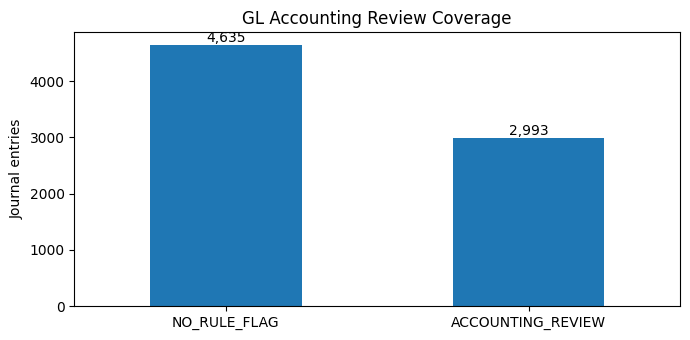

In [66]:
import matplotlib.pyplot as plt

review = (GL_P4[['header_document_id', 'Audit_Status']]
          .drop_duplicates().groupby('Audit_Status').size())
ax = review.reindex(['NO_RULE_FLAG', 'ACCOUNTING_REVIEW'], fill_value=0).plot(
    kind='bar', figsize=(7, 3.5), rot=0)
ax.set(title='GL Accounting Review Coverage', ylabel='Journal entries', xlabel='')
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout(); plt.show()

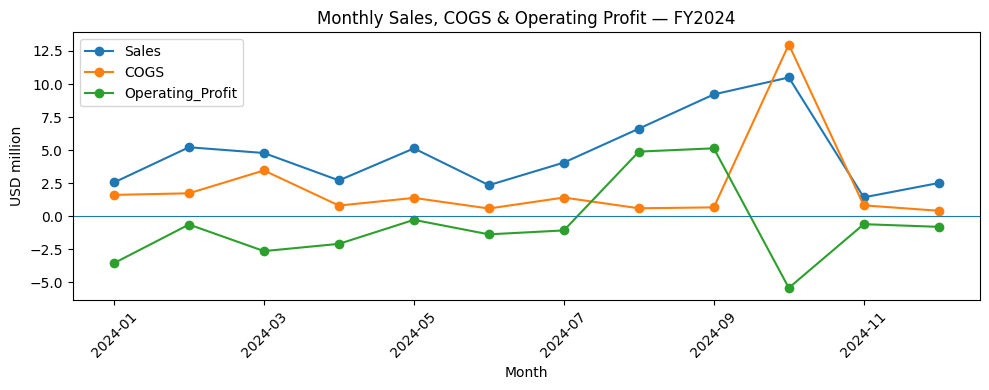

In [67]:
ax = (MONTHLY6[['Sales', 'COGS', 'Operating_Profit']] / 1e6).plot(
    figsize=(10, 4), marker='o')
ax.axhline(0, linewidth=0.8)
ax.set(title='Monthly Sales, COGS & Operating Profit — FY2024',
       xlabel='Month', ylabel='USD million')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

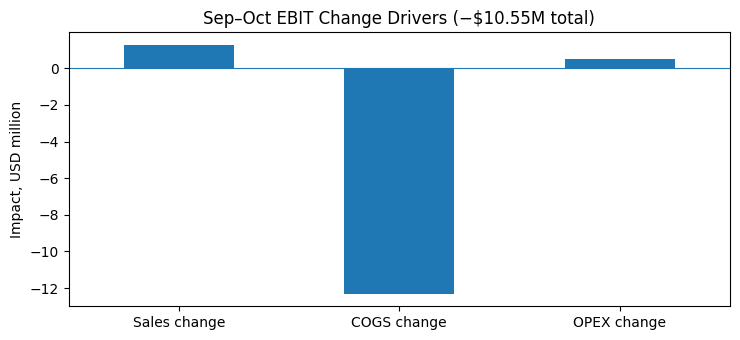

In [68]:
sep, octo = MONTHLY6.loc['2024-09'], MONTHLY6.loc['2024-10']
effects = pd.Series({
    'Sales change': (octo['Sales'] - sep['Sales']) / 1e6,
    'COGS change': -(octo['COGS'] - sep['COGS']) / 1e6,
    'OPEX change': -(octo['OPEX'] - sep['OPEX']) / 1e6
})
ax = effects.plot(kind='bar', figsize=(7.5, 3.5), rot=0)
ax.axhline(0, linewidth=0.8)
ax.set(title='Sep–Oct EBIT Change Drivers (−$10.55M total)', ylabel='Impact, USD million')
plt.tight_layout(); plt.show()

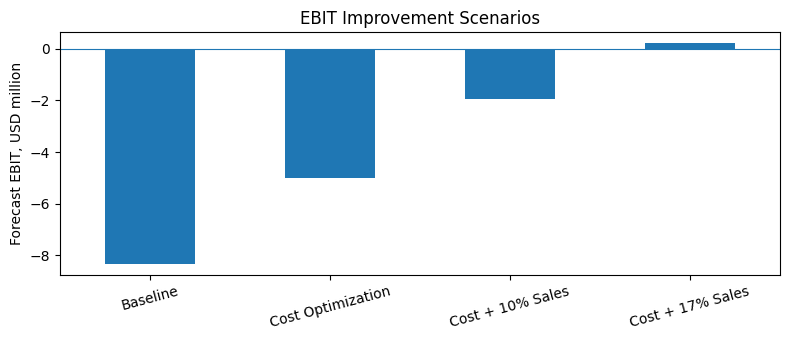

In [69]:
ax = (SCENARIO58.set_index('Scenario')['Forecast_EBIT'] / 1e6).plot(
    kind='bar', figsize=(8, 3.5), rot=15)
ax.axhline(0, linewidth=0.8)
ax.set(title='EBIT Improvement Scenarios', ylabel='Forecast EBIT, USD million', xlabel='')
plt.tight_layout(); plt.show()

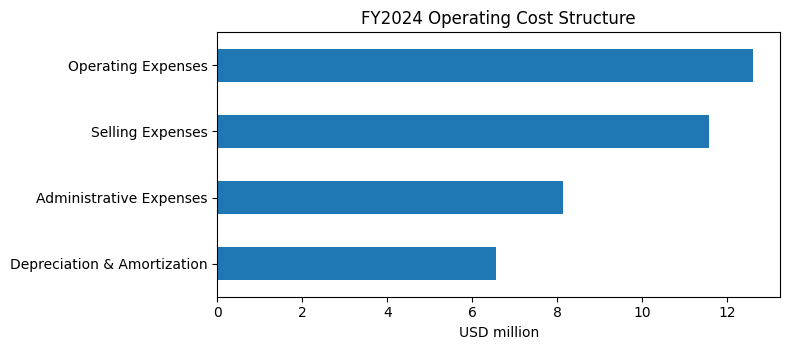

In [70]:
cats = ['Operating Expenses', 'Selling Expenses',
        'Administrative Expenses', 'Depreciation & Amortization']
operating_mix = (PL5[PL5['FS_Category'].isin(cats)]
                 .groupby('FS_Category')['FS_Amount'].sum()
                 .reindex(cats) / 1e6)
ax = operating_mix.sort_values().plot(kind='barh', figsize=(8, 3.6))
ax.set(title='FY2024 Operating Cost Structure', xlabel='USD million', ylabel='')
plt.tight_layout(); plt.show()